# 11 — VCG V4: J-point → T-end, từng bước và toàn bộ cohort

Theo đặc tả **Đặc tả trích T và đánh giá VCG (J-point → T-end).pdf**, 23/10/2026. Notebook tự đọc raw Frank XYZ, dùng lại đúng V1 cho đọc/QC/lọc/QRS/median; thuật toán mới bắt đầu ở T-end. Không cần chạy notebook 05/09/10 trước và không cần script sinh notebook.

**Mặc định:** mọi record trong data/split_manifest.csv (hiện 448 record, 200 bệnh nhân), 30 giây đầu mỗi record. Train/valid/test tách theo bệnh nhân. Mọi lỗi vẫn giữ trong mẫu số. Các hình walkthrough dùng một record; các bảng E0–E7 dùng toàn bộ split tương ứng.

Loop chính **ST-T = XYZ[J:T_end+1]**. T-on chỉ là phụ; pure-T chỉ xuất khi V1/V2 đồng ý onset trong 25 ms. V4 development chạy bốn candidate **V2_offset, V1_threshold, Trapezium, Integral**; fusion cần ≥2 candidate và có method spread. C và V1 tangent không tham gia.

Không có nhãn T ở PTB trong project: accuracy T-end chỉ tính trên tín hiệu tổng hợp, không suy rộng thành sai số người thật. MI/HC chỉ dùng mô tả và E6, không đưa vào delineation hoặc calibration.

## 0. Cách chạy, bản đồ cell và chống leakage

Chọn kernel theo requirements.txt rồi **Restart Kernel → Run All**. Không tự chạy notebook khác. Cell tải dữ liệu chỉ gọi khi bạn bật V4_DOWNLOAD_MISSING.

Thứ tự: manifest/QC → walkthrough → E0/E2/E3/E4 development (train, valid) → E1 synthetic validation → calibration train và kiểm tra valid → **khóa hash** → test một cấu hình cố định → E5/E6/E7 và synthetic holdout. Threshold và model không học từ test. Khi sửa code/config rồi chạy lại, notebook tự thêm protocol hash vào run name nếu tên cũ đang chứa config khác, nên artifact cũ không bị ghi đè.

| Mục | Phạm vi | Sản phẩm |
|---|---|---|
| Walkthrough 1–12 | Một record train cố định | Raw, QC, filter, anchors, beat, QRS/J, từng estimator, loop, feature |
| E0 | Mỗi split × MI/HC × method | T1 coverage/status/failure; F1 coverage; F2 uncertainty |
| E1 | Subject synthetic validation / holdout tách biệt | T2 MAE/bias/missing theo điều kiện |
| E2 | Train/valid để development; test chỉ mô tả cấu hình khóa | T3 QT/QTc Fridericia, regression HC, F3 |
| E3 | Toàn train/valid | T4 từng beat, noise, bootstrap; missing và conditional jitter |
| E4 | Toàn train/valid | T5 endpoint shifts ±5/10/20 ms, feature sensitivity |
| E5 | Development; test chỉ variant khóa trước | T6 từng method, median, bỏ V2/bỏ Trapezium, ST-T/pure-T |
| E6 | Train fit; valid/test predict riêng | T7 confusion, metrics + CI 95% cluster bệnh nhân; accepted/valid; QRS-only |
| E7 | Toàn bộ đã chạy | CSV/PNG/config/hash/lock/test receipt/review queue/F4/F5 |

Mỗi phép thử được checkpoint theo protocol và hash raw của record. Các phép đo runtime được cache là thời gian lần tính đầu. Không chọn method theo AUC E6; không tự tối ưu threshold dựa trên test. Test không chạy E3/E4 hoặc sweep.

In [1]:
# Nếu kernel thiếu package, tự bỏ dấu # rồi restart kernel.
# %pip install -r requirements.txt


## 1. Cấu hình và nguồn đặc tả

Đặt các option trước Run All. Mặc định chạy đầy đủ cohort; không có head(20) hoặc giới hạn beat. Các phép thử E3 gồm mọi beat V1 đã giữ, 15 lần noise và 10 beat bootstrap/record development, nên lần đầu có thể lâu.

Dải QT 250–550 ms là màn kiểm tra rộng, không là chẩn đoán. Calibration train lấy quantile QT và uncertainty, giữ trong guardrail, rồi hiển thị validation mà không tự điều chỉnh. Dải tham chiếu QTc HC 350–450 ms chỉ để mô tả. Các lựa chọn triển khai chưa xác định trong PDF được liệt kê rõ ở phần Trapezium, feature và calibration.

In [2]:
from pathlib import Path
from dataclasses import asdict
from itertools import combinations, product
import copy, hashlib, importlib.metadata, json, os, sys, tempfile, time, uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from scipy.signal import savgol_filter, find_peaks
from scipy.integrate import cumulative_trapezoid
from scipy.stats import linregress
from io import BytesIO

V4_ROOT = next((p.resolve() for p in [Path.cwd(),Path.cwd()/"VCG",*Path.cwd().parents]
                if (p/"vcg_pipeline.py").is_file()),None)
if V4_ROOT is None: raise FileNotFoundError("Mở notebook từ vcg hoặc vcg/VCG.")
if str(V4_ROOT) not in sys.path: sys.path.insert(0,str(V4_ROOT))
from vcg_preprocessing import Config, assess_input_quality, welch_xyz, filter_frequency_response
from vcg_pipeline import (FEATURE_NAMES, load_xyz, preprocess_xyz, detect_qrs_anchors,
    representative_beat, delineate_loops, cut_loop, spatial_speed, project_pca,
    extract_features, flattest_pq, ms_samples, odd_window)
from vcg_t_almeida import (AlmeidaConfig, wavelet_transform, build_t_search_window,
    single_lead_initialization, select_multilead_scale, iterate_tls_boundary, json_safe)
from project_integrity import file_digest

V4_NOTEBOOK = V4_ROOT/"11_VCG_V4_J_Point_T_End.ipynb"
V4_SPEC = V4_ROOT.parent/"Đặc tả trích T và đánh giá VCG (J-point → T-end).pdf"
V4_DATA = V4_ROOT/"content/ptbdb/physionet.org/files/ptbdb/1.0.0"
V4_RUN_NAME = "v4_full_02_signed4"  # đổi tên khi muốn một lần báo cáo test mới
V4_DEMO_ID = "patient104/s0306lre"  # kiểm tra đây là train ở cell manifest
V4_DOWNLOAD_MISSING = False
V4_DEEP_VERIFY = False
V4_REUSE_CACHE = True
V4_RUN_TEST = True
V4_RUN_E3 = True
V4_RUN_E4 = True
V4_RUN_SYNTHETIC = True
V4_RUN_ML = True
V4_SAVE = True
V4_SECONDS = 30.0
V4_NOISE_LEVELS = (0.005,0.01,0.02)
V4_SEEDS = (0,1,2,3,4)
V4_BOOTSTRAPS = 10
V4_CI_REPEATS = 500
V4_SYNTH_SUBJECTS = 12  # mỗi partition, mọi subject × toàn điều kiện
V4_ONSET_AGREEMENT_MS = 25.0
V4_CALIBRATION = dict(uncertainty_quantile=.90, uncertainty_clip_ms=(10.,80.),
    qt_quantiles=(.01,.99), qt_guardrail_ms=(250.,550.), min_train_pairs=20)
V4_PRE = Config(seconds=V4_SECONDS)
V4_WT = AlmeidaConfig()
V4_BASE_METHODS = ("V2_offset","V1_threshold","Trapezium","Integral")
V4_ACTIVE_METHODS = V4_BASE_METHODS  # replaced by locked train/validation selection
V4_METHODS = (*V4_BASE_METHODS,"V4_median","no_Trapezium","no_Integral","no_V2")
V4_VARIANTS = tuple((m,loop) for m in V4_METHODS for loop in ("STT","pure_T"))
V4_PLOTS = {m:plt.get_cmap("tab10")(i) for i,m in enumerate(V4_METHODS)}
V4_TABLES = {}
V4_RAW_HASHES = {}
plt.rcParams.update({"font.family":"DejaVu Sans","figure.dpi":105,"font.size":10})
pd.set_option("display.max_columns",50)

def v4_hash(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(1024*1024),b""):h.update(block)
    return h.hexdigest()

def v4_digest(value):
    return hashlib.sha256(json.dumps(json_safe(value),sort_keys=True,ensure_ascii=False,
                                    allow_nan=False).encode("utf-8")).hexdigest()

def v4_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w",encoding="utf-8",dir=path.parent,
                                     suffix=".tmp",delete=False) as stream:
        json.dump(json_safe(value),stream,ensure_ascii=False,indent=2,allow_nan=False)
        temporary=stream.name
    os.replace(temporary,path)

def v4_show(fig,name):
    with BytesIO() as buffer:
        fig.savefig(buffer,format="png",bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    if V4_SAVE:
        (V4_OUT/"figures").mkdir(parents=True,exist_ok=True)
        fig.savefig(V4_OUT/"figures"/(name+".png"),dpi=160,bbox_inches="tight")
    plt.close(fig)

def v4_table(name,frame,preview=24):
    V4_TABLES[name]=frame.copy()
    print(f"{name}: {len(frame):,} dòng; xem {min(preview,len(frame))} dòng đầu; CSV giữ đủ.")
    display(frame.head(preview))
    if V4_SAVE:
        (V4_OUT/"tables").mkdir(parents=True,exist_ok=True)
        frame.to_csv(V4_OUT/"tables"/(name+".csv"),index=False)

def v4_index(value,n):
    try:return value is not None and np.isfinite(value) and int(value)==value and 0<=value<n
    except (TypeError,ValueError,OverflowError):return False

print("Project:",V4_ROOT,"\nRaw:",V4_DATA,"\nScope: toàn split manifest, 30 giây/record")
display(pd.Series({**asdict(V4_PRE),"onset_agreement_ms":V4_ONSET_AGREEMENT_MS}).to_frame("value"))


Project: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG 
Raw: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\content\ptbdb\physionet.org\files\ptbdb\1.0.0 
Scope: toàn split manifest, 30 giây/record


,value
seconds,30.0
morphology_mode,fir
morphology_design_fs_hz,1000.0
fir_numtaps,401
fir_cutoff_hz,175.0
fir_kaiser_beta,8.0
fir_preserve_hz,150.0
fir_stopband_hz,"(190.0, 200.0)"
notch_mode,auto
notch_hz,50.0


## 2. Manifest, số record/bệnh nhân và fingerprint

resources.json là URL/archive; ptbdb-files.json là tên file/bytes/SHA256; split_manifest.csv là cohort nghiên cứu. JSON không chứa waveform. Kiểm tra patient_id khớp đường dẫn và không vượt qua split. Nhãn chỉ dùng thống kê, không truyền vào hàm tìm T hoặc chọn threshold.

Protocol gồm code notebook (bỏ outputs), ba module V1/V2, đặc tả PDF, config, package và split. Chạy lại cell sau khi sửa code sẽ tạo protocol khác. Checkpoint không chấp nhận median từ code/dữ liệu cũ.

In [3]:
V4_SPLIT=pd.read_csv(V4_ROOT/"data/split_manifest.csv")
V4_SPLIT["split"]=V4_SPLIT["split"].replace({"valid":"val","validation":"val"})
def v4_validate_split(frame):
    cols=["record_id","patient_id","label_name","split"]
    if not set(cols).issubset(frame):raise ValueError("Manifest thiếu cột")
    if frame.empty or frame[cols].isna().any().any():raise ValueError("Manifest rỗng/thiếu giá trị")
    if not frame.record_id.is_unique:raise ValueError("record_id lặp")
    if not frame.split.isin(["train","val","test"]).all():raise ValueError("Split không hợp lệ")
    if not frame.label_name.isin(["MI","HC"]).all():raise ValueError("Label khác MI/HC")
    if not frame.patient_id.eq(frame.record_id.str.split("/").str[0]).all():raise ValueError("patient_id sai")
    if frame.groupby("patient_id").split.nunique().gt(1).any():raise ValueError("PATIENT LEAKAGE")
    if frame.groupby("patient_id").label_name.nunique().gt(1).any():raise ValueError("Patient có label mâu thuẫn")
v4_validate_split(V4_SPLIT)
if not V4_SPEC.is_file():raise FileNotFoundError("Giữ PDF đặc tả tại thư mục cha VCG: "+str(V4_SPEC))
V4_PROTOCOL=dict(version="v4-jtend-1.1-signed4",spec_sha256=v4_hash(V4_SPEC),
    notebook_source_sha256=file_digest(V4_NOTEBOOK),
    sources={p:v4_hash(V4_ROOT/p) for p in ("vcg_pipeline.py","vcg_preprocessing.py","vcg_t_almeida.py")},
    manifest_sha256=v4_hash(V4_ROOT/"data/split_manifest.csv"),
    files_sha256=v4_hash(V4_ROOT/"data/ptbdb-files.json"),
    resources_sha256=v4_hash(V4_ROOT/"data/resources.json"),
    preprocessing=asdict(V4_PRE),wavelet=asdict(V4_WT),calibration=V4_CALIBRATION,
    seconds=V4_SECONDS,noise_levels=V4_NOISE_LEVELS,seeds=V4_SEEDS,
    bootstrap_repeats=V4_BOOTSTRAPS,ci_repeats=V4_CI_REPEATS,
    synth_subjects=V4_SYNTH_SUBJECTS,onset_tolerance_ms=V4_ONSET_AGREEMENT_MS,
    methods=V4_METHODS,loop_variants=V4_VARIANTS,
    evaluation=dict(E3=V4_RUN_E3,E4=V4_RUN_E4,synthetic=V4_RUN_SYNTHETIC,ML=V4_RUN_ML),
    packages={p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","wfdb","matplotlib","scikit-learn")})
V4_PROTOCOL_ID=v4_digest(V4_PROTOCOL)[:20]
V4_OUT=V4_ROOT/"outputs/vcg_v4"/V4_RUN_NAME
V4_CACHE=V4_ROOT/"outputs/vcg_v4/_cache"/V4_PROTOCOL_ID
if (V4_OUT/"config.json").is_file():
    prior=json.loads((V4_OUT/"config.json").read_text(encoding="utf-8"))
    if v4_digest(prior)!=v4_digest(V4_PROTOCOL):
        # Không ghi đè artifact của protocol cũ; tự tạo run mới theo protocol hash.
        V4_RUN_NAME=f"{V4_RUN_NAME}__{V4_PROTOCOL_ID}"
        V4_OUT=V4_ROOT/"outputs/vcg_v4"/V4_RUN_NAME
        print("Run name cũ chứa protocol khác; chuyển sang:",V4_RUN_NAME)
if V4_SAVE:v4_json(V4_OUT/"config.json",V4_PROTOCOL)
v4_table("input_split_counts",V4_SPLIT.groupby(["split","label_name"]).agg(
    n_attempted=("record_id","size"),n_patients=("patient_id","nunique")).reset_index())
print("Records:",len(V4_SPLIT),"Patients:",V4_SPLIT.patient_id.nunique(),"Protocol:",V4_PROTOCOL_ID)
assert V4_SPLIT.set_index("record_id").loc[V4_DEMO_ID,"split"]=="train","Demo phải thuộc train."


Run name cũ chứa protocol khác; chuyển sang: v4_full_02_signed4__1f9b7cdb377bb449162c
input_split_counts: 6 dòng; xem 6 dòng đầu; CSV giữ đủ.


,split,label_name,n_attempted,n_patients
0,test,HC,17,13
1,test,MI,98,37
2,train,HC,47,31
3,train,MI,216,89
4,val,HC,16,8
5,val,MI,54,22


Records: 448 Patients: 200 Protocol: 1f9b7cdb377bb449162c


### 2A. Kiểm kê file raw, tải nếu còn thiếu

Cell này chỉ kiểm kê record trong manifest nghiên cứu. Mọi file .hea/.dat/.xyz cần tồn tại, kích thước đúng; deep verify hash optional vì đọc vài GB. Reader còn đọc tên file mà header thực sự tham chiếu; cache hash những file đó. Lỗi dữ liệu phát hiện ở cohort vẫn xuất thành dòng unresolved, không loại khỏi mẫu số.

In [4]:
V4_RESOURCES=json.loads((V4_ROOT/"data/resources.json").read_text(encoding="utf-8"))
V4_FILES=json.loads((V4_ROOT/"data/ptbdb-files.json").read_text(encoding="utf-8"))
if V4_DOWNLOAD_MISSING:
    from project_setup import ensure_dataset
    ensure_dataset()
inventory=[]
for rid in V4_SPLIT.record_id:
    for suffix in (".hea",".dat",".xyz"):
        name=rid+suffix;p=V4_DATA/name;info=V4_FILES.get(name)
        exists=p.is_file(); size_ok=bool(exists and info and p.stat().st_size==info["bytes"])
        hash_ok=v4_hash(p)==info["sha256"] if V4_DEEP_VERIFY and size_ok else None
        inventory.append(dict(record_id=rid,path=name,present=exists,size_ok=size_ok,hash_ok=hash_ok))
v4_inventory=pd.DataFrame(inventory)
v4_table("raw_inventory",v4_inventory)
display(v4_inventory.groupby("present").size().rename("files"))
display(v4_inventory[~v4_inventory.size_ok | v4_inventory.hash_ok.eq(False)].head(25))
if not V4_DATA.is_dir():raise FileNotFoundError("Chưa có raw. Bật V4_DOWNLOAD_MISSING, chạy lại cell này.")
print("Raw inventory là preflight; cohort vẫn giữ record lỗi trong mẫu số.")


raw_inventory: 1,344 dòng; xem 24 dòng đầu; CSV giữ đủ.


,record_id,path,present,size_ok,hash_ok
0,patient001/s0010_re,patient001/s0010_re.hea,True,True,None
1,patient001/s0010_re,patient001/s0010_re.dat,True,True,None
2,patient001/s0010_re,patient001/s0010_re.xyz,True,True,None
3,patient001/s0014lre,patient001/s0014lre.hea,True,True,None
4,patient001/s0014lre,patient001/s0014lre.dat,True,True,None
5,patient001/s0014lre,patient001/s0014lre.xyz,True,True,None
6,patient001/s0016lre,patient001/s0016lre.hea,True,True,None
7,patient001/s0016lre,patient001/s0016lre.dat,True,True,None
8,patient001/s0016lre,patient001/s0016lre.xyz,True,True,None
9,patient002/s0015lre,patient002/s0015lre.hea,True,True,None


present
True    1344
Name: files, dtype: int64

,record_id,path,present,size_ok,hash_ok


Raw inventory là preflight; cohort vẫn giữ record lỗi trong mẫu số.


## 3. Bộ hàm: raw → median, giữ nguyên V1

Cell định nghĩa không xử lý cohort. load_xyz chỉ đọc các kênh Frank XYZ, lấy fs/đơn vị từ header. preprocess_xyz, detect_qrs_anchors, representative_beat, delineate_loops được import nguyên bản. J-point và T-peak lấy từ V1; không chỉnh QRS detector/filter để làm V4 có kết quả đẹp hơn.

**Sửa lỗi accepted=0:** thông báo PSD “heuristic chưa kiểm chứng” và thích nghi thuật toán nằm ở info_flags; chúng không tự làm record thất bại. data-quality flags thực sự, RR không đều, QRS/PQ không ổn nằm ở error_flags và được báo riêng. Không đổi cờ trong module V1; chỉ phân loại ở adapter V4.

In [5]:
def v4_state(rid):
    started=time.perf_counter()
    raw=load_xyz(V4_DATA/rid,V4_SECONDS)
    morph,detection,prep=preprocess_xyz(raw["xyz"],raw["fs"],V4_PRE,return_diagnostics=True)
    detector=detect_qrs_anchors(morph,detection,raw["fs"],V4_PRE)
    rep=representative_beat(morph,detector["anchors"],raw["fs"],V4_PRE,quality=prep["input_quality"])
    state=dict(record_id=rid,raw=raw,fs=raw["fs"],morph=morph,detection=detection,
               prep=prep,detector=detector,rep=rep,shared_seconds=time.perf_counter()-started)
    return state

def v4_state_flags(st,q):
    errors=[];info=list(st.get("prep",{}).get("warnings",[]))
    detector_flags=st.get("detector",{}).get("flags",[])
    rep_flags=st["rep"].get("quality_flags",[])
    if "rr_irregular" in detector_flags:errors.append("rr_irregular")
    info.extend(f for f in detector_flags if f!="rr_irregular")
    input_quality=st.get("prep",{}).get("input_quality",{})
    if input_quality.get("invalid_samples",0):errors.append("input_qc_fail")
    # Các beat retained đã qua mask V1; cờ data-level dưới đây vẫn yêu cầu xem lại.
    # Cờ morphology/PQ là review/info; PDF không cho phép chúng tự làm accepted=0.
    info.extend(rep_flags)
    for f in q["flags"]:
        if f in ("qrs_on_not_found","qrs_off_not_found"):errors.append(f)
        else:info.append("V1_aux:"+f)
    if st["rep"]["n_used"]<5:errors.append("few_representative_beats")
    return sorted(set(errors)),sorted(set(info))

def v4_signed_signal(rep,fs,q):
    # Signed scalar for Trapezium/Integral. The projection window is fixed
    # around the magnitude peak; it never uses a candidate T-end.
    xyz=np.asarray(rep["xyz"],float);n=len(xyz);peak=q.get("t_peak")
    result=dict(y=None,baseline=None,u=None,peak_used=peak,sigma_pq=np.nan,
                flags=[],reason="",search_window=None,candidate_window=None)
    if not v4_index(peak,n):result["reason"]="t_peak_not_found";return result
    half=max(1,int(round(60e-3*fs)));lo=max(0,int(peak)-half);hi=min(n,int(peak)+half+1)
    centered=xyz[lo:hi]-np.median(xyz[lo:hi],axis=0)
    if len(centered)<5:result["reason"]="projection_window_too_short";return result
    _,_,vh=np.linalg.svd(centered,full_matrices=False);u=np.asarray(vh[0],float)
    pq0,pq1=rep.get("pq",(0,0));tp=q.get("tp")
    if tp is not None and tp[1]>tp[0] and tp[0]>=0 and tp[1]<=n:
        b=np.median(xyz[tp[0]:tp[1]],axis=0);base_source="TP"
    elif pq1>pq0:
        b=np.median(xyz[pq0:pq1],axis=0);base_source="PQ_fallback";result["flags"].append("baseline_tp_missing")
    else:
        result["reason"]="baseline_unavailable";return result
    if np.dot(u,xyz[int(peak)]-b)<0:u=-u
    y=np.asarray((xyz-b)@u,float);win=max(5,int(round(21e-3*fs))|1)
    win=min(win,n if n%2 else n-1)
    if win<5:result["reason"]="smoothing_window_too_short";return result
    ys=savgol_filter(y,win,3,mode="interp")
    pqseg=ys[pq0:pq1] if pq1>pq0 else np.array([]);pqy=pqseg-np.median(pqseg) if len(pqseg) else pqseg
    sigma=max(float(1.4826*np.median(np.abs(pqy))) if len(pqy) else np.nan,1e-9)
    amp=float(ys[int(peak)])
    result.update(y=ys,baseline=float(np.dot(u,b)),u=u,sigma_pq=sigma,baseline_source=base_source)
    if pq1>pq0:
        pq_base=np.median(xyz[pq0:pq1],axis=0);offset=abs(float(np.dot(u,b-pq_base)))
        result["baseline_offset_mV"]=offset
        if offset>max(5*sigma,.02):result["flags"].append("baseline_offset")
    qrs_on=q.get("qrs_on");anchor=rep.get("anchor");rr=rep.get("rr_seconds")
    if not v4_index(qrs_on,n) or not np.isfinite(rr):result["reason"]="search_window_unavailable";return result
    search_hi=min(n-1,int(round(qrs_on+0.600*fs)),int(round(anchor+0.70*rr*fs-0.030*fs)))
    base_lo=int(peak+round(.020*fs));cand_lo=int(peak+round(.030*fs))
    result.update(search_window=(base_lo,search_hi),candidate_window=(cand_lo,search_hi))
    if amp<4*sigma:result["flags"].append("t_amplitude_low");result["reason"]="t_amplitude_low";return result
    if search_hi<=cand_lo:result["reason"]="t_search_too_short";return result
    # For biphasic/multilobe T, y-methods use the last resolved lobe.
    lo2=max(base_lo,qrs_on+ms_samples(20,fs));section=np.abs(ys-np.median(ys[pq0:pq1]))
    peaks,props=find_peaks(section[lo2:search_hi+1],prominence=max(3*sigma,.05*max(amp,1e-9)),distance=ms_samples(40,fs))
    peaks=peaks+lo2
    if len(peaks)>1:
        result["flags"].append("t_multilobe");result["peak_used"]=int(peaks[-1])
    return result

def v4_v2_offset(rep,fs,q):
    # T-end không yêu cầu nhánh onset thành công; không đọc q['t_on']/q['t_off'].
    n=len(rep["xyz"])
    result=dict(end=None,onset=None,reason="",flags=[],trace={})
    if not all(v4_index(q.get(k),n) for k in ("qrs_on","qrs_off")):
        result["reason"]="qrs_off_not_found";return result
    try:
        window=build_t_search_window(n,fs,rep["anchor"],q["qrs_off"],rep["rr_seconds"],V4_WT)
        wt,bank=wavelet_transform(rep["xyz"],fs,V4_WT)
        rms=(int(rep["anchor"]),min(n-1,int(rep["anchor"]+round(rep["rr_seconds"]*fs))))
        sl=single_lead_initialization(wt,window,fs,rms,V4_WT)
        usable=[s for s in sl if s["wave_detected"]]
        result["trace"].update(window=window,rms=rms,single_leads=sl,bank=bank)
        if not usable:
            result["reason"]="INITIALIZATION_FAILED_all_three_single_leads_unresolved";return result
        scale=select_multilead_scale(sl)
        initial=(min(r["search_start"] for r in usable),max(r["search_end"] for r in usable))
        off=iterate_tls_boundary(wt,scale,initial,window,rms,fs,"t_off",V4_WT)
        on=iterate_tls_boundary(wt,scale,initial,window,rms,fs,"t_on",V4_WT)
        result.update(end=off["sample"],onset=on["sample"],flags=list(off["review_flags"]))
        peak=q.get("t_peak");common=q.get("t_search",window);candidate_window=(max(window[0],common[0],int(peak)+round(.030*fs)) if v4_index(peak,n) else max(window[0],common[0]),min(window[1],common[1]))
        result["trace"].update(selected_scale=scale,initial=initial,offset=off,onset=on,wavelets=wt,
                                 search_window=window,candidate_window=candidate_window,peak_used=peak)
        if off["sample"] is None:result["reason"]=off["stop_reason"] or "offset_unresolved"
        elif not q["qrs_off"]<off["sample"]<n:
            result.update(end=None,reason="offset_order_or_domain")
        # Nguyên nhân missing onset chỉ là thông tin phụ, không xóa offset hợp lệ.
        result["trace"]["onset_stop_reason"]=on["stop_reason"]
    except (ValueError,RuntimeError,np.linalg.LinAlgError) as exc:
        result.update(reason=type(exc).__name__+": "+str(exc))
    return result

def v4_trapezium(rep,fs,q,scalar=None):
    # Signed y(t) equal-area construction; keep the trace for ablation.
    result=dict(end=None,reason="",flags=[],trace={})
    scalar=v4_signed_signal(rep,fs,q) if scalar is None else scalar
    y=scalar.get("y");peak=scalar.get("peak_used");n=len(rep["xyz"])
    if not v4_index(peak,n):result["reason"]="t_peak_not_found";return result
    if y is None or not v4_index(peak,n):result["reason"]=scalar.get("reason","signed_signal_unresolved");result["flags"]=list(scalar.get("flags",[]));return result
    lo,b=scalar["candidate_window"];base=float(scalar["baseline"])
    derivative=np.gradient(y,1/fs)
    a=int(peak+np.argmin(derivative[peak:b+1]))
    if not peak<=a<b or derivative[a]>=-1e-9:
        result["reason"]="no_terminal_downslope";return result
    corrected=np.maximum(y[a:b+1]-base,0.)
    integral=float(np.trapezoid(corrected,dx=1/fs))
    h0,h1=float(corrected[0]),float(corrected[-1])
    if h0+h1<=1e-9 or integral<=0:
        result["reason"]="degenerate_area";return result
    continuous=a+2*integral*fs/(h0+h1)
    end=int(np.floor(continuous+.5))
    result["trace"]=dict(a=a,b=b,baseline=base,area_mV_s=integral,h0_mV=h0,h1_mV=h1,
        continuous_end=continuous,search_window=(lo,b),peak_used=peak,
        trapezium_area_mV_s=.5*(h0+h1)*(continuous-a)/fs,
        **{k:v for k,v in scalar.items() if k in ("u","sigma_pq","baseline_source","baseline_offset_mV")})
    result["flags"]=list(scalar.get("flags",[]))
    if b-end<=max(1,ms_samples(15,fs)):result["flags"].append("t_end_at_window_edge")
    if not peak+round(.030*fs)<=end<=b:result["reason"]="area_endpoint_outside_candidate_domain";return result
    result["end"]=end;return result

def v4_select_t_peak(rep,fs,q):
    # V4 T-peak window: J+20 ms to min(QRS-on+600 ms, anchor+70%RR-30 ms).
    out=dict(q=dict(q),peak=None,flags=[])
    n=len(rep["xyz"]);qrs_off=q.get("qrs_off");qrs_on=q.get("qrs_on")
    if not all(v4_index(v,n) for v in (qrs_on,qrs_off)) or qrs_on>=qrs_off:out["flags"]=["t_peak_not_resolved"];return out
    lo=int(qrs_off+round(.020*fs));hi=min(n-1,int(round(qrs_on+.600*fs)),
        int(round(rep["anchor"]+.70*rep["rr_seconds"]*fs-.030*fs)))
    mag=np.asarray(q["t_magnitude"],float);pq0,pq1=rep["pq"];pq=mag[pq0:pq1]
    noise=max(float(1.4826*np.median(np.abs(pq-np.median(pq)))) if len(pq) else 1e-6,1e-6)
    out["q"].update(t_search=(lo,hi),t_peak=None)
    if hi-lo<ms_samples(100,fs):out["flags"]=["t_search_too_short"];return out
    peaks,props=find_peaks(mag[lo:hi+1],prominence=max(4*noise,.015*max(mag[qrs_on:qrs_off+1])),distance=ms_samples(40,fs))
    peaks=peaks+lo;valid=(peaks>=lo)&(peaks<=hi)
    if not valid.any():out["flags"]=["t_peak_not_resolved"];return out
    local=np.flatnonzero(valid);pick=int(local[np.argmax(props["prominences"][local])]);peak=int(peaks[pick])
    out["q"]["t_peak"]=peak
    significant=peaks[props["prominences"]>=.35*props["prominences"][pick]]
    if len(significant)>1:out["flags"]=["t_multilobe"];out["q"]["t_peak_lobes"]=significant.tolist()
    return out

def v4_threshold_candidate(rep,fs,q):
    mag=np.asarray(q.get("t_magnitude"),float);peak=q.get("t_peak");tp=q.get("tp");n=len(mag)
    if not v4_index(peak,n):return None,"t_peak_not_resolved",{}
    base=float(q.get("t_end_baseline",np.nan));pq0,pq1=rep["pq"];pq=mag[pq0:pq1]
    if not np.isfinite(base):return None,"baseline_unavailable",{}
    noise=max(float(1.4826*np.median(np.abs(pq-np.median(pq)))) if len(pq) else 1e-6,1e-6)
    threshold=base+max(3*noise,V4_PRE.t_fraction*max(mag[int(peak)]-base,0.))
    hi=q.get("t_search",(0,n-1))[1];start=min(hi-1,int(peak)+round(.030*fs));run=max(1,ms_samples(V4_PRE.quiet_t_ms,fs));count=0;end=None
    for i in range(start,max(start,hi)+1):
        count=count+1 if mag[i]<=threshold else 0
        if count>=run:end=i-run+1;break
    return end,("" if end is not None else "threshold_no_baseline_return"),dict(baseline=base,threshold=threshold,search_window=(start,hi),peak_used=peak)

def v4_integral(rep,fs,q,scalar=None):
    # First point at which 95% of positive post-peak area accumulates.
    # The explicit quantile avoids the trivial maximum at window end.
    result=dict(end=None,reason="",flags=[],trace={})
    scalar=v4_signed_signal(rep,fs,q) if scalar is None else scalar
    y=scalar.get("y");peak=scalar.get("peak_used");n=len(rep["xyz"])
    if y is None or not v4_index(peak,n):result["reason"]=scalar.get("reason","signed_signal_unresolved");result["flags"]=list(scalar.get("flags",[]));return result
    lo,hi=scalar["candidate_window"];base=float(scalar["baseline"]);z=np.maximum(y[peak:hi+1]-base,0.)
    cumulative=np.r_[0.,cumulative_trapezoid(z,dx=1/fs)];total=float(cumulative[-1])
    if total<=0:result["reason"] = "degenerate_area";return result
    target=.95*total;end=int(peak+np.searchsorted(cumulative,target,side="left"))
    result["trace"]=dict(search_window=(lo,hi),peak_used=peak,baseline=base,area_mV_s=total,
        area_target_fraction=.95,area_target_mV_s=target,
        **{k:v for k,v in scalar.items() if k in ("u","sigma_pq","baseline_source","baseline_offset_mV")})
    result["flags"]=list(scalar.get("flags",[]))
    if hi-end<=max(1,ms_samples(15,fs)):result["flags"].append("t_end_at_window_edge")
    if not peak+round(.030*fs)<=end<=hi:result["reason"] = "integral_endpoint_outside_candidate_domain";return result
    result["end"]=end;return result

def v4_estimate(st):
    # Chỉ signal state; không nhận diagnosis/label/split/threshold đã fit.
    rep,fs=st["rep"],st["fs"];q0=delineate_loops(rep,fs,V4_PRE)
    peak_result=v4_select_t_peak(rep,fs,q0);q=peak_result["q"];q["flags"]=sorted(set(f for f in q.get("flags",[]) if f!="t_peak_not_resolved")|set(peak_result["flags"]))
    n=len(rep["xyz"]); errors,info=v4_state_flags(st,q)
    if not v4_index(q.get("qrs_off"),n):errors.append("qrs_off_not_found")
    if not v4_index(q.get("t_peak"),n):errors.append("t_peak_not_found")
    started=time.perf_counter();wave=v4_v2_offset(rep,fs,q)
    wt_seconds=time.perf_counter()-started
    scalar=v4_signed_signal(rep,fs,q);info.extend("signed:"+f for f in scalar.get("flags",[]))
    started=time.perf_counter();trap=v4_trapezium(rep,fs,q,scalar)
    trap_seconds=time.perf_counter()-started
    started=time.perf_counter();integral=v4_integral(rep,fs,q,scalar)
    integral_seconds=time.perf_counter()-started
    threshold_end,threshold_reason,threshold_trace=v4_threshold_candidate(rep,fs,q)
    threshold=dict(end=threshold_end,onset=q.get("t_on"),reason=threshold_reason,flags=[],trace=threshold_trace)
    for f in ("tp_not_quiet","tp_window_too_short","t_low_amplitude"):
        if f in q["flags"]:threshold["flags"].append(f)
    threshold["trace"].update(search_window=scalar.get("search_window"),candidate_window=scalar.get("candidate_window"),peak_used=q.get("t_peak"))
    threshold["flags"] += list(scalar.get("flags",[]))
    methods={"V2_offset":wave,"V1_threshold":threshold,"Trapezium":trap,"Integral":integral}
    for m,r in methods.items():
        candidate=r["end"];trace=r.setdefault("trace",{});peak_used=trace.get("peak_used",q.get("t_peak"));window=trace.get("candidate_window",scalar.get("candidate_window"))
        edge=False
        if candidate is not None and window is not None:edge=(window[1]-candidate)<=max(1,ms_samples(15,fs))
        if edge:r["flags"].append("t_end_at_window_edge")
        if candidate is not None and not (v4_index(candidate,n) and v4_index(peak_used,n) and
                                          q["qrs_off"]<peak_used< candidate and candidate>=peak_used+round(.030*fs) and
                                          window is not None and window[0]<=candidate<=window[1] and not edge):
            r.update(end=None,reason="t_end_before_peak_or_outside_candidate_window")
    return dict(q=q,methods=methods,error_flags=sorted(set(errors)),info_flags=info,
                runtime={"V2_offset":wt_seconds,"Trapezium":trap_seconds,"Integral":integral_seconds,"V1_threshold":0.},
                signed=scalar,
                shared_seconds=st.get("shared_seconds",0.))

def v4_fuse(estimated,members):
    available=[(m,estimated["methods"][m]["end"]) for m in members
               if estimated["methods"][m]["end"] is not None]
    if len(available)<2:return dict(end=None,uncertainty_ms=np.nan,voters=[m for m,_ in available])
    values=np.array([v for _,v in available],dtype=float)
    return dict(end=int(np.floor(np.median(values)+.5)),
                uncertainty_ms=float(np.ptp(values)*1000/estimated["fs"]),
                voters=[m for m,_ in available])

def v4_endpoints(st,est):
    est=dict(est,fs=st["fs"]);rows={}
    for m in V4_BASE_METHODS:
        r=est["methods"][m]
        rows[m]=dict(end=r["end"],uncertainty_ms=np.nan,voters=[m] if r["end"] is not None else [])
    active=tuple(V4_ACTIVE_METHODS)
    for method,members in (("V4_median",active),
                           ("no_Trapezium",tuple(m for m in V4_BASE_METHODS if m!="Trapezium")),
                           ("no_Integral",tuple(m for m in V4_BASE_METHODS if m!="Integral")),
                           ("no_V2",tuple(m for m in V4_BASE_METHODS if m!="V2_offset"))):
        rows[method]=v4_fuse(est,members)
    return rows


### 3A. Trapezium: công thức cụ thể, không ngầm coi là bản chuẩn của một bài báo

PDF chỉ nói cân bằng diện tích, không xác định các đỉnh/hệ phương trình. V4 triển khai một biến thể nghiên cứu trên magnitude đã làm mượt V1:

1. Tạo signed scalar y(t) bằng hướng SVD trong cửa sổ cố định peak ±60 ms; baseline là vector TP 25 ms, fallback PQ có cờ.
2. Cửa sổ candidate là peak+30 ms đến min(qrs_on+600 ms, anchor+70%RR−30 ms). Candidate sát mép 15 ms bị loại.
3. Trapezium dùng diện tích tích phân của y dương trên sườn xuống và nghiệm **T_end = a + 2I/(h0+h1)**. Integral dùng mốc tích lũy 95% diện tích dương sau peak; quantile được ghi rõ để tránh nghiệm tầm thường ở cuối cửa sổ.
4. Biên độ peak <4σ_PQ, baseline offset lớn, multilobe và edge đều được ghi cờ; không clip/fallback. Hai method mới là operationalization cần kiểm tra với công thức bài gốc trước khi gọi là tái hiện nguyên bản.

Công thức dùng tích phân trên khoảng [a,b] cố định, tránh phương trình tầm thường “tích phân bằng hình thang tại chính hai điểm kề nhau”. Bằng nhau về diện tích là tính chất xây dựng, **không chứng minh đúng T-end sinh lý**. Các voter vẫn dùng chung median/QRS/peak nên không độc lập thống kê; signed Trapezium/Integral chỉ là hai operationalization khác nhau. Uncertainty max–min không là confidence interval. E1 phải phơi bày bias trên nhiều hình dạng, kể cả hình dạng mà equal-area không phù hợp.

V2 chỉ đòi offset, ghi lại cả failure_reason, single-lead, TLS và nguyên nhân onset; onset thất bại không xóa offset. Các phép thích nghi wavelet 250 Hz → fs hiện có giữ nguyên như V2, chưa là bản tái hiện bit-exact Almeida.

## 4. Feature và phân loại trạng thái

ST-T main dùng J→T-end, tên cột T_* trong 12 feature cũ vẫn được giữ để so schema nhưng **được hiểu là đoạn ST-T**. Cột loop_variant ghi rõ STT hay pure_T. Area và Arc dùng PCA2D; MaxVec là norm XYZ; velocity lấy đạo hàm toàn median rồi mới cắt. QRS nguyên V1.

Bổ sung T_Arc, góc giữa vector diện tích QRS và ST-T, tích phân VG = ∫QRS XYZdt + ∫ST-T XYZdt (mV·s), độ lớn VG, hướng vector diện tích T (azimuth atan2(Y,X), elevation atan2(Z,√(X²+Y²))). Đây là **SVG proxy trên median PQ-centered**, không khẳng định ventricular gradient chuẩn lâm sàng. Góc/hướng không xác định khi vector gần 0 được NaN.

accepted: có end hợp lệ, QT trong ngưỡng khóa, uncertainty ≤ ngưỡng nếu là fusion, không error_flags. needs_review: có end nhưng fail screening. unresolved: thiếu peak/QRS/end hoặc sai thứ tự. Single-method ablation không có uncertainty (NaN), không gán 0 để giả vờ chắc chắn. Pure-T thiếu onset đồng thuận vẫn giữ dòng nhưng không feature T.

In [6]:
V4_EXTRA_FEATURES=("T_Arc","Spatial_QRS_T_Angle_deg","VG_X_mVs","VG_Y_mVs","VG_Z_mVs",
                   "VG_Magnitude_mVs","T_Axis_Azimuth_deg","T_Axis_Elevation_deg")
V4_ALL_FEATURES=tuple(FEATURE_NAMES)+V4_EXTRA_FEATURES
V4_T_FEATURES=tuple(f for f in V4_ALL_FEATURES if f.startswith("T_") or f.startswith("VG_")
                     or f=="Spatial_QRS_T_Angle_deg")
V4_PROVISIONAL=dict(uncertainty_ms=25.,qt_min_ms=250.,qt_max_ms=550.)

def v4_features(st,q,start,end):
    xyz=st["rep"]["xyz"];fs=st["fs"];n=len(xyz);speed=spatial_speed(xyz,fs,V4_PRE)
    q0,q1=q.get("qrs_on"),q.get("qrs_off")
    qloop=cut_loop(xyz,q0,q1) if all(v4_index(v,n) for v in (q0,q1)) else None
    tloop=cut_loop(xyz,start,end) if all(v4_index(v,n) for v in (start,end)) else None
    features=extract_features(qloop,tloop,fs,V4_PRE,speeds={
        "QRS":speed[q0:q1+1] if qloop is not None else None,
        "T":speed[start:end+1] if tloop is not None else None})
    features.update(dict.fromkeys(V4_EXTRA_FEATURES,np.nan))
    p=project_pca(tloop) if tloop is not None else None
    if p is not None:features["T_Arc"]=p["arc"]
    if qloop is not None and tloop is not None:
        qa=np.trapezoid(qloop,dx=1/fs,axis=0);ta=np.trapezoid(tloop,dx=1/fs,axis=0)
        vg=qa+ta
        features.update(dict(zip(("VG_X_mVs","VG_Y_mVs","VG_Z_mVs"),vg)))
        features["VG_Magnitude_mVs"]=float(np.linalg.norm(vg))
        if min(np.linalg.norm(qa),np.linalg.norm(ta))>1e-9:
            features["Spatial_QRS_T_Angle_deg"]=float(np.degrees(np.arccos(np.clip(
                np.dot(qa,ta)/(np.linalg.norm(qa)*np.linalg.norm(ta)),-1,1))))
        if np.linalg.norm(ta)>1e-9:
            features["T_Axis_Azimuth_deg"]=float(np.degrees(np.arctan2(ta[1],ta[0])))
            features["T_Axis_Elevation_deg"]=float(np.degrees(np.arctan2(ta[2],np.hypot(ta[0],ta[1]))))
    return features

def v4_rows(st,est,screen):
    rep,fs=st["rep"],st["fs"];q=est["q"];n=len(rep["xyz"]);out=[]
    endpoints=v4_endpoints(st,est)
    v1_on=q.get("t_on");v2_on=est["methods"]["V2_offset"].get("onset")
    onset_ok=all(v4_index(v,n) for v in (v1_on,v2_on)) and abs(v1_on-v2_on)*1000/fs<=V4_ONSET_AGREEMENT_MS
    onset=int(np.floor((v1_on+v2_on)/2+.5)) if onset_ok else None
    voter_values={m:est["methods"][m].get("end") for m in V4_BASE_METHODS}
    u=est.get("signed",{}).get("u")
    for method,ep in endpoints.items():
        end=ep["end"];q0,q1,peak=q.get("qrs_on"),q.get("qrs_off"),q.get("t_peak")
        valid=all(v4_index(v,n) for v in (q0,q1,peak,end)) and q0<rep["anchor"]<q1<peak<end
        flags=list(est["error_flags"]);info=list(est["info_flags"])
        if not valid:flags.append("t_end_unresolved_or_invalid_order")
        qt=(end-q0)*1000/fs if valid else np.nan
        if valid and not screen["qt_min_ms"]<=qt<=screen["qt_max_ms"]:flags.append("qt_implausible")
        if valid and np.isfinite(ep["uncertainty_ms"]) and ep["uncertainty_ms"]>screen["uncertainty_ms"]:
            flags.append("uncertainty_high")
        for member in ep["voters"]:
            flags.extend(member+":"+f for f in est["methods"][member]["flags"])
        status="unresolved" if not valid else "needs_review" if flags else "accepted"
        for loop in ("STT","pure_T"):
            start=q1 if loop=="STT" else onset
            loop_valid=bool(valid and v4_index(start,n) and q1<=start<peak<end)
            accepted=bool(status=="accepted" and loop_valid)
            loop_flags=flags+([] if loop=="STT" or loop_valid else ["onset_agreement_missing_or_invalid"])
            features=v4_features(st,q,start if loop_valid else None,end if loop_valid else None)
            row=dict(record_id=st["record_id"],patient_id=st["record_id"].split("/")[0],
                method=method,loop_variant=loop,protocol_id=V4_PROTOCOL_ID,has_median=True,
                has_qrs=all(v4_index(v,n) for v in (q0,q1)),has_t_peak=v4_index(peak,n),
                valid_end=bool(valid),loop_valid=loop_valid,status=status,accepted=accepted,
                uncertainty_ms=ep["uncertainty_ms"],votes=len(ep["voters"]),n_valid=len(ep["voters"]),voters=";".join(ep["voters"]),
                voter_V2_offset_sample=voter_values.get("V2_offset"),voter_V1_threshold_sample=voter_values.get("V1_threshold"),
                voter_Trapezium_sample=voter_values.get("Trapezium"),voter_Integral_sample=voter_values.get("Integral"),
                u_x=(float(u[0]) if u is not None else np.nan),u_y=(float(u[1]) if u is not None else np.nan),
                u_z=(float(u[2]) if u is not None else np.nan),sigma_pq=(est.get("signed",{}).get("sigma_pq",np.nan)),
                qrs_on_sample=q0,j_sample=q1,t_peak_sample=peak,t_end_sample=end,
                t_on_sample=onset,onset_agreement=bool(onset_ok),fs_hz=fs,anchor=rep["anchor"],
                t_end_ms=(end-rep["anchor"])*1000/fs if valid else np.nan,
                t_peak_ms=(peak-rep["anchor"])*1000/fs if v4_index(peak,n) else np.nan,
                j_ms=(q1-rep["anchor"])*1000/fs if v4_index(q1,n) else np.nan,
                qt_ms=qt,qtc_fridericia_ms=qt/rep["rr_seconds"]**(1/3) if valid else np.nan,
                rr_s=rep["rr_seconds"],n_used=rep["n_used"],n_excluded=rep["n_excluded"],
                error_flags=";".join(sorted(set(loop_flags))),info_flags=";".join(info),
                failure_reason=est["methods"][method]["reason"] if method in est["methods"] else "",
                shared_seconds=st.get("shared_seconds",0.),
                feature_complete=bool(np.isfinite([features[f] for f in FEATURE_NAMES]).all()),
                signal_sha256=hashlib.sha256(np.ascontiguousarray(rep["xyz"],dtype="<f8").tobytes()).hexdigest(),
                **features)
            out.append(row)
    return out

def v4_failure_rows(rid,error):
    rows=[]
    for m,loop in V4_VARIANTS:
        row=dict.fromkeys((*V4_ALL_FEATURES,"uncertainty_ms","qt_ms","qtc_fridericia_ms","rr_s",
            "t_end_ms","t_peak_ms","j_ms","qrs_on_sample","j_sample","t_peak_sample",
            "t_end_sample","t_on_sample","fs_hz","anchor","n_used","n_excluded","shared_seconds"),np.nan)
        row.update(record_id=rid,patient_id=rid.split("/")[0],method=m,loop_variant=loop,
            protocol_id=V4_PROTOCOL_ID,has_median=False,has_qrs=False,has_t_peak=False,
            valid_end=False,loop_valid=False,status="unresolved",accepted=False,votes=0,voters="",
            onset_agreement=False,error_flags="input_qc_fail;pipeline_error",
            info_flags="",failure_reason=error,feature_complete=False,signal_sha256=None)
        rows.append(row)
    return rows


## 5. Checkpoint và bộ đánh giá E0/E2

Cache theo hash code/config/packages và raw .hea + các file mà header tham chiếu. Hai lần đọc cùng file trong một phiên dùng hash đã tính; nếu bạn thay raw trong lúc kernel chạy, restart kernel. Lỗi không ghi checkpoint thành công. Median/beat cache lưu riêng, giữ các cờ nguồn, không sửa dữ liệu V1/V2/V3.

T1 mỗi split × label × method × loop: n_attempted là **mọi record trong split/label**, dù median/peak/end có thiếu. T3 báo QT/QTc quantile trên các ca có end; số đo QTc luôn đi cùng n_measured. E2 HC reference không dùng để chọn phương pháp dựa nhãn. Regression QT~RR là mô tả, không hiệu chỉnh model theo test. E1 MAE → E3 jitter → E0 coverage chỉ chọn 3 voter trên train/validation; danh sách được ghi vào lock trước test.

In [7]:
def v4_rawstamp(rid):
    if rid not in V4_RAW_HASHES:
        import wfdb
        record=V4_DATA/rid;header=wfdb.rdheader(str(record))
        files=[record.with_suffix(".hea")]+[record.parent/name for name in sorted(set(header.file_name))]
        V4_RAW_HASHES[rid]=v4_digest({str(p.relative_to(V4_DATA)):v4_hash(p) for p in files})
    return V4_RAW_HASHES[rid]

def v4_cache(rid,stage,compute,signature=None):
    identity=dict(protocol=V4_PROTOCOL_ID,raw=v4_rawstamp(rid),signature=signature)
    p=V4_CACHE/stage/(rid.replace("/","_")+".json")
    if V4_REUSE_CACHE and p.is_file():
        saved=json.loads(p.read_text(encoding="utf-8"))
        if saved.get("identity")==json_safe(identity):return saved["result"],True
    value=compute()
    if V4_REUSE_CACHE:v4_json(p,dict(identity=identity,result=value))
    return value,False

def v4_cached_state(rid):
    folder=V4_CACHE/"median";stem=rid.replace("/","_");p=folder/(stem+".json");npz=folder/(stem+".npz")
    identity=dict(protocol=V4_PROTOCOL_ID,raw=v4_rawstamp(rid))
    if V4_REUSE_CACHE and p.is_file() and npz.is_file():
        meta=json.loads(p.read_text(encoding="utf-8"))
        if meta["identity"]==identity and v4_hash(npz)==meta["npz_sha256"]:
            with np.load(npz,allow_pickle=False) as a:
                rep=dict(meta["rep"],xyz=a["xyz"].copy(),beats=a["beats"].copy(),
                    time_ms=a["time_ms"].copy(),used_samples=a["used_samples"].copy(),
                    beat_qc=pd.DataFrame(meta["beat_qc"]))
            return dict(record_id=rid,fs=meta["fs"],rep=rep,prep=meta["prep"],
                        detector=meta["detector"],shared_seconds=meta["shared_seconds"])
    st=v4_state(rid)
    if V4_REUSE_CACHE:
        folder.mkdir(parents=True,exist_ok=True)
        with tempfile.NamedTemporaryFile(dir=folder,suffix=".npz",delete=False) as stream:
            temporary=stream.name
        np.savez_compressed(temporary,xyz=st["rep"]["xyz"],beats=st["rep"]["beats"],
                           time_ms=st["rep"]["time_ms"],used_samples=st["rep"]["used_samples"])
        os.replace(temporary,npz)
        meta=dict(identity=identity,npz_sha256=v4_hash(npz),fs=st["fs"],
            rep={k:v for k,v in st["rep"].items() if k not in ("xyz","beats","time_ms","used_samples","beat_qc")},
            beat_qc=st["rep"]["beat_qc"].to_dict("records"),
            prep=dict(warnings=st["prep"]["warnings"],
                      input_quality=dict(invalid_samples=st["prep"]["input_quality"]["invalid_samples"])),
            detector=dict(flags=st["detector"]["flags"]),shared_seconds=st["shared_seconds"])
        v4_json(p,meta)
    return st

def v4_cohort(selected,screen,stage):
    if selected.empty:raise ValueError("Tập record rỗng")
    rows=[];errors=[];reused=0
    for i,r in enumerate(selected.itertuples(index=False),1):
        try:
            def compute():
                st=v4_cached_state(r.record_id)
                return v4_rows(st,v4_estimate(st),screen)
            values,cached=v4_cache(r.record_id,stage,compute,screen);reused+=int(cached)
            if len(values)!=len(V4_VARIANTS):raise ValueError("Checkpoint thiếu variants")
        except Exception as exc:
            error=type(exc).__name__+": "+str(exc)
            errors.append(dict(record_id=r.record_id,patient_id=r.patient_id,split=r.split,
                               label=r.label_name,n_attempted=1,n_patients=1,error=error))
            values=v4_failure_rows(r.record_id,error)
        rows.extend(dict(v,split=r.split,label=r.label_name) for v in values)
        if i==1 or i%10==0 or i==len(selected):
            print(f"{stage} {i}/{len(selected)} | cache={reused} | errors={len(errors)}",flush=True)
    frame=pd.DataFrame(rows)
    numeric=[*V4_ALL_FEATURES,"qt_ms","qtc_fridericia_ms","uncertainty_ms","rr_s","t_end_ms","j_ms"]
    for column in numeric:frame[column]=pd.to_numeric(frame[column],errors="coerce")
    assert len(frame)==len(selected)*len(V4_VARIANTS)
    assert not frame.duplicated(["record_id","method","loop_variant"]).any()
    return frame,pd.DataFrame(errors,columns=["record_id","patient_id","split","label","n_attempted","n_patients","error"])

def v4_coverage(frame):
    rows=[]
    for keys,g in frame.groupby(["split","label","method","loop_variant"],dropna=False,sort=False):
        row=dict(zip(("split","label","method","loop_variant"),keys),
                 n_attempted=len(g),n_patients=g.patient_id.nunique())
        for key in ("has_median","has_qrs","has_t_peak","valid_end","loop_valid","accepted","feature_complete"):
            row[key+"_n"]=int(g[key].sum());row[key+"_pct"]=100*g[key].mean()
        for status in ("accepted","needs_review","unresolved"):
            row["status_"+status+"_n"]=int(g.status.eq(status).sum())
        row["missing_end_pct"]=100*(1-g.valid_end.mean())
        rows.append(row)
    return pd.DataFrame(rows)

def v4_qt_summary(frame):
    rows=[]
    for keys,g in frame.groupby(["split","label","method","loop_variant"],sort=False):
        qt=pd.to_numeric(g.qt_ms,errors="coerce");qtc=pd.to_numeric(g.qtc_fridericia_ms,errors="coerce")
        rr=pd.to_numeric(g.rr_s,errors="coerce");ok=np.isfinite(qt)&np.isfinite(rr)
        fit=linregress(rr[ok],qt[ok]) if ok.sum()>=3 and rr[ok].nunique()>1 else None
        row=dict(zip(("split","label","method","loop_variant"),keys),n_attempted=len(g),
            n_patients=g.patient_id.nunique(),n_measured=int(ok.sum()),
            n_patients_measured=g.loc[ok,"patient_id"].nunique(),
            qt_outside_250_550_pct=100*(~qt[ok].between(250,550)).mean() if ok.any() else np.nan,
            qt_rr_slope_ms_per_s=fit.slope if fit else np.nan,qt_rr_intercept_ms=fit.intercept if fit else np.nan)
        for quantile in (.05,.25,.5,.75,.95):
            row[f"qtc_p{int(quantile*100)}_ms"]=qtc.quantile(quantile)
        rows.append(row)
    return pd.DataFrame(rows)

def v4_failure_summary(frame):
    keys=["split","label","method","loop_variant"]
    flags=frame.assign(reason=frame.error_flags.fillna("").str.split(";")).explode("reason")
    flags=flags[flags.reason.ne("")]
    if flags.empty:return pd.DataFrame(columns=[*keys,"reason","n_flagged","n_attempted","n_patients"])
    grouped=flags.groupby([*keys,"reason"]).size().rename("n_flagged").reset_index()
    denom=frame.groupby(keys).agg(n_attempted=("record_id","size"),n_patients=("patient_id","nunique")).reset_index()
    return grouped.merge(denom,on=keys,validate="many_to_one")


## 6. Walkthrough — đọc XYZ của một record train

Mỗi hàng XYZ là một thời điểm, đơn vị mV. Không đọc ECG II hoặc ECG 12 lead vào thuật toán. Hình trên 5 giây chỉ để nhìn tín hiệu; các bước sau vẫn dùng 30 giây đầu như cấu hình.

patient104/s0306lre shape= (30000, 3) fs= 1000.0 leads= ['vx', 'vy', 'vz']
Header diagnosis chỉ để mô tả: Healthy control


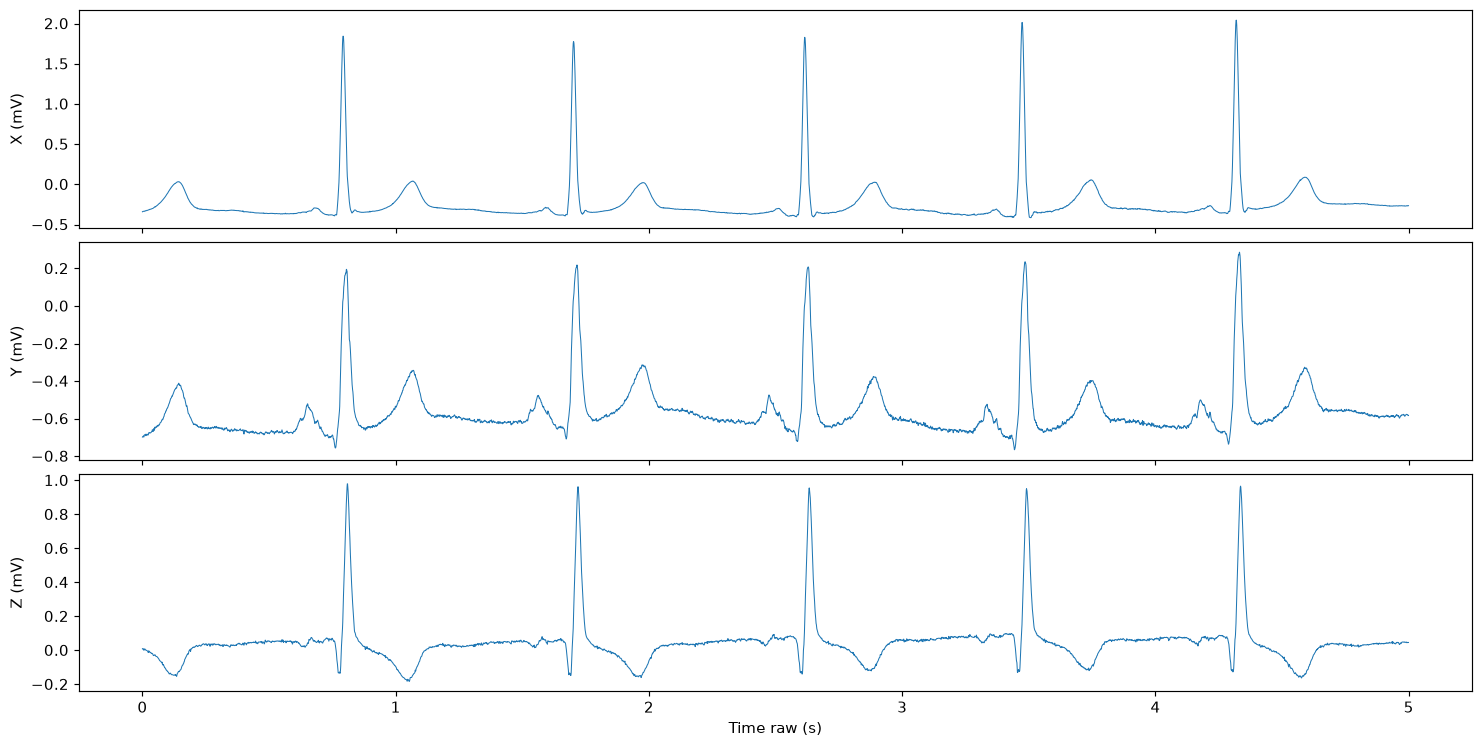

In [8]:
v4_demo=v4_state(V4_DEMO_ID)
v4_demo_est=v4_estimate(v4_demo)
v4_raw=v4_demo["raw"];v4_fs=v4_demo["fs"]
print(V4_DEMO_ID,"shape=",v4_raw["xyz"].shape,"fs=",v4_fs,"leads=",v4_raw["channels"])
print("Header diagnosis chỉ để mô tả:",v4_raw["diagnosis"])
fig,ax=plt.subplots(3,1,figsize=(14,7),sharex=True,layout="constrained")
limit=min(len(v4_raw["xyz"]),round(5*v4_fs));t=np.arange(limit)/v4_fs
for j,a in enumerate(ax):
    a.plot(t,v4_raw["xyz"][:limit,j],lw=.7);a.set(ylabel="XYZ"[j]+" (mV)")
ax[-1].set_xlabel("Time raw (s)");v4_show(fig,"step01_raw_XYZ")


### 6A. QC trước lọc: mask và PSD

Cột count là số mẫu bị nghi ngờ, không phải số bệnh nhân mắc bệnh. Spike/dropout/motion mask là heuristic; V1 dùng mask để loại lỗi dữ liệu tại beat, không xóa hình thái khác mẫu chỉ vì correlation thấp. Thông báo heuristic tĩnh được giữ riêng dưới info.

,mask,n_samples,pct
0,invalid_mask,0,0.0
1,spike_mask,0,0.0
2,dropout_mask,0,0.0
3,saturation_mask,0,0.0
4,motion_suspect_mask,0,0.0
5,qc_any_mask,0,0.0


error_flags                                                   []
info_flags     [Các ngưỡng PSD/persistence/quiet là heuristic...
dtype: object

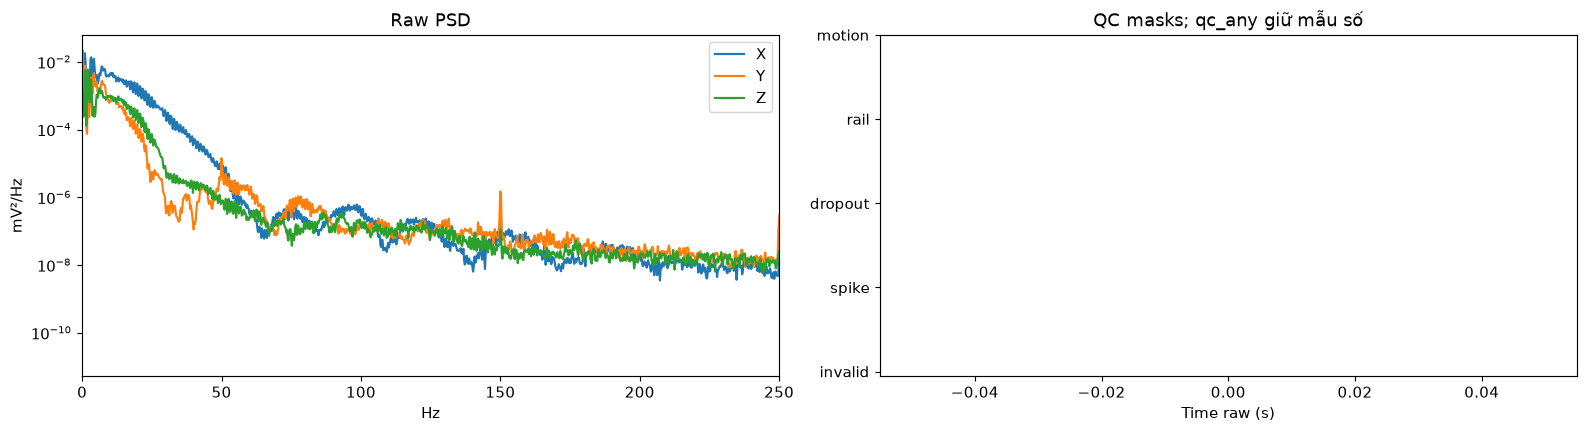

In [9]:
v4_qc=v4_demo["prep"]["input_quality"]
v4_masks={k:np.asarray(v4_qc.get(k,np.zeros(len(v4_raw["xyz"]),bool)),bool) for k in ("invalid_mask","spike_mask","dropout_mask","saturation_mask","motion_suspect_mask")}
v4_masks["qc_any_mask"]=np.logical_or.reduce(list(v4_masks.values()))
v4_qc_counts=pd.DataFrame([dict(mask=k,n_samples=int(v.sum()),pct=100*float(v.mean())) for k,v in v4_masks.items()])
display(v4_qc_counts)
display(pd.Series(dict(error_flags=v4_demo_est["error_flags"],info_flags=v4_demo_est["info_flags"])))
v4_plot_xyz=np.asarray(v4_raw["xyz"],float).copy();v4_idx=np.arange(len(v4_plot_xyz));v4_good=np.isfinite(v4_plot_xyz)
for j in range(3):
    if v4_good[:,j].any():v4_plot_xyz[:,j]=np.interp(v4_idx,v4_idx[v4_good[:,j]],v4_plot_xyz[v4_good[:,j],j])
    else:v4_plot_xyz[:,j]=0.
f,p=welch_xyz(v4_plot_xyz,v4_fs,V4_PRE)
fig,ax=plt.subplots(1,2,figsize=(15,4),layout="constrained")
for j in range(3):ax[0].semilogy(f,p[:,j],label="XYZ"[j])
ax[0].set(xlim=(0,250),xlabel="Hz",ylabel="mV²/Hz",title="Raw PSD");ax[0].legend()
for j,k in enumerate(("invalid_mask","spike_mask","dropout_mask","saturation_mask","motion_suspect_mask")):
    a=np.flatnonzero(v4_qc[k]);ax[1].scatter(a/v4_fs,np.full(len(a),j),s=2,label=k)
ax[1].set(xlabel="Time raw (s)",yticks=range(5),yticklabels=["invalid","spike","dropout","rail","motion"],title="QC masks; qc_any giữ mẫu số")
v4_show(fig,"step02_QC")


### 6B. Tiền xử lý morphology/detection như V1

Màu overlay raw/morphology cho biết tín hiệu thực sự thay đổi thế nào. Detection band chỉ dùng tìm anchors, không dùng để tính loop feature. Kiểm tra notch_applied/notch_channels/reason ở bảng, không suy đoán cứ PTB là phải notch.

,value
morphology_mode,fir
notch_applied,False
notch_channels,[]
reason,None
rms_difference_uV,"[1.350562780571581, 1.8280378118150808, 1.4954..."


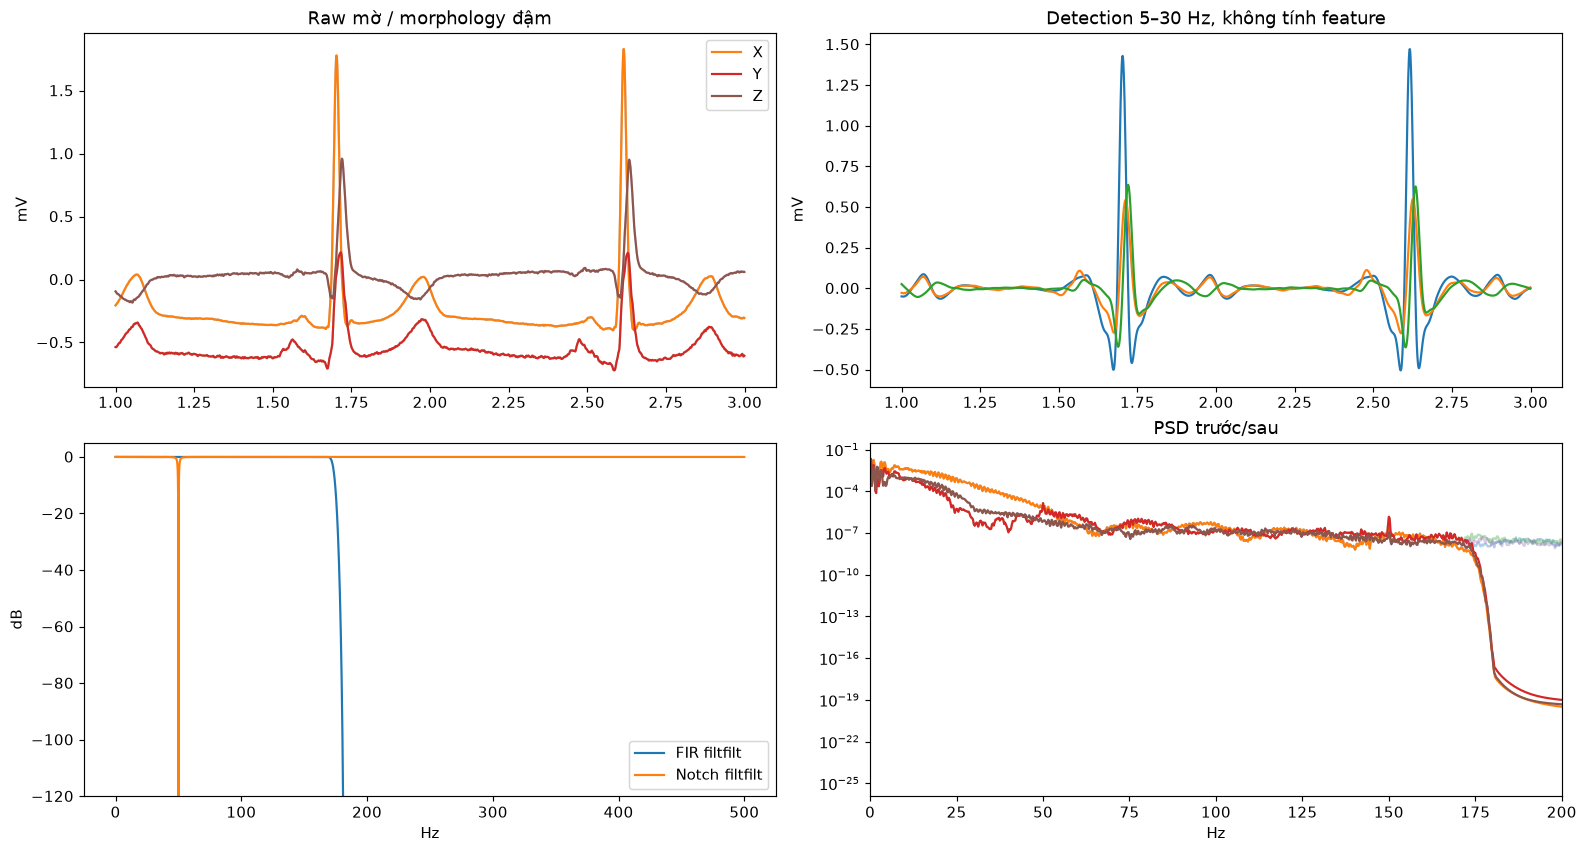

In [10]:
display(pd.Series({k:v4_demo["prep"].get(k) for k in
    ("morphology_mode","notch_applied","notch_channels","reason","rms_difference_uV")}).to_frame("value"))
response=filter_frequency_response(v4_fs,V4_PRE)
fig,ax=plt.subplots(2,2,figsize=(15,8),layout="constrained")
lo=round(1*v4_fs);hi=round(3*v4_fs);times=np.arange(lo,hi)/v4_fs
for j in range(3):
    ax[0,0].plot(times,v4_raw["xyz"][lo:hi,j],alpha=.35)
    ax[0,0].plot(times,v4_demo["morph"][lo:hi,j],label="XYZ"[j])
    ax[0,1].plot(times,v4_demo["detection"][lo:hi,j],label="XYZ"[j])
ax[0,0].set(title="Raw mờ / morphology đậm",ylabel="mV");ax[0,0].legend()
ax[0,1].set(title="Detection 5–30 Hz, không tính feature",ylabel="mV")
ax[1,0].plot(response.frequency_hz,response.fir_two_pass_db,label="FIR filtfilt")
ax[1,0].plot(response.frequency_hz,response.notch_two_pass_db,label="Notch filtfilt")
ax[1,0].set(xlabel="Hz",ylabel="dB",ylim=(-120,5));ax[1,0].legend()
for j in range(3):
    ax[1,1].semilogy(f,p[:,j],alpha=.35)
    ax[1,1].semilogy(v4_demo["prep"]["psd_after_frequency_hz"],v4_demo["prep"]["psd_after_density"][:,j],label="XYZ"[j])
ax[1,1].set(xlim=(0,200),xlabel="Hz",title="PSD trước/sau")
v4_show(fig,"step03_preprocessing")


### 6C. QRS envelope, threshold, anchors và RR

Đây là detector XYZ cũ, không huấn luyện lại. RR lấy từ anchors của chính record; irregular RR là cờ cần xem, không dùng nhãn MI/HC. Bảng có số anchors, beat giữ và beat loại; toàn bộ beat QC lưu cuối notebook.

Anchors: 31 used: 29 excluded: 2 median RR(s): 0.956 flags: []


,included,reason,beats
0,False,edge,2
1,True,used,29


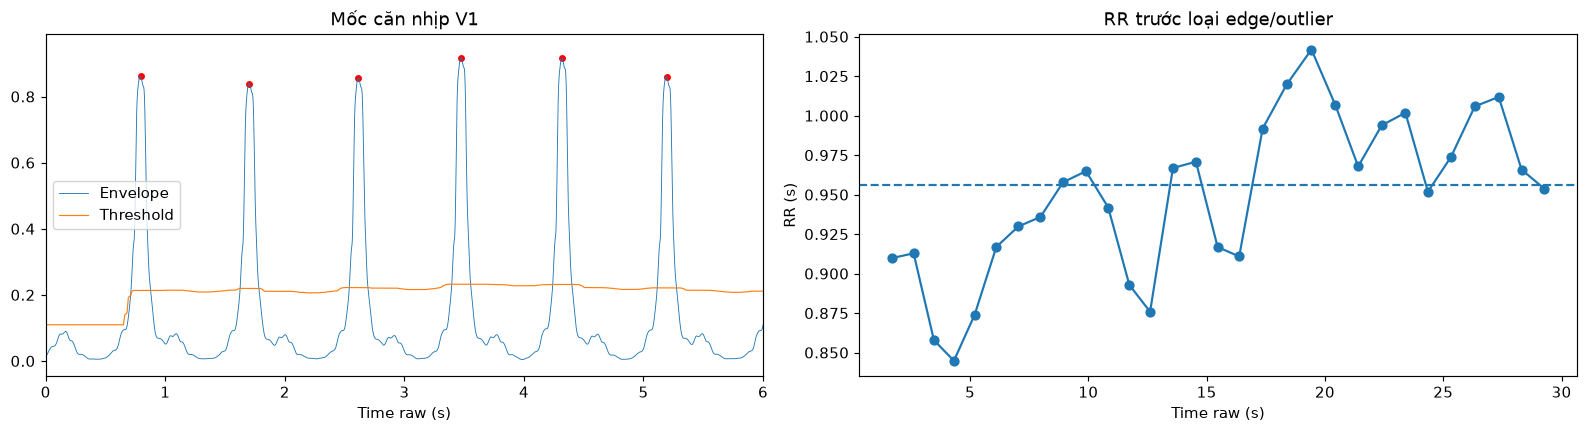

In [11]:
det=v4_demo["detector"];rep=v4_demo["rep"];anchors=det["anchors"]
print("Anchors:",len(anchors),"used:",rep["n_used"],"excluded:",rep["n_excluded"],
      "median RR(s):",rep["rr_seconds"],"flags:",det["flags"])
display(rep["beat_qc"].groupby(["included","reason"],dropna=False).size().rename("beats").reset_index())
fig,ax=plt.subplots(1,2,figsize=(15,4),layout="constrained")
tt=np.arange(len(det["envelope"]))/v4_fs
ax[0].plot(tt,det["envelope"],lw=.6,label="Envelope")
ax[0].plot(tt,det["threshold"],lw=.8,label="Threshold")
ax[0].scatter(anchors/v4_fs,det["envelope"][anchors],s=14,color="red")
ax[0].set(xlim=(0,6),xlabel="Time raw (s)",title="Mốc căn nhịp V1");ax[0].legend()
ax[1].plot(anchors[1:]/v4_fs,det["rr"],"o-");ax[1].axhline(rep["rr_seconds"],ls="--")
ax[1].set(xlabel="Time raw (s)",ylabel="RR (s)",title="RR trước loại edge/outlier")
v4_show(fig,"step04_anchors_RR")


### 6D. Cắt beat, trừ baseline PQ, median từng trục

Mỗi đường mờ là một beat được V1 giữ; đường đậm là median. Median có thể làm yếu đặc điểm xuất hiện ở ít beat; E3 chạy lại từng beat để đo hậu quả. PQ chỉ là đoạn nền chung, không tự trừ ST để làm ST-T đẹp hơn.

Median shape: (931, 3) PQ: (60, 85) anchor: 280


,sample,reason,included,correlation,morphology_status,pq_warning,pq_on,pq_off,pq_mean_speed_mV_s,pq_radius95_mV
0,793,edge,False,NaN,not_assessed,,NaN,NaN,NaN,NaN
1,1703,used,True,0.999061,similar,,74.0,99.0,1.771363,0.009946
2,2616,used,True,0.998559,similar,,60.0,85.0,1.446903,0.009397
3,3474,used,True,0.998934,similar,,62.0,87.0,1.760141,0.010622
4,4319,used,True,0.999071,similar,,60.0,85.0,1.408276,0.008395
5,5193,used,True,0.998249,similar,,61.0,86.0,1.027742,0.005838
6,6110,used,True,0.998015,similar,,60.0,85.0,0.839499,0.004557
7,7040,used,True,0.996940,similar,,60.0,85.0,1.517332,0.010385
8,7976,used,True,0.998910,similar,,64.0,89.0,1.467081,0.005844
9,8934,used,True,0.999305,similar,,60.0,85.0,1.443702,0.009217


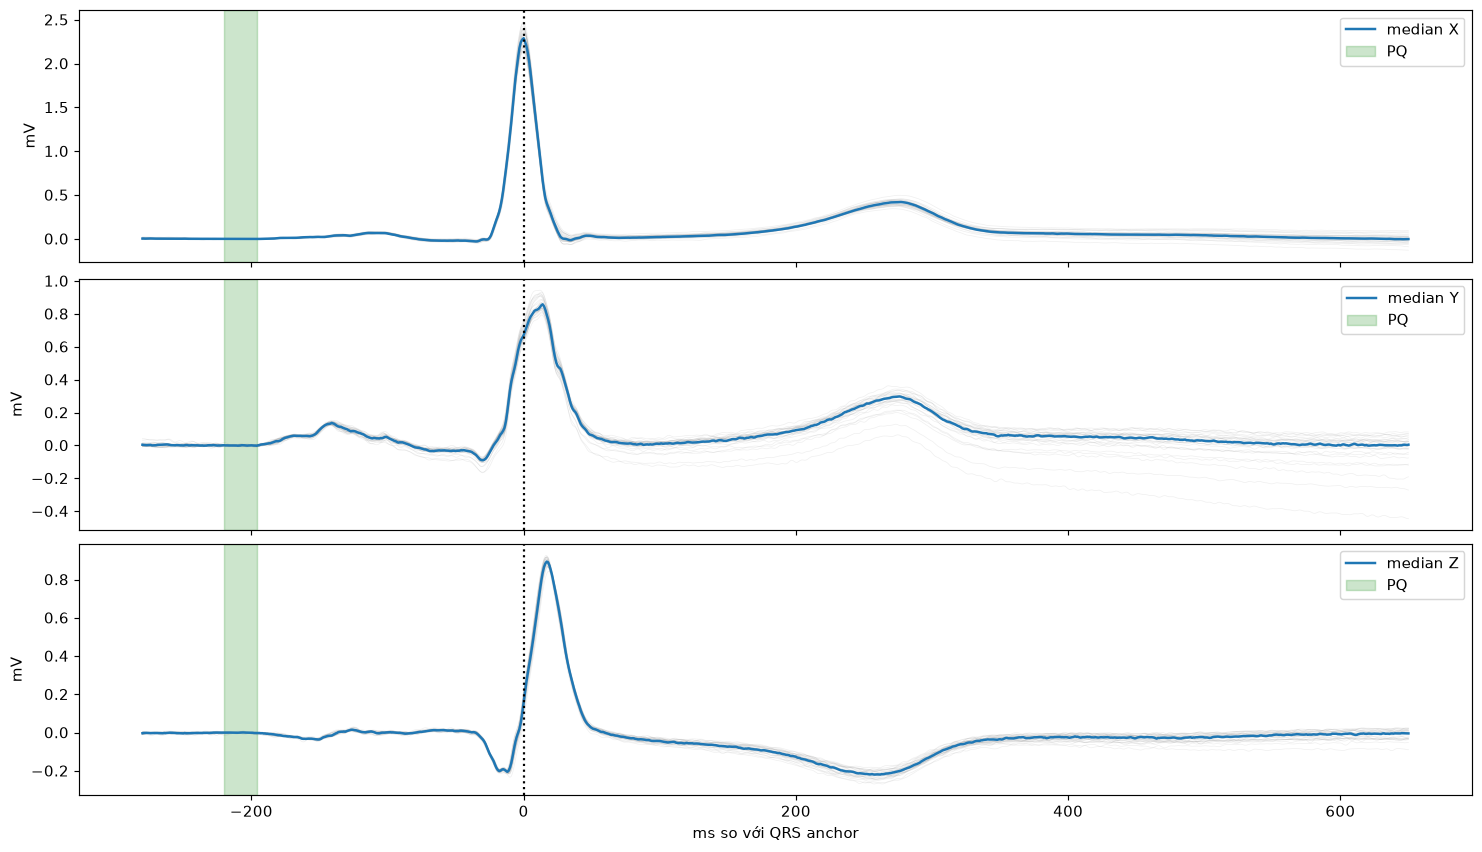

In [12]:
fig,ax=plt.subplots(3,1,figsize=(14,8),sharex=True,layout="constrained")
for j,a in enumerate(ax):
    a.plot(rep["time_ms"],rep["beats"][:,:,j].T,color="gray",alpha=.12,lw=.5)
    a.plot(rep["time_ms"],rep["xyz"][:,j],lw=1.7,label="median "+"XYZ"[j])
    a.axvspan(rep["time_ms"][rep["pq"][0]],rep["time_ms"][rep["pq"][1]-1],alpha=.2,color="green",label="PQ")
    a.axvline(0,color="black",ls=":");a.set_ylabel("mV");a.legend()
ax[-1].set_xlabel("ms so với QRS anchor")
print("Median shape:",rep["xyz"].shape,"PQ:",rep["pq"],"anchor:",rep["anchor"])
display(rep["beat_qc"].head(12))
v4_show(fig,"step05_beats_PQ_median")


### 6E. QRS boundaries, J-point và peak T V1

Biên QRS lấy đường spatial speed V1; J=qrs_off. T-peak giữ peak prominence của V1 trong [J+20 ms, min(600 ms,70% RR) sau anchor], gồm các guard distance/peak của V1. Thiếu peak → unresolved, không chọn điểm tối đa một cách ép buộc.

,value
qrs_on,249
qrs_off,328
t_peak,553
t_search,"(348, 849)"
tp,"(692, 717)"
q_threshold,11.525892
t_end_baseline,0.077967
t_end_threshold,0.115939
flags,[]


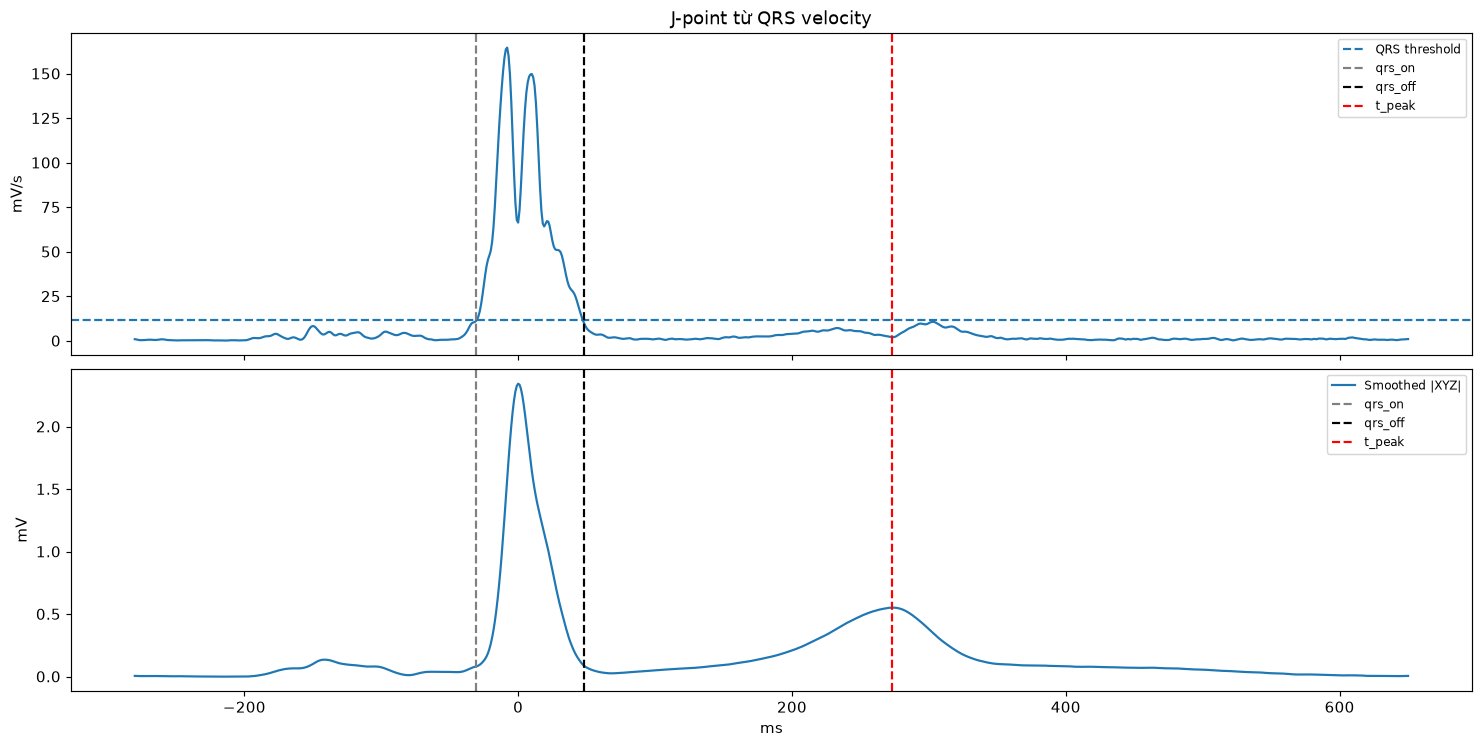

In [13]:
q=v4_demo_est["q"];mt=q["t_magnitude"];tt=rep["time_ms"]
display(pd.Series({k:q.get(k) for k in ("qrs_on","qrs_off","t_peak","t_search","tp","q_threshold","t_end_baseline","t_end_threshold","flags")}).to_frame("value"))
fig,ax=plt.subplots(2,1,figsize=(14,7),sharex=True,layout="constrained")
ax[0].plot(tt,q["smooth_speed"]);ax[0].axhline(q["q_threshold"],ls="--",label="QRS threshold")
ax[1].plot(tt,mt,label="Smoothed |XYZ|")
for name,color in (("qrs_on","gray"),("qrs_off","black"),("t_peak","red")):
    if v4_index(q.get(name),len(tt)):
        for a in ax:a.axvline(tt[q[name]],color=color,ls="--",label=name)
for a in ax:a.legend(fontsize=8)
ax[0].set(ylabel="mV/s",title="J-point từ QRS velocity");ax[1].set(xlabel="ms",ylabel="mV")
v4_show(fig,"step06_QRS_J_Tpeak")


### 6F. V2 offset — wavelet, single-lead và TLS

Hàng XYZ theo scale cho thấy tín hiệu biến đổi thật, bảng TLS là các iteration của nhánh offset. Mốc onset phụ được lưu nhưng không tham gia hợp nhất T-end. Khi V2 thất bại, xem reason, detection_status và stop_reason; không tự tăng cửa sổ/ngưỡng cho test. Không gán tất cả missing V2 là “ca khó” nếu chưa kiểm tra nguyên nhân.

V2 end: 633 onset phụ: 426 reason:  flags: []


,axis,wavelet_scale,wave_detected,detection_status,failure_reason,search_start,search_end
0,X,4,True,detected,,380,880
1,Y,4,True,detected,,380,880
2,Z,4,True,detected,,380,880


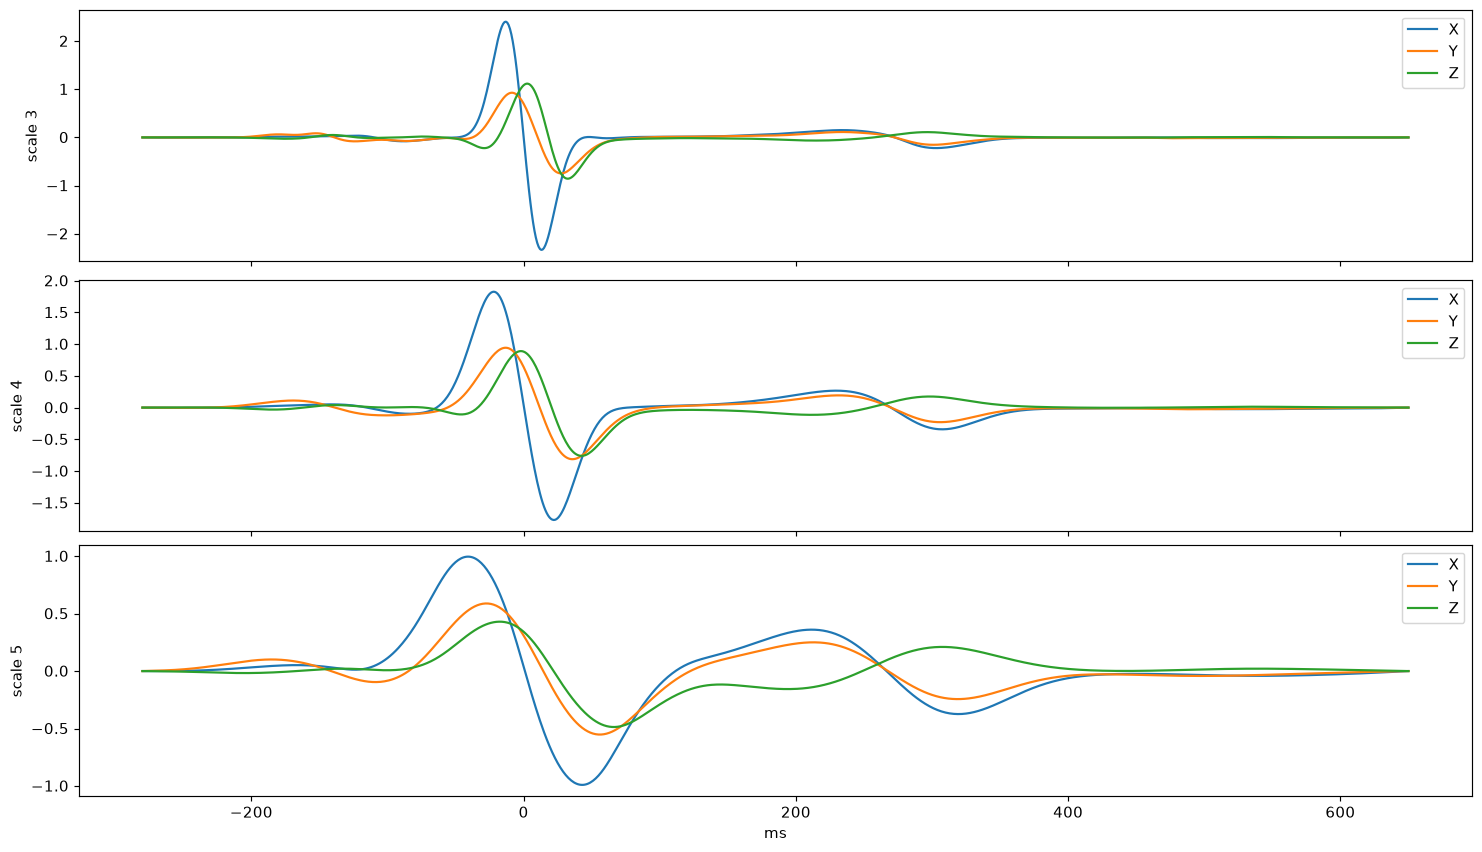

,iteration,window_start,window_end,candidate_sample,accepted,stop_reason,failure_reason,fit_quality
0,1,380,880,633,True,,None,0.97885
1,2,586,694,633,False,no_extremum_improvement_previous_retained,None,0.99890


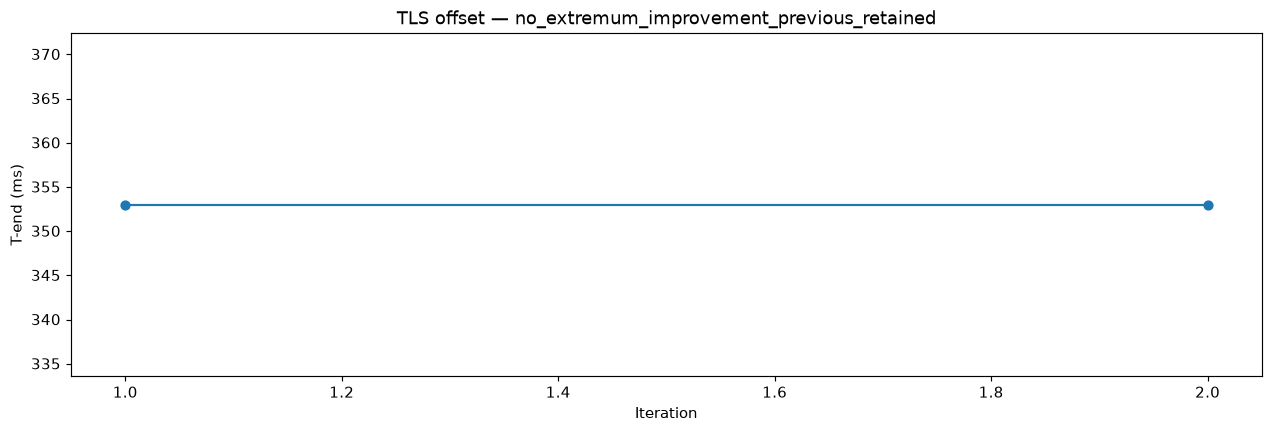

In [14]:
v2=v4_demo_est["methods"]["V2_offset"];trace=v2["trace"]
print("V2 end:",v2["end"],"onset phụ:",v2["onset"],"reason:",v2["reason"],"flags:",v2["flags"])
sl=trace.get("single_leads",[])
display(pd.DataFrame([{k:r.get(k) for k in ("axis","wavelet_scale","wave_detected","detection_status","failure_reason","search_start","search_end")} for r in sl]))
if "wavelets" in trace:
    fig,ax=plt.subplots(3,1,figsize=(14,8),sharex=True,layout="constrained")
    for a,scale in zip(ax,(3,4,5)):
        for j in range(3):a.plot(tt,trace["wavelets"][scale][:,j],label="XYZ"[j])
        a.set_ylabel(f"scale {scale}");a.legend()
    ax[-1].set_xlabel("ms");v4_show(fig,"step07_wavelets")
if "offset" in trace:
    history=trace["offset"]["history"]
    display(pd.DataFrame([{k:r.get(k) for k in ("iteration","window_start","window_end","candidate_sample","accepted","stop_reason","failure_reason","fit_quality")} for r in history]))
    fig,ax=plt.subplots(figsize=(12,4),layout="constrained")
    if history:
        values=[r.get("candidate_sample") for r in history]
        ax.plot(range(1,len(values)+1),[tt[v] if v4_index(v,len(tt)) else np.nan for v in values],"o-")
    else:ax.text(.5,.5,"TLS không có iteration hợp lệ",ha="center",transform=ax.transAxes)
    ax.set(xlabel="Iteration",ylabel="T-end (ms)",title="TLS offset — "+trace["offset"]["stop_reason"])
    v4_show(fig,"step07_TLS_offset")


### 6G. V1 threshold — baseline TP, mức ngưỡng và baseline return

Dùng t_threshold_off của V1, **không dùng t_tangent_off**. Đường ngang threshold = TP baseline + max(3 noise, 8% peak amplitude tương đối TP), cần đoạn yên theo quiet_t_ms. TP thiếu vẫn ghi cờ của V1; không xóa cờ để tăng accepted.

,value
baseline,0.077967
threshold,0.115939
search_window,"(573, 849)"
peak_used,553
candidate_window,"(583, 849)"


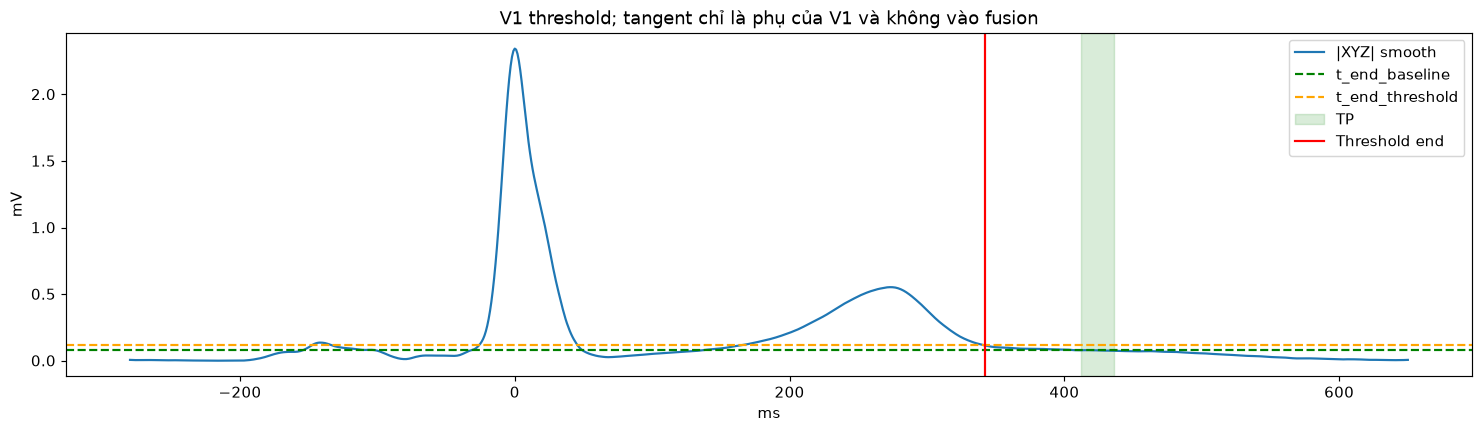

reason:  flags: ['baseline_offset']


In [15]:
threshold=v4_demo_est["methods"]["V1_threshold"]
display(pd.Series(threshold["trace"]).to_frame("value"))
fig,ax=plt.subplots(figsize=(14,4),layout="constrained")
ax.plot(tt,mt,label="|XYZ| smooth")
for key,color in (("t_end_baseline","green"),("t_end_threshold","orange")):
    if np.isfinite(q[key]):ax.axhline(q[key],ls="--",color=color,label=key)
if q["tp"] is not None:
    ax.axvspan(tt[q["tp"][0]],tt[q["tp"][1]-1],color="green",alpha=.15,label="TP")
if threshold["end"] is not None:ax.axvline(tt[threshold["end"]],color="red",label="Threshold end")
ax.set(xlabel="ms",ylabel="mV",title="V1 threshold; tangent chỉ là phụ của V1 và không vào fusion")
ax.legend();v4_show(fig,"step08_V1_threshold")
print("reason:",threshold["reason"],"flags:",threshold["flags"])


### 6H. Trapezium — xem diện tích và nghiệm

Vùng tô là tích phân từ a đến b, hình thang nét đứt có diện tích bằng tích phân đó. Sai khác diện tích gần 0 chỉ xác nhận phép tính, không xác nhận biên. Xem E1 để biết bias trên waveform bất đối xứng.

end: 606 reason: 


,value
a,581
b,849
baseline,0.077071
area_mV_s,0.002645
h0_mV,0.21417
h1_mV,0.0
continuous_end,605.696456
search_window,"(583, 849)"
peak_used,553
trapezium_area_mV_s,0.002645


Area mismatch (mV*s): 4.336808689942018e-18


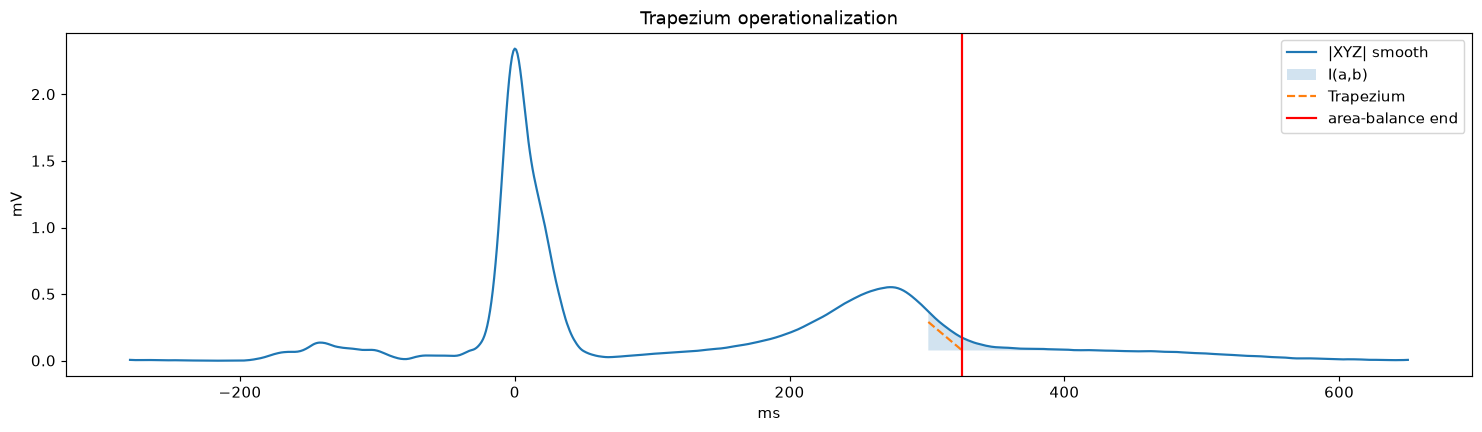

In [16]:
tr=v4_demo_est["methods"]["Trapezium"];z=tr["trace"]
print("end:",tr["end"],"reason:",tr["reason"]);display(pd.Series(z).to_frame("value"))
fig,ax=plt.subplots(figsize=(14,4),layout="constrained")
ax.plot(tt,mt,label="|XYZ| smooth")
if z:
    a,b=z["a"],z["b"];base=z["baseline"];end=z["continuous_end"]
    ax.fill_between(tt[a:b+1],base,base+np.maximum(mt[a:b+1]-base,0),alpha=.2,label="I(a,b)")
    ax.plot([tt[a],(end-rep["anchor"])*1000/v4_fs],
            [base+z["h0_mV"],base+z["h1_mV"]],"--",label="Trapezium")
    ax.axvline((end-rep["anchor"])*1000/v4_fs,color="red",label="area-balance end")
    print("Area mismatch (mV*s):",z["area_mV_s"]-z["trapezium_area_mV_s"])
ax.set(xlabel="ms",ylabel="mV",title="Trapezium operationalization");ax.legend()
v4_show(fig,"step09_trapezium")


### 6I. Trung vị, uncertainty, ST-T/pure-T và feature

Bảng demo dưới dùng ngưỡng tạm 25 ms/QT250–550 chỉ để giải thích trạng thái; bảng cohort cuối được tính lại bằng calibration train đã khóa. Không đủ hai estimator hợp lệ → unresolved. Độ bất định lớn → needs_review, giữ candidate, mask ở accepted policy.

Hình dùng J→end cho ST-T. Đường thẳng 3D nối các XYZ theo thời gian, không ép khép kín. Pure-T chỉ có khi onset V1/V2 trong 25 ms và onset<peak<end.

,method,loop_variant,valid_end,loop_valid,t_end_ms,uncertainty_ms,status,accepted,error_flags
0,V2_offset,STT,True,True,353.0,NaN,accepted,True,
1,V2_offset,pure_T,True,False,353.0,NaN,accepted,False,onset_agreement_missing_or_invalid
2,V1_threshold,STT,True,True,342.0,NaN,needs_review,False,V1_threshold:baseline_offset
3,V1_threshold,pure_T,True,False,342.0,NaN,needs_review,False,V1_threshold:baseline_offset;onset_agreement_m...
4,Trapezium,STT,True,True,326.0,NaN,needs_review,False,Trapezium:baseline_offset
5,Trapezium,pure_T,True,False,326.0,NaN,needs_review,False,Trapezium:baseline_offset;onset_agreement_miss...
6,Integral,STT,True,True,315.0,NaN,needs_review,False,Integral:baseline_offset
7,Integral,pure_T,True,False,315.0,NaN,needs_review,False,Integral:baseline_offset;onset_agreement_missi...
8,V4_median,STT,True,True,334.0,38.0,needs_review,False,Integral:baseline_offset;Trapezium:baseline_of...
9,V4_median,pure_T,True,False,334.0,38.0,needs_review,False,Integral:baseline_offset;Trapezium:baseline_of...


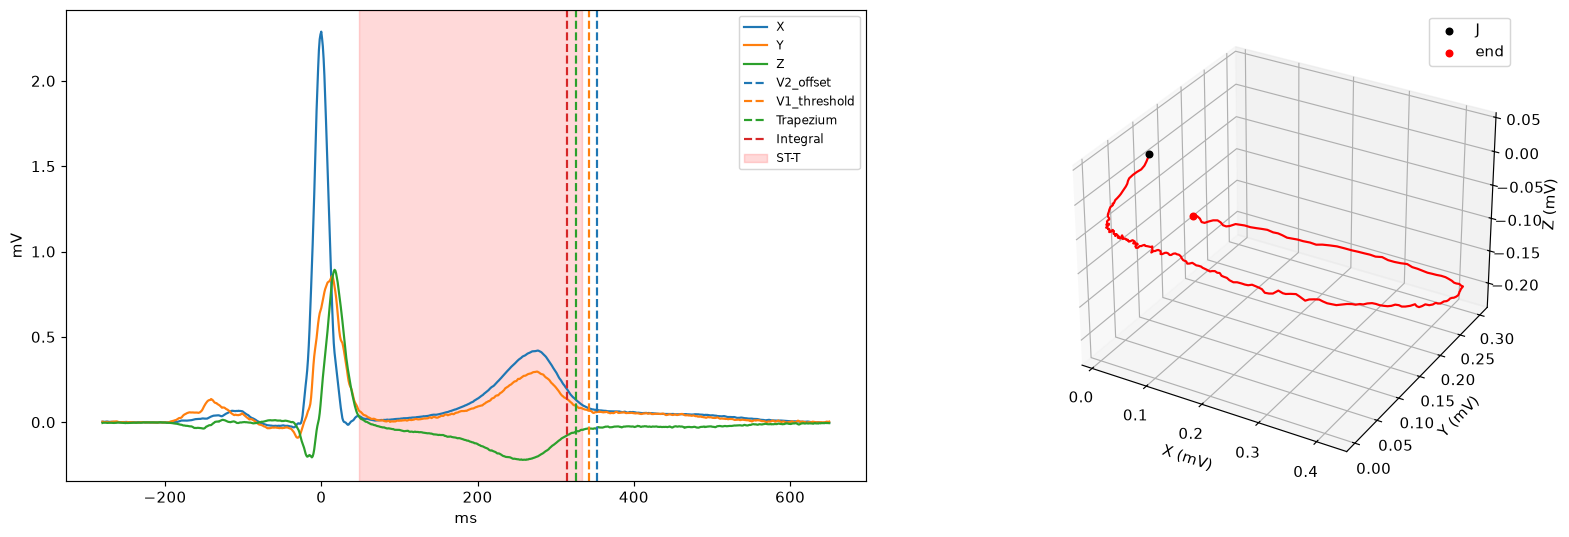

,method,loop_variant,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel,T_Arc,Spatial_QRS_T_Angle_deg,VG_X_mVs,VG_Y_mVs,VG_Z_mVs,VG_Magnitude_mVs,T_Axis_Azimuth_deg,T_Axis_Elevation_deg
0,V2_offset,STT,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,0.55288,0.035430,11.059858,3.780706,2.585061,1.197359,46.093081,0.097643,0.062843,-0.010965,0.116635,35.074277,-28.129519
1,V2_offset,pure_T,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,V1_threshold,STT,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,0.55288,0.035903,11.059858,3.842639,2.608767,1.171799,46.239289,0.096793,0.062154,-0.010573,0.115515,34.996578,-28.283541
3,V1_threshold,pure_T,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Trapezium,STT,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,0.55288,0.037810,11.059858,3.858515,2.671007,1.108591,46.596854,0.095119,0.060848,-0.009876,0.113347,34.878844,-28.653262
5,Trapezium,pure_T,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Integral,STT,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,0.55288,0.040180,11.059858,3.747177,2.653466,1.035423,47.004084,0.093378,0.059592,-0.009181,0.111153,34.839391,-29.065807
7,Integral,pure_T,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,V4_median,STT,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,0.55288,0.036634,11.059858,3.873532,2.637574,1.146352,46.398986,0.096050,0.061549,-0.010263,0.114539,34.923839,-28.450503
9,V4_median,pure_T,5.892343,2.076441,2.39103,1.6732,170.154227,74.685192,48.794393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
v4_demo_rows=pd.DataFrame(v4_rows(v4_demo,v4_demo_est,V4_PROVISIONAL))
display(v4_demo_rows[["method","loop_variant","valid_end","loop_valid","t_end_ms","uncertainty_ms","status","accepted","error_flags"]])
fig=plt.figure(figsize=(16,5),layout="constrained");a=fig.add_subplot(121);b=fig.add_subplot(122,projection="3d")
for j in range(3):a.plot(tt,rep["xyz"][:,j],label="XYZ"[j])
ends=v4_endpoints(v4_demo,v4_demo_est)
for m in V4_BASE_METHODS:
    end=ends[m]["end"]
    if end is not None:a.axvline(tt[end],color=V4_PLOTS[m],ls="--",label=m)
main=ends["V4_median"]["end"];jpoint=q["qrs_off"]
if main is not None and jpoint is not None:
    a.axvspan(tt[jpoint],tt[main],alpha=.15,color="red",label="ST-T")
    loop=rep["xyz"][jpoint:main+1];b.plot(*loop.T,color="red")
    b.scatter(*loop[0],color="black",label="J");b.scatter(*loop[-1],color="red",label="end");b.legend()
else:b.text2D(.1,.5,"Không có ST-T hợp lệ",transform=b.transAxes)
a.legend(fontsize=8);a.set(xlabel="ms",ylabel="mV");b.set(xlabel="X (mV)",ylabel="Y (mV)",zlabel="Z (mV)")
v4_show(fig,"step10_consensus_STT_3D")
display(v4_demo_rows[["method","loop_variant",*V4_ALL_FEATURES]])


## 7. E3 — hàm đánh giá trên mọi beat, noise và bootstrap development

Từng beat là mọi beat V1 đã giữ; không giới hạn vài ca đẹp. Chạy lại QRS boundaries và các T estimator trên beat PQ-centered. T-peak/J có thể thay đổi theo beat. Beat bị V1 loại vẫn có trong beat_qc và đếm số bị loại, nhưng không có delineation giả cho beat lỗi.

Noise thêm vào median: 0.5/1/2% robust XYZ scale, cùng record/seed/array cho mọi method. Giữ raw anchors/RR, tính lại QRS boundary trên median nhiễu. Bootstrap resample **các beat giữ** rồi tạo median mới; không giả vờ đây là raw pipeline bootstrap.

Delta chỉ tính khi baseline và biến đổi đều valid. Báo missing %, paired %, valid retention, record-level jitter/IQR và patient-cluster CI; method luôn thiếu biên không được gọi là ổn định.

In [18]:
def v4_numeric_frame(rows,columns):
    frame=pd.DataFrame(rows,columns=columns)
    for c in ("end_ms","baseline_end_ms","delta_ms","uncertainty_ms"):
        if c in frame:frame[c]=pd.to_numeric(frame[c],errors="coerce")
    return frame

V4_TRIAL_COLUMNS=["method","kind","level","repeat","base_valid","valid","accepted",
                  "end_ms","baseline_end_ms","delta_ms","uncertainty_ms","error"]

def v4_trials(st,screen):
    base=v4_estimate(st);bp=v4_endpoints(st,base);rep=st["rep"];fs=st["fs"];rows=[]
    def attempt(xyz,kind,level,repeat):
        clone=dict(st);clone["rep"]=dict(rep)
        clone["rep"]["xyz"]=xyz
        clone["rep"]["pq"],baseline=flattest_pq(xyz,fs,rep["anchor"],left_ms=-min(220,rep["anchor"]*1000/fs-5))
        clone["rep"]["xyz"]=xyz-baseline
        failure=""
        try:
            changed=v4_estimate(clone);ep=v4_endpoints(clone,changed)
            statuses={r["method"]:r for r in v4_rows(clone,changed,screen) if r["loop_variant"]=="STT"}
        except Exception as exc:
            failure=type(exc).__name__+": "+str(exc);ep={m:dict(end=None,uncertainty_ms=np.nan) for m in V4_METHODS};statuses={}
        for m in V4_METHODS:
            old,new=bp[m]["end"],ep[m]["end"]
            old_ok=old is not None;new_ok=new is not None
            rows.append(dict(method=m,kind=kind,level=level,repeat=repeat,base_valid=old_ok,
                valid=new_ok,accepted=statuses.get(m,{}).get("accepted",False),
                end_ms=(new-rep["anchor"])*1000/fs if new_ok else np.nan,
                baseline_end_ms=(old-rep["anchor"])*1000/fs if old_ok else np.nan,
                delta_ms=(new-old)*1000/fs if old_ok and new_ok else np.nan,
                uncertainty_ms=ep[m]["uncertainty_ms"],error=failure))
    for i,beat in enumerate(rep["beats"]):attempt(beat,"beat",0.,i)
    sigma=max(float(1.4826*np.median(abs(rep["xyz"]-np.median(rep["xyz"],axis=0)))),1e-9)
    for level,seed in product(V4_NOISE_LEVELS,V4_SEEDS):
        noise=np.random.default_rng(seed).normal(0,level*sigma,rep["xyz"].shape)
        attempt(rep["xyz"]+noise,"noise",level,seed)
    rng=np.random.default_rng(20261023)
    for repeat in range(V4_BOOTSTRAPS):
        chosen=rng.integers(0,len(rep["beats"]),len(rep["beats"]))
        attempt(np.median(rep["beats"][chosen],axis=0),"bootstrap",0.,repeat)
    return rows

def v4_e3_cohort(selected,screen):
    if not selected.split.isin(["train","val"]).all():raise ValueError("E3 không chạy trên test.")
    rows=[];errors=[]
    for i,r in enumerate(selected.itertuples(index=False),1):
        try:
            st=v4_cached_state(r.record_id)
            values,_=v4_cache(r.record_id,"E3",lambda:v4_trials(st,screen),screen)
        except Exception as exc:
            error=type(exc).__name__+": "+str(exc)
            errors.append(dict(record_id=r.record_id,split=r.split,label=r.label_name,error=error))
            # Baseline fail: noise/bootstrap vẫn có mẫu số; beat count không quan sát -> marker.
            trials=[("beat_unavailable",0.,-1)]+[("noise",l,s) for l,s in product(V4_NOISE_LEVELS,V4_SEEDS)]+[
                ("bootstrap",0.,b) for b in range(V4_BOOTSTRAPS)]
            values=[dict(method=m,kind=k,level=l,repeat=b,base_valid=False,valid=False,accepted=False,
                end_ms=np.nan,baseline_end_ms=np.nan,delta_ms=np.nan,uncertainty_ms=np.nan,error=error)
                for m,(k,l,b) in product(V4_METHODS,trials)]
        rows.extend(dict(v,record_id=r.record_id,patient_id=r.patient_id,split=r.split,label=r.label_name) for v in values)
        if i==1 or i%10==0 or i==len(selected):print(f"E3 {i}/{len(selected)}",flush=True)
    frame=pd.DataFrame(rows)
    for c in ("delta_ms","end_ms","uncertainty_ms"):frame[c]=pd.to_numeric(frame[c],errors="coerce")
    return frame,pd.DataFrame(errors)

def v4_e3_summary(frame):
    if frame.empty:return pd.DataFrame()
    rows=[]
    for keys,g in frame.groupby(["split","label","method","kind","level"],sort=False):
        delta=g.delta_ms.abs();paired=delta.notna()
        row=dict(zip(("split","label","method","kind","level"),keys),n_attempted=g.record_id.nunique(),
            n_patients=g.patient_id.nunique(),n_trials=len(g),n_valid=int(g.valid.sum()),
            missing_pct=100*(1-g.valid.mean()),paired_n=int(paired.sum()),paired_pct=100*paired.mean(),
            valid_retention_pct=100*paired.sum()/g.base_valid.sum() if g.base_valid.sum() else np.nan,
            jitter_median_abs_ms=delta.median(),jitter_p90_abs_ms=delta.quantile(.9),
            delta_bias_ms=g.delta_ms.mean())
        per_record=g.groupby("record_id").end_ms.agg(lambda a:a.quantile(.75)-a.quantile(.25))
        row["median_within_record_IQR_ms"]=per_record.median()
        rows.append(row)
    return pd.DataFrame(rows)

def v4_cluster_ci(g,statistic,repeats=V4_CI_REPEATS):
    patients=np.sort(g.patient_id.unique())
    if len(patients)<5:return (np.nan,np.nan,0)
    blocks=[g[g.patient_id.eq(p)] for p in patients];rng=np.random.default_rng(20261023)
    values=[]
    for _ in range(repeats):
        sampled=pd.concat([blocks[j] for j in rng.integers(0,len(blocks),len(blocks))],ignore_index=True)
        value=statistic(sampled)
        if np.isfinite(value):values.append(value)
    if len(values)<20:return (np.nan,np.nan,len(values))
    return (*np.quantile(values,[.025,.975]),len(values))


## 8. E4 — dịch riêng T-end và đo lại feature

Chỉ dịch T-end ±5/10/20 ms; J-point giữ nguyên cho ST-T, onset đồng thuận giữ nguyên cho pure-T. Không clip biên vào mảng: ca sai thứ tự/peak/mảng thành invalid. Giữ cả baseline missing trong từng scenario. Relative change dùng |baseline|, gần 0 thành NaN; góc dùng circular absolute difference theo độ, không chia phần trăm góc. T_Arc/Area/Velocity xem riêng, không cộng các đơn vị thành điểm chung.

Feature có median |relative delta| >20% ở train được đánh dấu nhạy để đọc báo cáo; đây là ngưỡng mô tả khóa trước, không dùng test chọn feature. E6 báo feature set cố định trong đặc tả; không tự chọn bộ có AUC cao nhất.

In [19]:
V4_SHIFTS=(-20,-10,-5,5,10,20)
def v4_sensitivity(st,screen):
    est=v4_estimate(st);baseline=v4_rows(st,est,screen);q=est["q"];rep=st["rep"];rows=[]
    for base in baseline:
        method,loop=base["method"],base["loop_variant"]
        start=q.get("qrs_off") if loop=="STT" else base.get("t_on_sample")
        for shift in V4_SHIFTS:
            end=base.get("t_end_sample")
            moved=int(end)+round(shift*st["fs"]/1000) if v4_index(end,len(rep["xyz"])) else None
            valid=bool(base["loop_valid"] and v4_index(moved,len(rep["xyz"])) and
                       start<q["t_peak"]<moved)
            feat=v4_features(st,q,start if valid else None,moved if valid else None)
            for feature in V4_T_FEATURES:
                a,b=base[feature],feat[feature]
                delta=b-a if valid else np.nan
                angular=feature in ("T_Axis_Azimuth_deg","T_Axis_Elevation_deg","Spatial_QRS_T_Angle_deg")
                if angular and np.isfinite(delta):delta=(delta+180)%360-180
                rows.append(dict(method=method,loop_variant=loop,shift_ms=shift,feature=feature,
                    valid=valid,reason="" if valid else "invalid_baseline_or_shift",
                    baseline=a,value=b,abs_delta=abs(delta),
                    relative_abs_pct=100*abs(delta)/abs(a) if not angular and np.isfinite(a) and abs(a)>1e-9 else np.nan,
                    angular_abs_deg=abs(delta) if angular else np.nan))
    return rows

def v4_e4_cohort(selected,screen):
    if not selected.split.isin(["train","val"]).all():raise ValueError("E4 không chạy test.")
    rows=[]
    for i,r in enumerate(selected.itertuples(index=False),1):
        try:
            values,_=v4_cache(r.record_id,"E4",lambda:v4_sensitivity(v4_cached_state(r.record_id),screen),screen)
        except Exception as exc:
            values=[dict(method=m,loop_variant=l,shift_ms=s,feature=f,valid=False,
                reason=type(exc).__name__+": "+str(exc),baseline=np.nan,value=np.nan,abs_delta=np.nan,
                relative_abs_pct=np.nan,angular_abs_deg=np.nan)
                for (m,l),s,f in product(V4_VARIANTS,V4_SHIFTS,V4_T_FEATURES)]
        rows.extend(dict(v,record_id=r.record_id,patient_id=r.patient_id,split=r.split,label=r.label_name) for v in values)
        if i==1 or i%10==0 or i==len(selected):print(f"E4 {i}/{len(selected)}",flush=True)
    frame=pd.DataFrame(rows)
    for c in ("abs_delta","relative_abs_pct","angular_abs_deg"):frame[c]=pd.to_numeric(frame[c],errors="coerce")
    return frame

def v4_e4_summary(frame):
    if frame.empty:return pd.DataFrame()
    return frame.groupby(["split","label","method","loop_variant","feature","shift_ms"],dropna=False).agg(
        n_attempted=("record_id","size"),n_patients=("patient_id","nunique"),n_valid=("valid","sum"),
        paired_relative_n=("relative_abs_pct","count"),median_abs_relative_pct=("relative_abs_pct","median"),
        p90_abs_relative_pct=("relative_abs_pct",lambda a:a.quantile(.9)),
        median_abs_delta=("abs_delta","median"),median_angular_abs_deg=("angular_abs_deg","median")).reset_index()


## 9. E1 — generator có T-end biết trước, fs250/500/1000

Mô hình compact-support beta bump có true T-end là sample cuối support đã định trước, gồm hình dạng đối xứng/bất đối xứng/hai pha, ba amplitude, noise trắng và drift. QRS Gaussian mô phỏng chỉ để V1 tìm QRS; E1 không kiểm chứng pipeline raw/FIR (FIR V1 cố định fs1000). Không resample raw PTB để giả tăng dữ liệu.

Mỗi subject synthetic có tham số riêng và toàn điều kiện; synthetic_validation và synthetic_holdout dùng seed/ID không giao nhau. Validation chạy trước lock; holdout chạy sau lock và không thay cấu hình. Error = predicted−truth ms, luôn báo missing trên mọi case; không bỏ ca thất bại khỏi mẫu số MAE coverage.

In [20]:
V4_SYNTH_SHAPES=("symmetric","asymmetric","biphasic")
V4_SYNTH_FS=(250,500,1000)
V4_SYNTH_AMPLITUDES=(.08,.25,.60)
V4_SYNTH_NOISE=(0.,.01,.03)
V4_SYNTH_DRIFT=(0.,.02)

def v4_synthetic(subject,partition,fs,shape,amplitude,noise,drift):
    # Truth xác định trước detector và độc lập kết quả thuật toán.
    offset=0 if partition=="synthetic_validation" else 100000
    rng=np.random.default_rng(710000+offset+subject)
    t=np.arange(-.28,.651,1/fs);anchor=int(np.argmin(abs(t)))
    t=(np.arange(len(t))-anchor)/fs
    rr=float(rng.uniform(.82,1.05));end_s=float(rng.uniform(.34,.43))
    end=int(round(anchor+end_s*fs));start=int(round(anchor+.12*fs))
    u=np.clip((np.arange(len(t))-start)/max(end-start,1),0,1)
    aa,bb=(2.,2.) if shape=="symmetric" else (1.5,3.) if shape=="asymmetric" else (2.,2.5)
    bump=u**aa*(1-u)**bb;bump/=max(float(bump.max()),1e-12)
    bump[(np.arange(len(t))<=start)|(np.arange(len(t))>=end)]=0.
    direction=rng.normal(size=3);direction/=np.linalg.norm(direction)
    second=np.roll(direction,1);second-=np.dot(second,direction)*direction
    second/=max(np.linalg.norm(second),1e-9)
    T=amplitude*bump[:,None]*direction
    if shape=="biphasic":
        T=amplitude*bump[:,None]*(np.cos(np.pi*u)[:,None]*direction+
                                      .45*np.sin(np.pi*u)[:,None]*second)
    Q=1.1*np.exp(-.5*(t/.016)**2)[:,None]*np.array([.8,-.4,.3])
    Q-=.35*np.exp(-.5*((t-.032)/.012)**2)[:,None]*np.array([.4,.3,-.5])
    generator_noise=np.random.default_rng(900000+offset+subject+int(fs)+int(amplitude*1000))
    xyz=Q+T+noise*amplitude*generator_noise.normal(size=(len(t),3))
    xyz+=drift*np.sin(2*np.pi*.7*t+.4)[:,None]*np.array([.6,-.3,.5])
    pq=(max(0,anchor-round(.21*fs)),max(1,anchor-round(.17*fs)))
    xyz-=np.median(xyz[slice(*pq)],axis=0)
    rep=dict(xyz=xyz,anchor=anchor,rr_seconds=rr,pq=pq,time_ms=t*1000,
             beats=xyz[None],n_used=1,n_excluded=0,quality_flags=[],used_samples=np.array([anchor]),beat_qc=pd.DataFrame())
    st=dict(record_id=f"{partition}_{subject:03d}/case",fs=float(fs),rep=rep,prep={},
            detector=dict(flags=[]),shared_seconds=0.)
    return st,end

def v4_e1(partition):
    if partition not in ("synthetic_validation","synthetic_holdout"):raise ValueError("Synthetic partition sai")
    condition_axes=(V4_SYNTH_FS,V4_SYNTH_SHAPES,V4_SYNTH_AMPLITUDES,V4_SYNTH_NOISE,V4_SYNTH_DRIFT)
    conditions=list(product(*condition_axes));rows=[]
    cache=V4_CACHE/"E1"/(partition+".json")
    if V4_REUSE_CACHE and cache.is_file():return pd.DataFrame(json.loads(cache.read_text(encoding="utf-8"))["rows"])
    for subject in range(V4_SYNTH_SUBJECTS):
        for fs,shape,amp,noise,drift in conditions:
            st,truth=v4_synthetic(subject,partition,fs,shape,amp,noise,drift)
            failure=""
            try:ep=v4_endpoints(st,v4_estimate(st))
            except Exception as exc:
                failure=type(exc).__name__+": "+str(exc);ep={m:dict(end=None) for m in V4_METHODS}
            for m in V4_METHODS:
                end=ep[m]["end"];valid=end is not None
                rows.append(dict(split=partition,label="synthetic",patient_id=st["record_id"].split("/")[0],
                    subject=subject,fs_hz=fs,shape=shape,amplitude_mV=amp,noise_fraction=noise,drift_mV=drift,
                    method=m,valid=valid,error_ms=(end-truth)*1000/fs if valid else np.nan,
                    truth_end_ms=(truth-st["rep"]["anchor"])*1000/fs,error=failure))
        print(f"E1 {partition} subject {subject+1}/{V4_SYNTH_SUBJECTS}",flush=True)
    if V4_REUSE_CACHE:v4_json(cache,dict(rows=rows,protocol_id=V4_PROTOCOL_ID))
    frame=pd.DataFrame(rows);frame["error_ms"]=pd.to_numeric(frame.error_ms,errors="coerce")
    return frame

def v4_e1_summary(frame):
    if frame.empty:return pd.DataFrame()
    data=frame.copy();data["error_ms"]=pd.to_numeric(data.error_ms,errors="coerce")
    data["abs_error_ms"]=data.error_ms.abs()
    return data.groupby(["split","label","method","fs_hz","shape","amplitude_mV","noise_fraction","drift_mV"]).agg(
        n_attempted=("valid","size"),n_patients=("patient_id","nunique"),n_measured=("error_ms","count"),
        missing_pct=("valid",lambda a:100*(1-a.mean())),bias_ms=("error_ms","mean"),
        mae_ms=("abs_error_ms","mean"),p90_abs_error_ms=("abs_error_ms",lambda a:a.quantile(.9))).reset_index()


## 10. Development toàn bộ train/valid — E0 và E2 trước calibration

Cell này xử lý **tất cả** record train và valid trong manifest, không đọc waveform test. Trạng thái ở đây dùng screening tạm; QT/end/uncertainty là kết quả candidate để calibration. Mỗi method có cùng danh sách record và hai loop variants.

In [21]:
v4_development=V4_SPLIT[V4_SPLIT.split.isin(["train","val"])].copy()
v4_dev_provisional,v4_dev_errors=v4_cohort(v4_development,V4_PROVISIONAL,"development_provisional")
v4_table("E0_development_provisional_records",v4_dev_provisional)
v4_table("E0_development_errors",v4_dev_errors)
v4_table("T1_development_provisional",v4_coverage(v4_dev_provisional))
v4_table("T3_development_provisional",v4_qt_summary(v4_dev_provisional))
print("Chưa xử lý test. Bảng provisional không phải kết quả đã khóa.")


development_provisional 1/333 | cache=0 | errors=0
development_provisional 10/333 | cache=0 | errors=0
development_provisional 20/333 | cache=0 | errors=0
development_provisional 30/333 | cache=0 | errors=0
development_provisional 40/333 | cache=0 | errors=0
development_provisional 50/333 | cache=0 | errors=0
development_provisional 60/333 | cache=0 | errors=0
development_provisional 70/333 | cache=0 | errors=0
development_provisional 80/333 | cache=0 | errors=0
development_provisional 90/333 | cache=0 | errors=1
development_provisional 100/333 | cache=0 | errors=2
development_provisional 110/333 | cache=0 | errors=2
development_provisional 120/333 | cache=0 | errors=2
development_provisional 130/333 | cache=0 | errors=2
development_provisional 140/333 | cache=0 | errors=2
development_provisional 150/333 | cache=0 | errors=2
development_provisional 160/333 | cache=0 | errors=2
development_provisional 170/333 | cache=0 | errors=2
development_provisional 180/333 | cache=0 | errors=4
deve

,record_id,patient_id,method,loop_variant,protocol_id,has_median,has_qrs,has_t_peak,valid_end,loop_valid,status,accepted,uncertainty_ms,votes,n_valid,voters,voter_V2_offset_sample,voter_V1_threshold_sample,voter_Trapezium_sample,voter_Integral_sample,u_x,u_y,u_z,sigma_pq,qrs_on_sample,...,shared_seconds,feature_complete,signal_sha256,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel,T_Arc,Spatial_QRS_T_Angle_deg,VG_X_mVs,VG_Y_mVs,VG_Z_mVs,VG_Magnitude_mVs,T_Axis_Azimuth_deg,T_Axis_Elevation_deg,split,label
0,patient001/s0010_re,patient001,V2_offset,STT,1f9b7cdb377bb449162c,True,True,True,True,True,accepted,True,NaN,1,1.0,V2_offset,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,True,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,0.298988,0.017931,5.179915,2.166438,1.214074,0.710104,41.260397,-0.014932,-0.048757,0.025688,0.057097,-89.739415,30.692187,train,MI
1,patient001/s0010_re,patient001,V2_offset,pure_T,1f9b7cdb377bb449162c,True,True,True,True,False,accepted,False,NaN,1,1.0,V2_offset,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,False,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train,MI
2,patient001/s0010_re,patient001,V1_threshold,STT,1f9b7cdb377bb449162c,True,True,True,True,True,needs_review,False,NaN,1,1.0,V1_threshold,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,True,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,0.298988,0.017637,5.179915,2.191894,1.217634,0.694297,41.582907,-0.014770,-0.048089,0.025577,0.056435,-89.439409,31.074598,train,MI
3,patient001/s0010_re,patient001,V1_threshold,pure_T,1f9b7cdb377bb449162c,True,True,True,True,False,needs_review,False,NaN,1,1.0,V1_threshold,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,False,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train,MI
4,patient001/s0010_re,patient001,Trapezium,STT,1f9b7cdb377bb449162c,True,True,True,True,True,needs_review,False,NaN,1,1.0,Trapezium,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,True,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,0.298988,0.017316,5.179915,2.272997,1.248728,0.631894,42.702190,-0.014358,-0.044972,0.025032,0.053434,-88.546271,33.000262,train,MI
5,patient001/s0010_re,patient001,Trapezium,pure_T,1f9b7cdb377bb449162c,True,True,True,True,False,needs_review,False,NaN,1,1.0,Trapezium,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,False,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train,MI
6,patient001/s0010_re,patient001,Integral,STT,1f9b7cdb377bb449162c,True,True,True,True,True,needs_review,False,NaN,1,1.0,Integral,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,True,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,0.298988,0.016087,5.179915,2.247068,1.276337,0.588261,43.153684,-0.014326,-0.042937,0.024631,0.051531,-88.363416,34.383084,train,MI
7,patient001/s0010_re,patient001,Integral,pure_T,1f9b7cdb377bb449162c,True,True,True,True,False,needs_review,False,NaN,1,1.0,Integral,649.0,640.0,607.0,592.0,0.126252,-0.899678,0.417899,0.000840,214.0,...,0.478918,False,c33b081ab55cb7b7a97f0169ec3806a1b2edea075d904e...,2.777269,0.274356,0.699221,0.583373,74.820679,23.286680,14.251230,NaN,NaN,NaN,Na

E0_development_errors: 5 dòng; xem 5 dòng đầu; CSV giữ đủ.


,record_id,patient_id,split,label,n_attempted,n_patients,error
0,patient033/s0157lre,patient033,train,MI,1,1,ValueError: Không đủ 3 beat sau kiểm tra biên/...
1,patient038/s0162lre,patient038,train,MI,1,1,ValueError: Không đủ 3 beat sau kiểm tra biên/...
2,patient079/s0256lre,patient079,val,MI,1,1,ValueError: Không đủ 3 beat sau kiểm tra biên/...
3,patient079/s0257lre,patient079,val,MI,1,1,ValueError: Không đủ 3 beat sau kiểm tra biên/...
4,patient292/s0555_re,patient292,train,MI,1,1,ValueError: Không đủ 3 beat sau kiểm tra biên/...


T1_development_provisional: 64 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted,n_patients,has_median_n,has_median_pct,has_qrs_n,has_qrs_pct,has_t_peak_n,has_t_peak_pct,valid_end_n,valid_end_pct,loop_valid_n,loop_valid_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,status_accepted_n,status_needs_review_n,status_unresolved_n,missing_end_pct
0,train,MI,V2_offset,STT,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,190,87.962963,177,81.944444,190,87.962963,177,13,26,12.037037
1,train,MI,V2_offset,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,26,12.037037,26,12.037037,26,12.037037,177,13,26,12.037037
2,train,MI,V1_threshold,STT,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,208,96.296296,79,36.574074,208,96.296296,79,129,8,3.703704
3,train,MI,V1_threshold,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,27,12.500000,14,6.481481,27,12.500000,79,129,8,3.703704
4,train,MI,Trapezium,STT,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,172,79.629630,76,35.185185,172,79.629630,76,96,44,20.370370
5,train,MI,Trapezium,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,24,11.111111,14,6.481481,24,11.111111,76,96,44,20.370370
6,train,MI,Integral,STT,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,166,76.851852,73,33.796296,166,76.851852,73,93,50,23.148148
7,train,MI,Integral,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,23,10.648148,10,4.629630,23,10.648148,73,93,50,23.148148
8,train,MI,V4_median,STT,216,89,213,98.611111,213,98.611111,212,98.148148,206,95.370370,206,95.370370,11,5.092593,206,95.370370,11,195,10,4.629630
9,train,MI,V4_median,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,206,95.370370,27,12.500000,0,0.000000,27,12.500000,11,195,10,4.629630


T3_development_provisional: 64 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted,n_patients,n_measured,n_patients_measured,qt_outside_250_550_pct,qt_rr_slope_ms_per_s,qt_rr_intercept_ms,qtc_p5_ms,qtc_p25_ms,qtc_p50_ms,qtc_p75_ms,qtc_p95_ms
0,train,MI,V2_offset,STT,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326
1,train,MI,V2_offset,pure_T,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326
2,train,MI,V1_threshold,STT,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395
3,train,MI,V1_threshold,pure_T,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395
4,train,MI,Trapezium,STT,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871
5,train,MI,Trapezium,pure_T,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871
6,train,MI,Integral,STT,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033
7,train,MI,Integral,pure_T,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033
8,train,MI,V4_median,STT,216,89,206,86,0.485437,178.924029,233.271455,349.599513,379.747908,402.782021,431.164153,474.667925
9,train,MI,V4_median,pure_T,216,89,206,86,0.485437,178.924029,233.271455,349.599513,379.747908,402.782021,431.164153,474.667925


Chưa xử lý test. Bảng provisional không phải kết quả đã khóa.


### 10A. Audit missing V2 — nguyên nhân trước khi gọi đó là “ca khó”

V2 V4 chỉ yêu cầu offset; missing onset hoặc biên joint V2 cũ không tự làm mất offset. Bảng phân loại reason là audit kỹ thuật, không có nhãn nên không tự kết luận lỗi thuật toán hay bệnh lý. Xem từng record trong queue và trace walkthrough; không sửa code V2 để cứu test.

In [22]:
v2_missing=v4_dev_provisional[(v4_dev_provisional.method=="V2_offset")&
    (v4_dev_provisional.loop_variant=="STT")&(~v4_dev_provisional.valid_end)].copy()
if not v2_missing.empty:
    reasons=v2_missing.groupby(["split","label","failure_reason"],dropna=False).agg(
        n_missing=("record_id","size"),n_patients_missing=("patient_id","nunique")).reset_index()
    denom=v4_development.groupby(["split","label_name"]).agg(n_attempted=("record_id","size"),n_patients=("patient_id","nunique")).reset_index().rename(columns={"label_name":"label"})
    reasons=reasons.merge(denom,on=["split","label"],validate="many_to_one")
else:reasons=pd.DataFrame(columns=["split","label","failure_reason","n_missing","n_patients_missing","n_attempted","n_patients"])
v4_table("V2_failure_reason_audit",reasons)
display(v2_missing[["record_id","split","label","failure_reason","error_flags","info_flags"]].head(30))


V2_failure_reason_audit: 7 dòng; xem 7 dòng đầu; CSV giữ đủ.


,split,label,failure_reason,n_missing,n_patients_missing,n_attempted,n_patients
0,train,MI,INITIALIZATION_FAILED_all_three_single_leads_u...,1,1,216,89
1,train,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...,3,3,216,89
2,train,MI,no_significant_extremum_or_boundary,16,13,216,89
3,train,MI,t_end_before_peak_or_outside_candidate_window,6,6,216,89
4,val,MI,INITIALIZATION_FAILED_all_three_single_leads_u...,1,1,54,22
5,val,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...,2,1,54,22
6,val,MI,no_significant_extremum_or_boundary,5,4,54,22


,record_id,split,label,failure_reason,error_flags,info_flags
16,patient001/s0014lre,train,MI,no_significant_extremum_or_boundary,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...
32,patient001/s0016lre,train,MI,no_significant_extremum_or_boundary,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...
96,patient005/s0025lre,train,MI,no_significant_extremum_or_boundary,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...
928,patient027/s0089lre,train,MI,no_significant_extremum_or_boundary,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...
960,patient027/s0151lre,train,MI,no_significant_extremum_or_boundary,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...
1312,patient033/s0157lre,train,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...,input_qc_fail;pipeline_error,
1328,patient034/s0109lre,train,MI,no_significant_extremum_or_boundary,t_end_unresolved_or_invalid_order;t_peak_not_f...,Các ngưỡng PSD/persistence/quiet là heuristic ...
1360,patient034/s0123lre,train,MI,t_end_before_peak_or_outside_candidate_window,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...
1504,patient038/s0162lre,train,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...,input_qc_fail;pipeline_error,
1744,patient045/s0147lre,train,MI,t_end_before_peak_or_outside_candidate_window,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...


### 10B. E3 trên mọi record development

Số lần thử tăng theo số beat thật từng record. Hai mức đếm được giữ riêng: n_attempted/n_patients (cohort) và n_trials (beat/seed/repeat). Bảng trial đầy đủ lưu CSV; preview không giới hạn phép chạy.

E3 1/333
E3 10/333
E3 20/333
E3 30/333
E3 40/333
E3 50/333
E3 60/333
E3 70/333
E3 80/333
E3 90/333
E3 100/333
E3 110/333
E3 120/333
E3 130/333
E3 140/333
E3 150/333
E3 160/333
E3 170/333
E3 180/333
E3 190/333
E3 200/333
E3 210/333
E3 220/333
E3 230/333
E3 240/333
E3 250/333
E3 260/333
E3 270/333
E3 280/333
E3 290/333
E3 300/333
E3 310/333
E3 320/333
E3 330/333
E3 333/333
E3_trials: 156,968 dòng; xem 24 dòng đầu; CSV giữ đủ.


,method,kind,level,repeat,base_valid,valid,accepted,end_ms,baseline_end_ms,delta_ms,uncertainty_ms,error,record_id,patient_id,split,label
0,V2_offset,beat,0.0,0,True,True,True,370.0,369.0,1.0,NaN,,patient001/s0010_re,patient001,train,MI
1,V1_threshold,beat,0.0,0,True,True,False,350.0,360.0,-10.0,NaN,,patient001/s0010_re,patient001,train,MI
2,Trapezium,beat,0.0,0,True,True,False,327.0,327.0,0.0,NaN,,patient001/s0010_re,patient001,train,MI
3,Integral,beat,0.0,0,True,True,False,313.0,312.0,1.0,NaN,,patient001/s0010_re,patient001,train,MI
4,V4_median,beat,0.0,0,True,True,False,339.0,344.0,-5.0,57.0,,patient001/s0010_re,patient001,train,MI
5,no_Trapezium,beat,0.0,0,True,True,False,350.0,360.0,-10.0,57.0,,patient001/s0010_re,patient001,train,MI
6,no_Integral,beat,0.0,0,True,True,False,350.0,360.0,-10.0,43.0,,patient001/s0010_re,patient001,train,MI
7,no_V2,beat,0.0,0,True,True,False,327.0,327.0,0.0,37.0,,patient001/s0010_re,patient001,train,MI
8,V2_offset,beat,0.0,1,True,True,True,352.0,369.0,-17.0,NaN,,patient001/s0010_re,patient001,train,MI
9,V1_threshold,beat,0.0,1,True,True,False,414.0,360.0,54.0,NaN,,patient001/s0010_re,patient001,train,MI


E3_errors: 5 dòng; xem 5 dòng đầu; CSV giữ đủ.


,record_id,split,label,error
0,patient033/s0157lre,train,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...
1,patient038/s0162lre,train,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...
2,patient079/s0256lre,val,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...
3,patient079/s0257lre,val,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...
4,patient292/s0555_re,train,MI,ValueError: Không đủ 3 beat sau kiểm tra biên/...


c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out,

T4_development: 176 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,kind,level,n_attempted,n_patients,n_trials,n_valid,missing_pct,paired_n,paired_pct,valid_retention_pct,jitter_median_abs_ms,jitter_p90_abs_ms,delta_bias_ms,median_within_record_IQR_ms
0,train,MI,V2_offset,beat,0.000,213,89,7485,6404,14.442218,6239,83.353373,95.499770,2.0,10.0,0.653150,4.000
1,train,MI,V1_threshold,beat,0.000,213,89,7485,7125,4.809619,7037,94.014696,96.875000,11.0,56.0,-7.488134,17.875
2,train,MI,Trapezium,beat,0.000,213,89,7485,5145,31.262525,4729,63.179693,76.919323,16.0,75.0,6.491859,43.000
3,train,MI,Integral,beat,0.000,213,89,7485,4869,34.949900,4405,58.851035,74.953207,14.0,151.0,8.585698,73.000
4,train,MI,V4_median,beat,0.000,213,89,7485,6934,7.361389,6835,91.315965,95.062587,14.0,52.0,0.252524,26.000
5,train,MI,no_Trapezium,beat,0.000,213,89,7485,6819,8.897796,6719,89.766199,94.341477,10.0,35.0,-2.799970,18.000
6,train,MI,no_Integral,beat,0.000,213,89,7485,6866,8.269873,6771,90.460922,94.487859,9.0,31.0,-1.975927,17.000
7,train,MI,no_V2,beat,0.000,213,89,7485,5371,28.243153,4945,66.065464,79.348524,16.0,78.0,4.149444,42.000
8,train,MI,V2_offset,noise,0.005,216,89,1080,948,12.222222,948,87.777778,99.789474,0.0,0.0,0.004219,0.000
9,train,MI,V1_threshold,noise,0.005,216,89,1080,1038,3.888889,1038,96.111111,99.807692,0.0,1.0,-0.045279,0.000


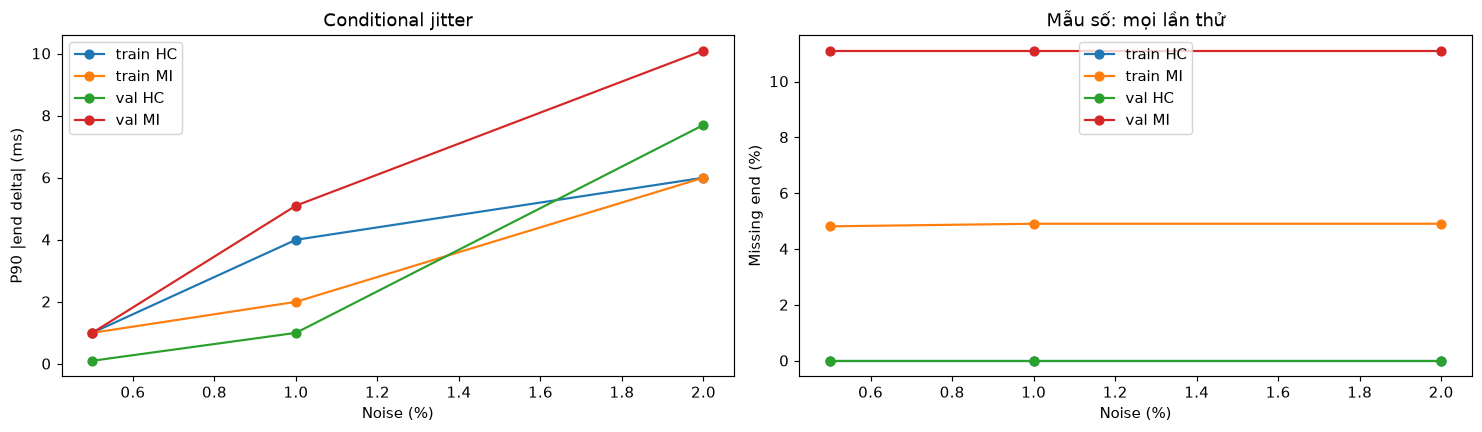

In [23]:
v4_e3=pd.DataFrame();v4_e3_errors=pd.DataFrame()
if V4_RUN_E3:
    v4_e3,v4_e3_errors=v4_e3_cohort(v4_development,V4_PROVISIONAL)
v4_table("E3_trials",v4_e3)
v4_table("E3_errors",v4_e3_errors)
v4_t4=v4_e3_summary(v4_e3)
v4_table("T4_development",v4_t4)
if not v4_t4.empty:
    main=v4_t4[v4_t4.method.eq("V4_median") & v4_t4.kind.eq("noise")]
    fig,ax=plt.subplots(1,2,figsize=(14,4),layout="constrained")
    for (s,l),g in main.groupby(["split","label"]):
        ax[0].plot(g.level*100,g.jitter_p90_abs_ms,"o-",label=s+" "+l)
        ax[1].plot(g.level*100,g.missing_pct,"o-",label=s+" "+l)
    ax[0].set(xlabel="Noise (%)",ylabel="P90 |end delta| (ms)",title="Conditional jitter")
    ax[1].set(xlabel="Noise (%)",ylabel="Missing end (%)",title="Mẫu số: mọi lần thử")
    for a in ax:
        if a.has_data():a.legend()
        else:a.text(.5,.5,"Không có số đo hợp lệ",ha="center",transform=a.transAxes)
    v4_show(fig,"E3_jitter_missing_development")


### 10C. E1 synthetic validation

Không dùng diagnosis PTB. Validation synthetic có truth nên được phép tính MAE/bias, nhưng waveform generator chỉ là mô hình do project đặt. Nếu có bias rõ, sửa phương pháp bằng development và tạo run mới, không sửa sau khi xem test.

E1_synthetic_validation_records: 15,552 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,patient_id,subject,fs_hz,shape,amplitude_mV,noise_fraction,drift_mV,method,valid,error_ms,truth_end_ms,error
0,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,V2_offset,False,NaN,392.0,
1,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,V1_threshold,True,-20.0,392.0,
2,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,Trapezium,True,-12.0,392.0,
3,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,Integral,True,-36.0,392.0,
4,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,V4_median,True,-20.0,392.0,
5,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,no_Trapezium,True,-28.0,392.0,
6,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,no_Integral,True,-16.0,392.0,
7,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.00,no_V2,True,-20.0,392.0,
8,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.02,V2_offset,False,NaN,392.0,
9,synthetic_validation,synthetic,synthetic_validation_000,0,250,symmetric,0.08,0.00,0.02,V1_threshold,True,-64.0,392.0,


T2_synthetic_validation: 1,296 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,fs_hz,shape,amplitude_mV,noise_fraction,drift_mV,n_attempted,n_patients,n_measured,missing_pct,bias_ms,mae_ms,p90_abs_error_ms
0,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.00,0.00,12,12,12,0.000000,-65.333333,65.333333,72.0
1,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.00,0.02,12,12,12,0.000000,89.333333,128.000000,174.8
2,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.01,0.00,12,12,12,0.000000,-55.333333,55.333333,71.6
3,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.01,0.02,12,12,12,0.000000,73.666667,108.333333,156.0
4,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.03,0.00,12,12,12,0.000000,-17.000000,55.666667,75.2
5,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.03,0.02,12,12,9,25.000000,95.555556,123.111111,169.6
6,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.00,0.00,12,12,12,0.000000,-65.333333,65.333333,72.0
7,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.00,0.02,12,12,12,0.000000,64.000000,99.333333,143.6
8,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.01,0.00,12,12,12,0.000000,-63.000000,63.000000,75.6
9,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.01,0.02,12,12,12,0.000000,30.000000,84.666667,132.8


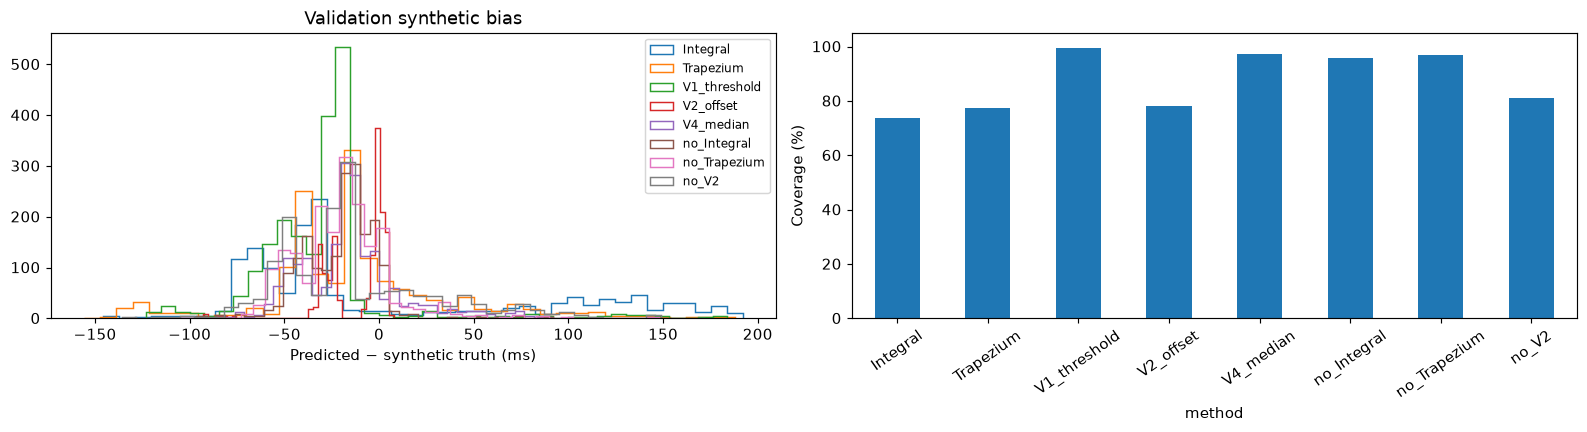

c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out,

E5_voter_selection_development: 4 dòng; xem 4 dòng đầu; CSV giữ đủ.


,method,e1_mae_ms,e3_jitter_p90_ms,e0_coverage_pct
0,V2_offset,12.684418,0.00,89.789790
2,Trapezium,37.479416,2.55,82.582583
1,V1_threshold,39.654762,1.80,96.396396
3,Integral,69.609331,3.00,80.180180


Voter khóa sau train/validation: ('V2_offset', 'Trapezium', 'V1_threshold')


In [26]:
v4_synth_validation=v4_e1("synthetic_validation") if V4_RUN_SYNTHETIC else pd.DataFrame()
v4_table("E1_synthetic_validation_records",v4_synth_validation)
v4_table("T2_synthetic_validation",v4_e1_summary(v4_synth_validation))
if not v4_synth_validation.empty:
    visual=v4_synth_validation.copy();visual["error_ms"]=pd.to_numeric(visual.error_ms,errors="coerce")
    fig,ax=plt.subplots(1,2,figsize=(15,4),layout="constrained")
    for m,g in visual.groupby("method"):
        ok=g.error_ms.dropna()
        if len(ok):ax[0].hist(ok,bins=40,histtype="step",label=m)
    visual.groupby("method").valid.mean().mul(100).plot.bar(ax=ax[1],rot=35)
    ax[0].set(xlabel="Predicted − synthetic truth (ms)",title="Validation synthetic bias");ax[0].legend(fontsize=8)
    ax[1].set(ylabel="Coverage (%)",ylim=(0,105))
    v4_show(fig,"E1_synthetic_validation")

def v4_select_voters(e1,e3,provisional):
    # Pre-declared order: E1 MAE, E3 jitter, then E0 coverage.
    if e1.empty or e3.empty:raise RuntimeError("Bật E1 synthetic và E3 development trước khi chọn voter")
    e3_summary=v4_e3_summary(e3)
    rows=[]
    for method in V4_BASE_METHODS:
        a=e1[(e1.split=="synthetic_validation")&(e1.method==method)]
        t=e3_summary[(e3_summary.split.isin(["train","val"]))&
                        (e3_summary.method==method)&(e3_summary.kind=="noise")&
                        (e3_summary.paired_n>0)]
        p=provisional[(provisional.split.isin(["train","val"]))&(provisional.method==method)&(provisional.loop_variant=="STT")]
        rows.append(dict(method=method,e1_mae_ms=float(a.error_ms.abs().mean()) if len(a) else np.inf,
            e3_jitter_p90_ms=float(t.jitter_p90_abs_ms.median()) if len(t) else np.inf,
            e0_coverage_pct=float(p.valid_end.mean()*100) if len(p) else 0.))
    ranking=pd.DataFrame(rows).sort_values(["e1_mae_ms","e3_jitter_p90_ms","e0_coverage_pct","method"],ascending=[True,True,False,True])
    selected=tuple(ranking.method.head(3))
    if len(selected)<3:raise RuntimeError("Không đủ 3 voter sau E1-E3")
    return selected,ranking
V4_ACTIVE_METHODS,v4_voter_ranking=v4_select_voters(v4_synth_validation,v4_e3,v4_dev_provisional)
v4_table("E5_voter_selection_development",v4_voter_ranking)
print("Voter khóa sau train/validation:",V4_ACTIVE_METHODS)


### 10D. E4 trên mọi record development

Heatmap tập train và valid hiển thị riêng, không dùng test khảo sát. Khi baseline/feature gần zero, relative delta NaN là không xác định; xem paired_relative_n, không diễn giải NaN thành ổn định tuyệt đối.

E4 1/333
E4 10/333
E4 20/333
E4 30/333
E4 40/333
E4 50/333
E4 60/333
E4 70/333
E4 80/333
E4 90/333
E4 100/333
E4 110/333
E4 120/333
E4 130/333
E4 140/333
E4 150/333
E4 160/333
E4 170/333
E4 180/333
E4 190/333
E4 200/333
E4 210/333
E4 220/333
E4 230/333
E4 240/333
E4 250/333
E4 260/333
E4 270/333
E4 280/333
E4 290/333
E4 300/333
E4 310/333
E4 320/333
E4 330/333
E4 333/333
E4_shift_records: 415,584 dòng; xem 24 dòng đầu; CSV giữ đủ.


,method,loop_variant,shift_ms,feature,valid,reason,baseline,value,abs_delta,relative_abs_pct,angular_abs_deg,record_id,patient_id,split,label
0,V2_offset,STT,-20,T_MaxVec,True,,0.298988,0.298988,0.000000,0.000000,NaN,patient001/s0010_re,patient001,train,MI
1,V2_offset,STT,-20,T_Area,True,,0.017931,0.017892,0.000039,0.216574,NaN,patient001/s0010_re,patient001,train,MI
2,V2_offset,STT,-20,T_MaxVel,True,,5.179915,5.179915,0.000000,0.000000,NaN,patient001/s0010_re,patient001,train,MI
3,V2_offset,STT,-20,T_MeanVel,True,,2.166438,2.230962,0.064524,2.978357,NaN,patient001/s0010_re,patient001,train,MI
4,V2_offset,STT,-20,T_StdVel,True,,1.214074,1.222337,0.008263,0.680605,NaN,patient001/s0010_re,patient001,train,MI
5,V2_offset,STT,-20,T_Arc,True,,0.710104,0.675827,0.034277,4.827063,NaN,patient001/s0010_re,patient001,train,MI
6,V2_offset,STT,-20,Spatial_QRS_T_Angle_deg,True,,41.260397,41.973139,0.712741,NaN,0.712741,patient001/s0010_re,patient001,train,MI
7,V2_offset,STT,-20,VG_X_mVs,True,,-0.014932,-0.014592,0.000340,2.279622,NaN,patient001/s0010_re,patient001,train,MI
8,V2_offset,STT,-20,VG_Y_mVs,True,,-0.048757,-0.047167,0.001590,3.261386,NaN,patient001/s0010_re,patient001,train,MI
9,V2_offset,STT,-20,VG_Z_mVs,True,,0.025688,0.025400,0.000288,1.121570,NaN,patient001/s0010_re,patient001,train,MI


T5_development: 4,992 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,feature,shift_ms,n_attempted,n_patients,n_valid,paired_relative_n,median_abs_relative_pct,p90_abs_relative_pct,median_abs_delta,median_angular_abs_deg
0,train,HC,Integral,STT,Spatial_QRS_T_Angle_deg,-20,47,31,45,0,NaN,NaN,0.492838,0.492838
1,train,HC,Integral,STT,Spatial_QRS_T_Angle_deg,-10,47,31,45,0,NaN,NaN,0.237622,0.237622
2,train,HC,Integral,STT,Spatial_QRS_T_Angle_deg,-5,47,31,45,0,NaN,NaN,0.120765,0.120765
3,train,HC,Integral,STT,Spatial_QRS_T_Angle_deg,5,47,31,45,0,NaN,NaN,0.108465,0.108465
4,train,HC,Integral,STT,Spatial_QRS_T_Angle_deg,10,47,31,45,0,NaN,NaN,0.212528,0.212528
5,train,HC,Integral,STT,Spatial_QRS_T_Angle_deg,20,47,31,45,0,NaN,NaN,0.377146,0.377146
6,train,HC,Integral,STT,T_Arc,-20,47,31,45,45,18.036055,22.014657,0.178893,NaN
7,train,HC,Integral,STT,T_Arc,-10,47,31,45,45,8.629414,10.537781,0.083115,NaN
8,train,HC,Integral,STT,T_Arc,-5,47,31,45,45,4.143214,5.161372,0.038635,NaN
9,train,HC,Integral,STT,T_Arc,5,47,31,45,45,3.487296,4.432455,0.031983,NaN


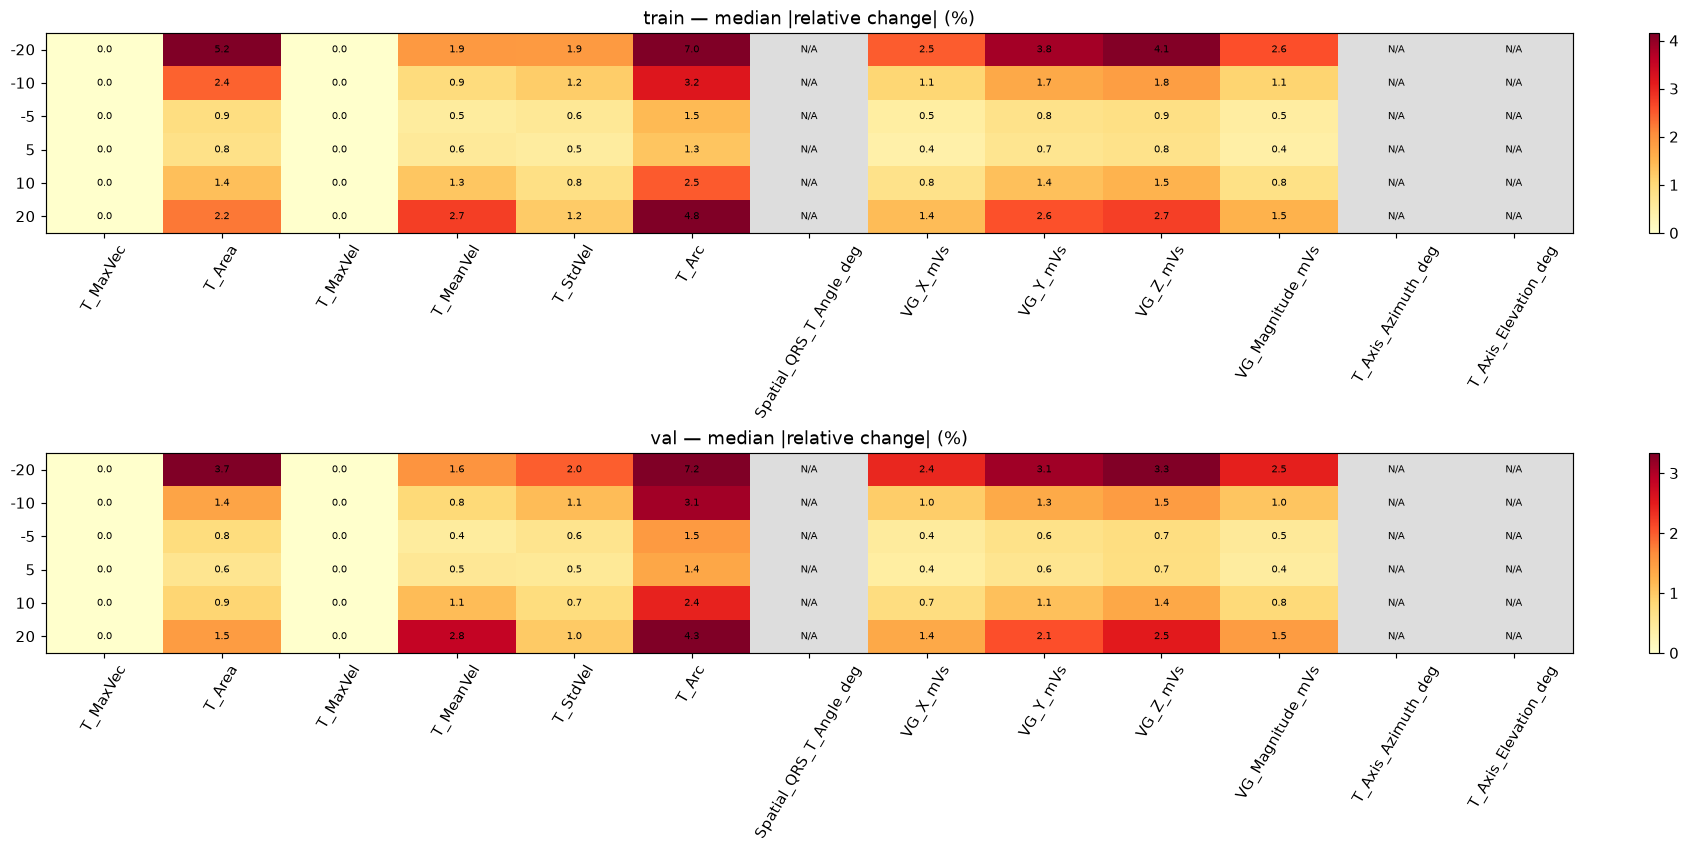

E4_train_feature_sensitivity_flags: 13 dòng; xem 13 dòng đầu; CSV giữ đủ.


,feature,n_attempted,n_patients,paired_n,median_abs_relative_pct,sensitive_gt20pct,split,label
0,Spatial_QRS_T_Angle_deg,263,120,0,NaN,False,train,all_labels_unlabeled_calibration
1,T_Arc,263,120,1512,2.780218,False,train,all_labels_unlabeled_calibration
2,T_Area,263,120,1512,1.612256,False,train,all_labels_unlabeled_calibration
3,T_Axis_Azimuth_deg,263,120,0,NaN,False,train,all_labels_unlabeled_calibration
4,T_Axis_Elevation_deg,263,120,0,NaN,False,train,all_labels_unlabeled_calibration
5,T_MaxVec,263,120,1512,0.000000,False,train,all_labels_unlabeled_calibration
6,T_MaxVel,263,120,1512,0.000000,False,train,all_labels_unlabeled_calibration
7,T_MeanVel,263,120,1512,1.031362,False,train,all_labels_unlabeled_calibration
8,T_StdVel,263,120,1512,0.811440,False,train,all_labels_unlabeled_calibration
9,VG_Magnitude_mVs,263,120,1512,0.902318,False,train,all_labels_unlabeled_calibration


In [27]:
v4_e4=v4_e4_cohort(v4_development,V4_PROVISIONAL) if V4_RUN_E4 else pd.DataFrame()
v4_table("E4_shift_records",v4_e4)
v4_t5=v4_e4_summary(v4_e4);v4_table("T5_development",v4_t5)
v4_feature_flags=pd.DataFrame()
if not v4_e4.empty:
    vis=v4_e4[(v4_e4.method=="V4_median")&(v4_e4.loop_variant=="STT")]
    fig,axes=plt.subplots(2,1,figsize=(16,8),layout="constrained")
    for split,ax in zip(("train","val"),axes):
        part=vis[vis.split.eq(split)]
        grid=part.pivot_table(index="shift_ms",columns="feature",values="relative_abs_pct",aggfunc="median").reindex(index=V4_SHIFTS,columns=V4_T_FEATURES)
        values=grid.to_numpy(dtype=float);cmap=plt.get_cmap("YlOrRd").copy();cmap.set_bad("#dddddd")
        finite=values[np.isfinite(values)];vmax=max(float(np.quantile(finite,.95)),1.) if len(finite) else 1.
        im=ax.imshow(np.ma.masked_invalid(values),aspect="auto",vmin=0,vmax=vmax,cmap=cmap)
        ax.set(yticks=range(len(grid)),yticklabels=grid.index,xticks=range(len(grid.columns)),
            xticklabels=grid.columns,title=split+" — median |relative change| (%)")
        for (i,j),v in np.ndenumerate(values):
            ax.text(j,i,f"{v:.1f}" if np.isfinite(v) else "N/A",ha="center",va="center",fontsize=7)
        ax.tick_params(axis="x",rotation=60);fig.colorbar(im,ax=ax)
    v4_show(fig,"E4_feature_sensitivity_development")
    v4_feature_flags=vis[vis.split.eq("train")].groupby("feature").agg(
        n_attempted=("record_id","nunique"),n_patients=("patient_id","nunique"),
        paired_n=("relative_abs_pct","count"),median_abs_relative_pct=("relative_abs_pct","median")).reset_index()
    v4_feature_flags["sensitive_gt20pct"]=v4_feature_flags.median_abs_relative_pct.gt(20)
    v4_feature_flags["split"]="train";v4_feature_flags["label"]="all_labels_unlabeled_calibration"
v4_table("E4_train_feature_sensitivity_flags",v4_feature_flags)


## 11. Calibration trên train, kiểm tra trên validation và khóa cấu hình

Ngưỡng không lấy từ test:

- uncertainty: phân vị 90% của V4_median có đủ estimator trên train, chặn trong 10–80 ms;
- QT: phân vị 1–99% candidate train, nhưng không vượt guardrail 250–550 ms;
- cần ít nhất 20 cặp train, nếu thiếu notebook dừng thay vì dùng test bù;
- validation chỉ hiển thị coverage/QT/QTc/jitter với ngưỡng đã lấy từ train. Notebook không tự điều chỉnh lại theo validation.

Bản khóa chứa protocol, calibration data hash, ngưỡng, danh sách train/valid/test patient và source hashes. Test receipt gắn với lock hash và run name; nếu đã có receipt khác, cell test dừng để tránh ghi đè lịch sử.

In [28]:
# Re-run development with the three voters locked from E1-E3 before calibration.
v4_dev_provisional,v4_dev_errors=v4_cohort(v4_development,V4_PROVISIONAL,"development_selected")
def v4_calibrate(train_frame):
    source=train_frame[(train_frame.split=="train")&(train_frame.method=="V4_median")&
                       (train_frame.loop_variant=="STT")&train_frame.valid_end].copy()
    u=source.uncertainty_ms.dropna()
    qt=source.qt_ms.dropna()
    minimum=V4_CALIBRATION["min_train_pairs"]
    if len(u)<minimum or len(qt)<minimum:
        raise RuntimeError(f"Không đủ train candidate để calibration: uncertainty={len(u)}, QT={len(qt)}")
    ulo,uhi=V4_CALIBRATION["uncertainty_clip_ms"]
    qlo,qhi=V4_CALIBRATION["qt_guardrail_ms"]
    p0,p1=V4_CALIBRATION["qt_quantiles"]
    return dict(
        uncertainty_ms=float(np.clip(u.quantile(V4_CALIBRATION["uncertainty_quantile"]),ulo,uhi)),
        qt_min_ms=float(max(qlo,qt.quantile(p0))),
        qt_max_ms=float(min(qhi,qt.quantile(p1))),
        calibration_split="train_only",
        n_train_uncertainty=int(len(u)),n_train_qt=int(len(qt)),
        n_train_patients=int(source.patient_id.nunique()),
        source_record_sha256=v4_digest(sorted(source.record_id.tolist())),
        uncertainty_rule="train p90 clipped 10..80 ms",
        qt_rule="train p01..p99 intersect 250..550 ms")
v4_screen=v4_calibrate(v4_dev_provisional)
display(pd.Series(v4_screen).to_frame("locked value"))

# Tính lại trạng thái bằng candidate/end đã lưu, không chạy lại thuật toán.
def v4_rescreen(frame,screen):
    result=frame.copy()
    method_error=result.error_flags.fillna("").str.split(";").apply(
        lambda xs:[x for x in xs if x not in ("uncertainty_high","qt_implausible")])
    for i,xs in method_error.items():
        if result.at[i,"valid_end"]:
            if not screen["qt_min_ms"]<=result.at[i,"qt_ms"]<=screen["qt_max_ms"]:xs.append("qt_implausible")
            if np.isfinite(result.at[i,"uncertainty_ms"]) and result.at[i,"uncertainty_ms"]>screen["uncertainty_ms"]:
                xs.append("uncertainty_high")
        result.at[i,"error_flags"]=";".join(sorted(set(xs)))
        result.at[i,"status"]="unresolved" if not result.at[i,"valid_end"] else "needs_review" if xs else "accepted"
        result.at[i,"accepted"]=bool(result.at[i,"status"]=="accepted" and result.at[i,"loop_valid"])
    return result
v4_dev=v4_rescreen(v4_dev_provisional,v4_screen)
v4_t1_dev=v4_coverage(v4_dev);v4_t3_dev=v4_qt_summary(v4_dev)
v4_table("T1_development_locked",v4_t1_dev)
v4_table("T3_development_locked",v4_t3_dev)

v4_lock=dict(protocol_id=V4_PROTOCOL_ID,screen=v4_screen,selected_voters=list(V4_ACTIVE_METHODS),
    voter_selection_rule="train/validation E1 MAE -> E3 jitter -> E0 coverage; top 3",
    train_patients=sorted(V4_SPLIT.loc[V4_SPLIT.split.eq("train"),"patient_id"].unique()),
    val_patients=sorted(V4_SPLIT.loc[V4_SPLIT.split.eq("val"),"patient_id"].unique()),
    test_patients=sorted(V4_SPLIT.loc[V4_SPLIT.split.eq("test"),"patient_id"].unique()),
    development_record_sha256=v4_digest(sorted(v4_development.record_id.tolist())),
    source_sha256=V4_PROTOCOL["sources"],created_after="E0-E4 development")
v4_lock["lock_sha256"]=v4_digest(v4_lock)
if V4_SAVE:v4_json(V4_OUT/"locked_config.json",v4_lock)
print("LOCKED:",v4_lock["lock_sha256"])
assert set(v4_lock["train_patients"]).isdisjoint(v4_lock["val_patients"])
assert set(v4_lock["train_patients"]).isdisjoint(v4_lock["test_patients"])
assert set(v4_lock["val_patients"]).isdisjoint(v4_lock["test_patients"])


development_selected 1/333 | cache=0 | errors=0
development_selected 10/333 | cache=0 | errors=0
development_selected 20/333 | cache=0 | errors=0
development_selected 30/333 | cache=0 | errors=0
development_selected 40/333 | cache=0 | errors=0
development_selected 50/333 | cache=0 | errors=0
development_selected 60/333 | cache=0 | errors=0
development_selected 70/333 | cache=0 | errors=0
development_selected 80/333 | cache=0 | errors=0
development_selected 90/333 | cache=0 | errors=1
development_selected 100/333 | cache=0 | errors=2
development_selected 110/333 | cache=0 | errors=2
development_selected 120/333 | cache=0 | errors=2
development_selected 130/333 | cache=0 | errors=2
development_selected 140/333 | cache=0 | errors=2
development_selected 150/333 | cache=0 | errors=2
development_selected 160/333 | cache=0 | errors=2
development_selected 170/333 | cache=0 | errors=2
development_selected 180/333 | cache=0 | errors=4
development_selected 190/333 | cache=0 | errors=4
development

,locked value
uncertainty_ms,80.0
qt_min_ms,295.06
qt_max_ms,517.49
calibration_split,train_only
n_train_uncertainty,252
n_train_qt,252
n_train_patients,116
source_record_sha256,3106f1ed00ebff3dd331bd27aea83ea011c546874134ca...
uncertainty_rule,train p90 clipped 10..80 ms
qt_rule,train p01..p99 intersect 250..550 ms


T1_development_locked: 64 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted,n_patients,has_median_n,has_median_pct,has_qrs_n,has_qrs_pct,has_t_peak_n,has_t_peak_pct,valid_end_n,valid_end_pct,loop_valid_n,loop_valid_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,status_accepted_n,status_needs_review_n,status_unresolved_n,missing_end_pct
0,train,MI,V2_offset,STT,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,190,87.962963,0,0.000000,190,87.962963,0,190,26,12.037037
1,train,MI,V2_offset,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,26,12.037037,0,0.000000,26,12.037037,0,190,26,12.037037
2,train,MI,V1_threshold,STT,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,208,96.296296,0,0.000000,208,96.296296,0,208,8,3.703704
3,train,MI,V1_threshold,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,27,12.500000,0,0.000000,27,12.500000,0,208,8,3.703704
4,train,MI,Trapezium,STT,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,172,79.629630,0,0.000000,172,79.629630,0,172,44,20.370370
5,train,MI,Trapezium,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,24,11.111111,0,0.000000,24,11.111111,0,172,44,20.370370
6,train,MI,Integral,STT,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,166,76.851852,0,0.000000,166,76.851852,0,166,50,23.148148
7,train,MI,Integral,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,23,10.648148,0,0.000000,23,10.648148,0,166,50,23.148148
8,train,MI,V4_median,STT,216,89,213,98.611111,213,98.611111,212,98.148148,205,94.907407,205,94.907407,38,17.592593,205,94.907407,38,167,11,5.092593
9,train,MI,V4_median,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,205,94.907407,27,12.500000,7,3.240741,27,12.500000,7,198,11,5.092593


T3_development_locked: 64 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted,n_patients,n_measured,n_patients_measured,qt_outside_250_550_pct,qt_rr_slope_ms_per_s,qt_rr_intercept_ms,qtc_p5_ms,qtc_p25_ms,qtc_p50_ms,qtc_p75_ms,qtc_p95_ms
0,train,MI,V2_offset,STT,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326
1,train,MI,V2_offset,pure_T,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326
2,train,MI,V1_threshold,STT,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395
3,train,MI,V1_threshold,pure_T,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395
4,train,MI,Trapezium,STT,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871
5,train,MI,Trapezium,pure_T,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871
6,train,MI,Integral,STT,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033
7,train,MI,Integral,pure_T,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033
8,train,MI,V4_median,STT,216,89,205,85,0.000000,171.847095,237.457573,350.365549,383.157460,402.052957,423.080615,465.609994
9,train,MI,V4_median,pure_T,216,89,205,85,0.000000,171.847095,237.457573,350.365549,383.157460,402.052957,423.080615,465.609994


LOCKED: d91b895109ba27cd64194ea22ae36fc688189f79fc68b9667679180ff6a197e2


### 11A. Validation audit trước test

Đọc T1/T3/T4/T5 validation với config khóa. Nếu quyết định sửa method/ngưỡng, dừng tại đây, sửa notebook, đổi V4_RUN_NAME và chạy lại từ đầu. Cell không có logic “chọn best” theo validation hay downstream AUC.

In [29]:
v4_validation_audit=v4_t1_dev[v4_t1_dev.split.eq("val")].merge(
    v4_t3_dev[v4_t3_dev.split.eq("val")],
    on=["split","label","method","loop_variant"],suffixes=("_coverage","_physiology"),validate="one_to_one")
v4_table("validation_pretest_audit",v4_validation_audit)
if not v4_t4.empty:v4_table("validation_E3_audit",v4_t4[v4_t4.split.eq("val")])
if not v4_t5.empty:v4_table("validation_E4_audit",v4_t5[v4_t5.split.eq("val")])
print("Không tự cập nhật v4_screen từ validation. Muốn đổi cấu hình: dừng, sửa, đổi run name.")


validation_pretest_audit: 32 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted_coverage,n_patients_coverage,has_median_n,has_median_pct,has_qrs_n,has_qrs_pct,has_t_peak_n,has_t_peak_pct,valid_end_n,valid_end_pct,loop_valid_n,loop_valid_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,status_accepted_n,status_needs_review_n,status_unresolved_n,missing_end_pct,n_attempted_physiology,n_patients_physiology,n_measured,n_patients_measured,qt_outside_250_550_pct,qt_rr_slope_ms_per_s,qt_rr_intercept_ms,qtc_p5_ms,qtc_p25_ms,qtc_p50_ms,qtc_p75_ms,qtc_p95_ms
0,val,MI,V2_offset,STT,54,22,52,96.296296,52,96.296296,51,94.444444,46,85.185185,46,85.185185,0,0.000000,46,85.185185,0,46,8,14.814815,54,22,46,20,0.0,160.888592,250.740702,358.174102,390.398377,413.865602,424.201260,465.245311
1,val,MI,V2_offset,pure_T,54,22,52,96.296296,52,96.296296,51,94.444444,46,85.185185,1,1.851852,0,0.000000,1,1.851852,0,46,8,14.814815,54,22,46,20,0.0,160.888592,250.740702,358.174102,390.398377,413.865602,424.201260,465.245311
2,val,MI,V1_threshold,STT,54,22,52,96.296296,52,96.296296,51,94.444444,50,92.592593,50,92.592593,0,0.000000,50,92.592593,0,50,4,7.407407,54,22,50,21,0.0,157.257986,244.656919,330.462632,376.942144,391.529535,422.912702,490.919404
3,val,MI,V1_threshold,pure_T,54,22,52,96.296296,52,96.296296,51,94.444444,50,92.592593,1,1.851852,0,0.000000,1,1.851852,0,50,4,7.407407,54,22,50,21,0.0,157.257986,244.656919,330.462632,376.942144,391.529535,422.912702,490.919404
4,val,MI,Trapezium,STT,54,22,52,96.296296,52,96.296296,51,94.444444,41,75.925926,41,75.925926,0,0.000000,41,75.925926,0,41,13,24.074074,54,22,41,20,0.0,108.091697,291.749243,351.222170,371.837874,399.728020,438.703871,500.588489
5,val,MI,Trapezium,pure_T,54,22,52,96.296296,52,96.296296,51,94.444444,41,75.925926,1,1.851852,0,0.000000,1,1.851852,0,41,13,24.074074,54,22,41,20,0.0,108.091697,291.749243,351.222170,371.837874,399.728020,438.703871,500.588489
6,val,MI,Integral,STT,54,22,52,96.296296,52,96.296296,51,94.444444,40,74.074074,40,74.074074,0,0.000000,40,74.074074,0,40,14,25.925926,54,22,40,20,10.0,81.606245,334.943452,338.075821,360.792773,401.594034,487.666237,569.960185
7,val,MI,Integral,pure_T,54,22,52,96.296296,52,96.296296,51,94.444444,40,74.074074,1,1.851852,0,0.000000,1,1.851852,0,40,14,25.925926,54,22,40,20,10.0,81.606245,334.943452,338.075821,360.792773,401.594034,487.666237,569.960185
8,val,MI,V4_median,STT,54,22,52,96.296296,52,96.296296,51,94.444444,48,88.888889,48,88.888889,12,22.222222,48,88.888889,12,36,6,11.111111,54,22,48,20,0.0,141.633384,261.682596,359.522227,379.543498,400.340758,423.062490,471.099824
9,val,MI,V4_median,pure_T,54,22,52,96.296296,52,96.296296,51,94.444444,48,88.888889,1,1.851852,1,1.851852,1,1.851852,1,47,6,11.111111,54,22,48,20,0.0,141.633384,261.682596,359.522227,379.543498,400.340758,423.062490,471.099824


validation_E3_audit: 88 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,kind,level,n_attempted,n_patients,n_trials,n_valid,missing_pct,paired_n,paired_pct,valid_retention_pct,jitter_median_abs_ms,jitter_p90_abs_ms,delta_bias_ms,median_within_record_IQR_ms
40,val,MI,V2_offset,beat,0.000,52,22,1868,1533,17.933619,1521,81.423983,95.181477,2.0,11.0,0.179487,4.0
41,val,MI,V1_threshold,beat,0.000,52,22,1868,1727,7.548180,1684,90.149893,95.519002,14.0,74.0,-13.558789,18.5
42,val,MI,Trapezium,beat,0.000,52,22,1868,1239,33.672377,1134,60.706638,78.586279,18.0,79.0,4.574074,54.5
43,val,MI,Integral,beat,0.000,52,22,1868,1216,34.903640,1074,57.494647,77.099785,22.0,175.7,0.334264,72.0
44,val,MI,V4_median,beat,0.000,52,22,1868,1667,10.760171,1601,85.706638,94.231901,14.0,59.0,-1.763273,28.0
45,val,MI,no_Trapezium,beat,0.000,52,22,1868,1625,13.008565,1541,82.494647,93.450576,11.0,35.0,-5.599611,19.0
46,val,MI,no_Integral,beat,0.000,52,22,1868,1649,11.723769,1596,85.438972,93.937610,11.0,32.0,-5.136591,16.5
47,val,MI,no_V2,beat,0.000,52,22,1868,1307,30.032120,1172,62.740899,81.219681,19.0,77.9,2.337884,46.0
48,val,MI,V2_offset,noise,0.005,54,22,270,230,14.814815,230,85.185185,100.000000,0.0,0.0,0.026087,0.0
49,val,MI,V1_threshold,noise,0.005,54,22,270,250,7.407407,250,92.592593,100.000000,0.0,1.0,0.920000,0.0


validation_E4_audit: 2,496 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,feature,shift_ms,n_attempted,n_patients,n_valid,paired_relative_n,median_abs_relative_pct,p90_abs_relative_pct,median_abs_delta,median_angular_abs_deg
2496,val,HC,Integral,STT,Spatial_QRS_T_Angle_deg,-20,16,8,16,0,NaN,NaN,1.362003,1.362003
2497,val,HC,Integral,STT,Spatial_QRS_T_Angle_deg,-10,16,8,16,0,NaN,NaN,0.522842,0.522842
2498,val,HC,Integral,STT,Spatial_QRS_T_Angle_deg,-5,16,8,16,0,NaN,NaN,0.229685,0.229685
2499,val,HC,Integral,STT,Spatial_QRS_T_Angle_deg,5,16,8,16,0,NaN,NaN,0.173473,0.173473
2500,val,HC,Integral,STT,Spatial_QRS_T_Angle_deg,10,16,8,16,0,NaN,NaN,0.299604,0.299604
2501,val,HC,Integral,STT,Spatial_QRS_T_Angle_deg,20,16,8,16,0,NaN,NaN,0.446656,0.446656
2502,val,HC,Integral,STT,T_Arc,-20,16,8,16,16,17.235897,19.019726,0.178343,NaN
2503,val,HC,Integral,STT,T_Arc,-10,16,8,16,16,8.048460,9.242931,0.085682,NaN
2504,val,HC,Integral,STT,T_Arc,-5,16,8,16,16,3.825119,4.515170,0.040765,NaN
2505,val,HC,Integral,STT,T_Arc,5,16,8,16,16,3.509344,4.081106,0.037830,NaN


Không tự cập nhật v4_screen từ validation. Muốn đổi cấu hình: dừng, sửa, đổi run name.


## 12. Chạy test đúng một cấu hình đã khóa

Cell test chỉ chạy sau lock. Receipt lưu lock hash, protocol, thời gian UTC và hash danh sách test. Test không chạy E3/E4/sweep/calibration. Nếu receipt cùng run name đã tồn tại nhưng khác lock, notebook dừng; cùng lock thì có thể resume checkpoint mà không tạo một phép chọn mới.

“Đúng một lần” ở đây được thực thi theo artifact/run name trong project. Nó không thể ngăn người dùng xóa output hoặc sao chép notebook, nên báo cáo vẫn phải ghi lịch sử run.

In [30]:
v4_test=V4_SPLIT[V4_SPLIT.split.eq("test")].copy()
v4_receipt_path=V4_OUT/"test_receipt.json"
v4_receipt_identity=dict(run_name=V4_RUN_NAME,protocol_id=V4_PROTOCOL_ID,
    lock_sha256=v4_lock["lock_sha256"],test_record_sha256=v4_digest(sorted(v4_test.record_id.tolist())),
    n_test=len(v4_test),n_test_patients=v4_test.patient_id.nunique())
if V4_RUN_TEST:
    if v4_receipt_path.is_file():
        receipt=json.loads(v4_receipt_path.read_text(encoding="utf-8"))
        prior={k:receipt[k] for k in v4_receipt_identity}
        if prior!=v4_receipt_identity:
            raise RuntimeError("Test receipt khác lock/config. Đổi V4_RUN_NAME; không ghi đè lần test cũ.")
        print("Resume đúng test receipt đã có:",receipt)
    v4_test_frame,v4_test_errors=v4_cohort(v4_test,v4_screen,"locked_test")
    if V4_SAVE and not v4_receipt_path.is_file():
        from datetime import datetime,timezone
        v4_json(v4_receipt_path,{**v4_receipt_identity,
            "created_utc":datetime.now(timezone.utc).isoformat(),
            "policy":"fixed locked config; no E3/E4/option sweep on test"})
else:
    v4_test_frame=pd.DataFrame(columns=v4_dev.columns)
    v4_test_errors=pd.DataFrame()
v4_all=pd.concat([v4_dev,v4_test_frame],ignore_index=True)
assert set(v4_all[v4_all.split.eq("train")].patient_id).isdisjoint(set(v4_all[v4_all.split.eq("test")].patient_id))
v4_table("locked_test_errors",v4_test_errors)
print("Locked rows:",len(v4_all),"expected:",len(V4_SPLIT)*len(V4_VARIANTS) if V4_RUN_TEST else "development only")


locked_test 1/115 | cache=0 | errors=0
locked_test 10/115 | cache=0 | errors=0
locked_test 20/115 | cache=0 | errors=0
locked_test 30/115 | cache=0 | errors=0
locked_test 40/115 | cache=0 | errors=0
locked_test 50/115 | cache=0 | errors=0
locked_test 60/115 | cache=0 | errors=0
locked_test 70/115 | cache=0 | errors=0
locked_test 80/115 | cache=0 | errors=0
locked_test 90/115 | cache=0 | errors=0
locked_test 100/115 | cache=0 | errors=0
locked_test 110/115 | cache=0 | errors=0
locked_test 115/115 | cache=0 | errors=0
locked_test_errors: 0 dòng; xem 0 dòng đầu; CSV giữ đủ.


,record_id,patient_id,split,label,n_attempted,n_patients,error


Locked rows: 7168 expected: 7168


## 13. E0/T1 và F1/F2 — coverage, trạng thái, failure, uncertainty

F1 tách từng split × label, mẫu số là tất cả record. Single methods không có uncertainty nên không xuất trong F2; NaN không được đổi thành 0. F2 chỉ mô tả spread estimator của fusion. accepted rate phụ thuộc cờ lỗi/ngưỡng khóa, không phải accuracy.

T1_coverage_status: 96 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted,n_patients,has_median_n,has_median_pct,has_qrs_n,has_qrs_pct,has_t_peak_n,has_t_peak_pct,valid_end_n,valid_end_pct,loop_valid_n,loop_valid_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,status_accepted_n,status_needs_review_n,status_unresolved_n,missing_end_pct
0,train,MI,V2_offset,STT,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,190,87.962963,0,0.000000,190,87.962963,0,190,26,12.037037
1,train,MI,V2_offset,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,26,12.037037,0,0.000000,26,12.037037,0,190,26,12.037037
2,train,MI,V1_threshold,STT,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,208,96.296296,0,0.000000,208,96.296296,0,208,8,3.703704
3,train,MI,V1_threshold,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,27,12.500000,0,0.000000,27,12.500000,0,208,8,3.703704
4,train,MI,Trapezium,STT,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,172,79.629630,0,0.000000,172,79.629630,0,172,44,20.370370
5,train,MI,Trapezium,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,24,11.111111,0,0.000000,24,11.111111,0,172,44,20.370370
6,train,MI,Integral,STT,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,166,76.851852,0,0.000000,166,76.851852,0,166,50,23.148148
7,train,MI,Integral,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,23,10.648148,0,0.000000,23,10.648148,0,166,50,23.148148
8,train,MI,V4_median,STT,216,89,213,98.611111,213,98.611111,212,98.148148,205,94.907407,205,94.907407,38,17.592593,205,94.907407,38,167,11,5.092593
9,train,MI,V4_median,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,205,94.907407,27,12.500000,7,3.240741,27,12.500000,7,198,11,5.092593


T1_failure_reasons: 592 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,reason,n_flagged,n_attempted,n_patients
0,test,HC,Integral,STT,Integral:baseline_offset,14,17,13
1,test,HC,Integral,STT,t_end_unresolved_or_invalid_order,1,17,13
2,test,HC,Integral,pure_T,Integral:baseline_offset,14,17,13
3,test,HC,Integral,pure_T,onset_agreement_missing_or_invalid,16,17,13
4,test,HC,Integral,pure_T,t_end_unresolved_or_invalid_order,1,17,13
5,test,HC,Trapezium,STT,Trapezium:baseline_offset,15,17,13
6,test,HC,Trapezium,pure_T,Trapezium:baseline_offset,15,17,13
7,test,HC,Trapezium,pure_T,onset_agreement_missing_or_invalid,16,17,13
8,test,HC,V1_threshold,STT,V1_threshold:baseline_offset,15,17,13
9,test,HC,V1_threshold,pure_T,V1_threshold:baseline_offset,15,17,13


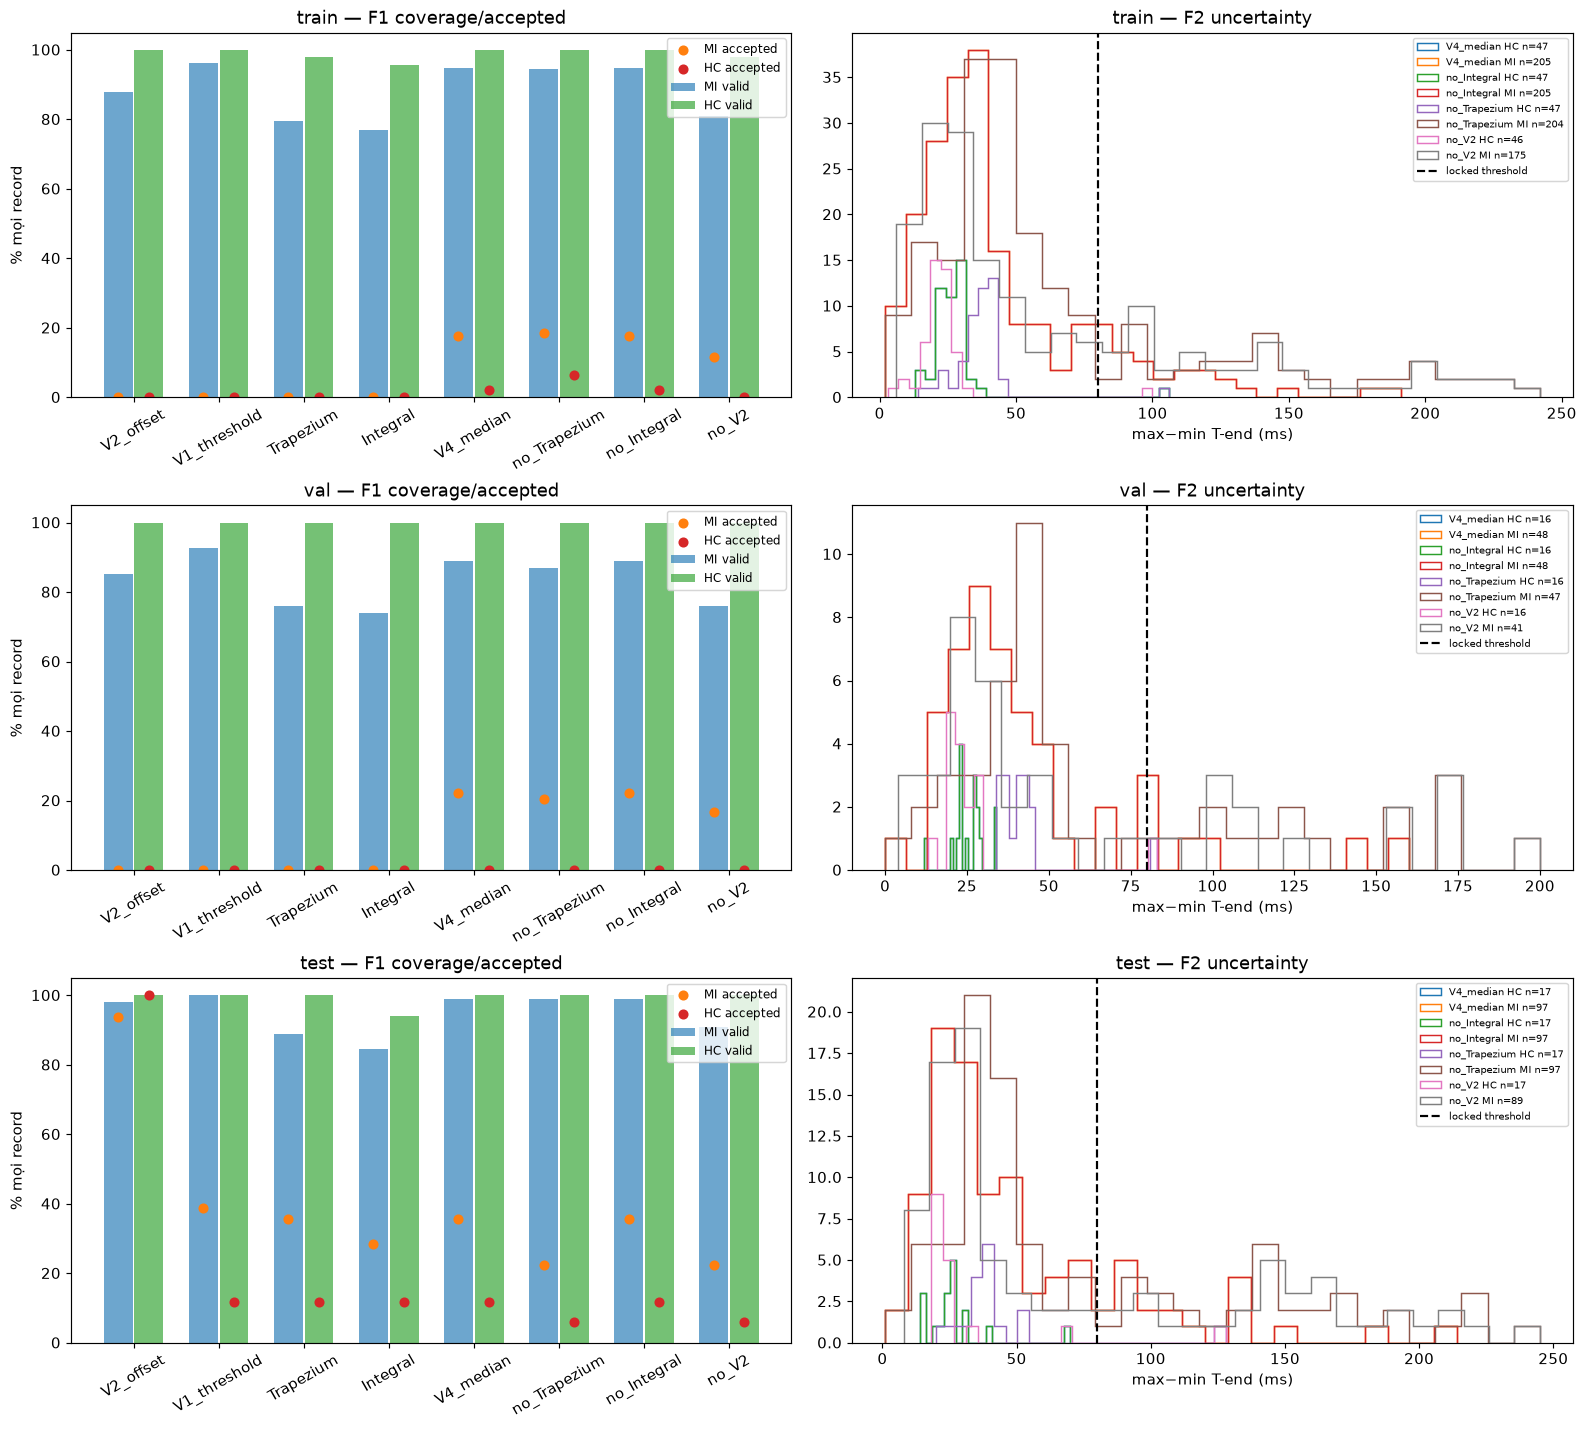

In [31]:
v4_t1=v4_coverage(v4_all);v4_failures=v4_failure_summary(v4_all)
v4_table("T1_coverage_status",v4_t1)
v4_table("T1_failure_reasons",v4_failures)
splits=[s for s in ("train","val","test") if s in set(v4_all.split)]
fig,axes=plt.subplots(len(splits),2,figsize=(15,4.5*len(splits)),squeeze=False,layout="constrained")
for split,axs in zip(splits,axes):
    part=v4_t1[(v4_t1.split.eq(split))&(v4_t1.loop_variant.eq("STT"))]
    labels=[]
    for i,(label,g) in enumerate(part.groupby("label",sort=False)):
        x=np.arange(len(V4_METHODS))+(-.18 if i==0 else .18)
        ordered=g.set_index("method").reindex(V4_METHODS)
        axs[0].bar(x,ordered.valid_end_pct,width=.34,label=label+" valid",alpha=.65)
        axs[0].scatter(x,ordered.accepted_pct,label=label+" accepted",s=35)
    axs[0].set(xticks=range(len(V4_METHODS)),xticklabels=V4_METHODS,ylim=(0,105),
               ylabel="% mọi record",title=split+" — F1 coverage/accepted")
    axs[0].tick_params(axis="x",rotation=30);axs[0].legend(fontsize=8)
    uncertainty=v4_all[(v4_all.split.eq(split))&(v4_all.loop_variant.eq("STT"))&
                       v4_all.method.isin(["V4_median","no_Trapezium","no_Integral","no_V2"])]
    for (method,label),g in uncertainty.groupby(["method","label"]):
        u=g.uncertainty_ms.dropna()
        if len(u):axs[1].hist(u,bins=25,histtype="step",label=f"{method} {label} n={len(u)}")
    axs[1].axvline(v4_screen["uncertainty_ms"],color="black",ls="--",label="locked threshold")
    axs[1].set(xlabel="max−min T-end (ms)",title=split+" — F2 uncertainty");axs[1].legend(fontsize=7)
v4_show(fig,"F1_F2_coverage_uncertainty")


## 14. E2/T3 và F3 — QT/QTc Fridericia

QT = T-end−QRS-on, QTcF=QT/RR^(1/3). HC 350–450 ms chỉ là vùng tham khảo mô tả; không gọi ngoài vùng là sai T-end và không dùng test sửa threshold. Regression QT~RR báo slope trên ca measured. HC ít nên mọi bảng giữ n_patients_measured.

T3_QT_QTc: 96 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted,n_patients,n_measured,n_patients_measured,qt_outside_250_550_pct,qt_rr_slope_ms_per_s,qt_rr_intercept_ms,qtc_p5_ms,qtc_p25_ms,qtc_p50_ms,qtc_p75_ms,qtc_p95_ms
0,train,MI,V2_offset,STT,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326
1,train,MI,V2_offset,pure_T,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326
2,train,MI,V1_threshold,STT,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395
3,train,MI,V1_threshold,pure_T,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395
4,train,MI,Trapezium,STT,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871
5,train,MI,Trapezium,pure_T,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871
6,train,MI,Integral,STT,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033
7,train,MI,Integral,pure_T,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033
8,train,MI,V4_median,STT,216,89,205,85,0.000000,171.847095,237.457573,350.365549,383.157460,402.052957,423.080615,465.609994
9,train,MI,V4_median,pure_T,216,89,205,85,0.000000,171.847095,237.457573,350.365549,383.157460,402.052957,423.080615,465.609994


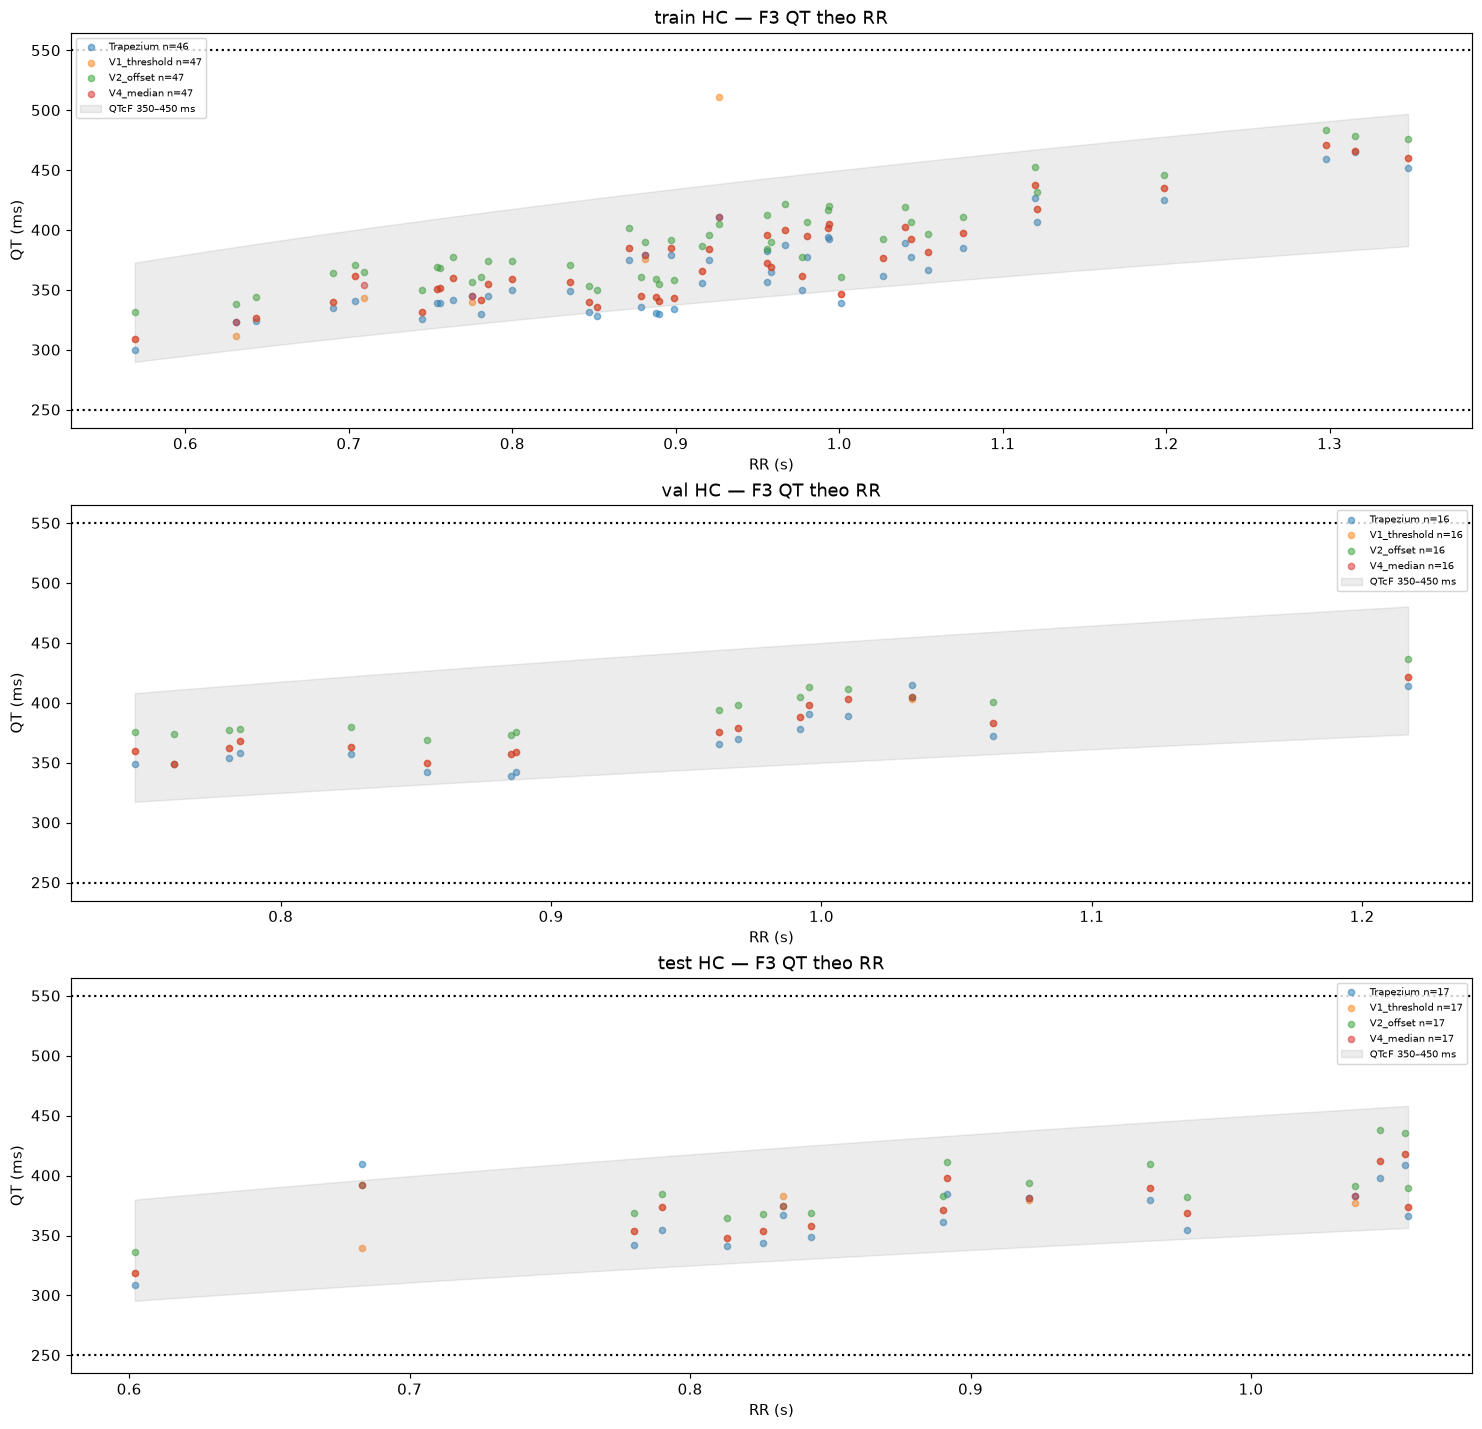

In [32]:
v4_t3=v4_qt_summary(v4_all);v4_table("T3_QT_QTc",v4_t3)
fig,axes=plt.subplots(len(splits),1,figsize=(14,4.5*len(splits)),squeeze=False,layout="constrained")
for split,ax in zip(splits,axes[:,0]):
    part=v4_all[(v4_all.split.eq(split))&(v4_all.label.eq("HC"))&
        (v4_all.loop_variant.eq("STT"))&v4_all.method.isin(["V2_offset","V1_threshold","Trapezium","V4_median"])]
    for m,g in part.groupby("method"):
        ok=np.isfinite(g.rr_s)&np.isfinite(g.qt_ms)
        ax.scatter(g.loc[ok,"rr_s"],g.loc[ok,"qt_ms"],s=18,alpha=.5,label=f"{m} n={ok.sum()}")
    finite_rr=pd.to_numeric(part.rr_s,errors="coerce").dropna()
    rr=(np.linspace(max(.3,finite_rr.min()),min(2.,finite_rr.max()),100)
        if len(finite_rr) and finite_rr.max()>finite_rr.min() else np.linspace(.5,1.5,100))
    ax.fill_between(rr,350*rr**(1/3),450*rr**(1/3),color="gray",alpha=.15,label="QTcF 350–450 ms")
    ax.axhline(250,color="black",ls=":");ax.axhline(550,color="black",ls=":")
    ax.set(xlabel="RR (s)",ylabel="QT (ms)",title=split+" HC — F3 QT theo RR");ax.legend(fontsize=7)
v4_show(fig,"F3_QT_RR_HC")


## 15. E5/T6 — ablation method và loop

So sánh từng estimator, median đủ bốn/≥2, bỏ từng voter và median ba voter đã chọn ở train/validation; ST-T và pure-T. T6 giữ coverage/QT/QTc; E3 jitter chỉ có train/valid vì đúng protocol. Test chỉ báo các variant đã định nghĩa/khóa trước và không dùng để chọn variant.

Pure-T phụ thuộc onset agreement, nên missing pure-T không làm ST-T missing. Cải thiện phải đọc cùng T1: coverage tăng bằng cách bỏ cờ/ca không phải tự động là tốt.

T6_ablation: 96 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,loop_variant,n_attempted_coverage,n_patients_coverage,has_median_n,has_median_pct,has_qrs_n,has_qrs_pct,has_t_peak_n,has_t_peak_pct,valid_end_n,valid_end_pct,loop_valid_n,loop_valid_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,status_accepted_n,status_needs_review_n,status_unresolved_n,missing_end_pct,n_attempted_physiology,n_patients_physiology,n_measured,n_patients_measured,qt_outside_250_550_pct,qt_rr_slope_ms_per_s,qt_rr_intercept_ms,qtc_p5_ms,qtc_p25_ms,qtc_p50_ms,qtc_p75_ms,qtc_p95_ms,E3_missing_pct,E3_jitter_p90_ms,E3_n_trials
0,train,MI,V2_offset,STT,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,190,87.962963,0,0.000000,190,87.962963,0,190,26,12.037037,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326,12.407407,0.0,12888.0
1,train,MI,V2_offset,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,190,87.962963,26,12.037037,0,0.000000,26,12.037037,0,190,26,12.037037,216,89,190,84,0.000000,165.191157,247.223821,355.532937,391.756971,408.955708,428.141787,464.084326,12.407407,0.0,12888.0
2,train,MI,V1_threshold,STT,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,208,96.296296,0,0.000000,208,96.296296,0,208,8,3.703704,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395,3.842593,4.0,12888.0
3,train,MI,V1_threshold,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,208,96.296296,27,12.500000,0,0.000000,27,12.500000,0,208,8,3.703704,216,89,208,87,1.442308,167.377194,235.474590,343.636778,372.666414,392.636481,413.423989,482.887395,3.842593,4.0,12888.0
4,train,MI,Trapezium,STT,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,172,79.629630,0,0.000000,172,79.629630,0,172,44,20.370370,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871,21.875000,9.0,12888.0
5,train,MI,Trapezium,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,172,79.629630,24,11.111111,0,0.000000,24,11.111111,0,172,44,20.370370,216,89,172,81,1.744186,206.933934,214.646839,335.330446,375.563572,398.178352,440.633125,502.987871,21.875000,9.0,12888.0
6,train,MI,Integral,STT,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,166,76.851852,0,0.000000,166,76.851852,0,166,50,23.148148,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033,25.277778,9.0,12888.0
7,train,MI,Integral,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,166,76.851852,23,10.648148,0,0.000000,23,10.648148,0,166,50,23.148148,216,89,166,79,10.240964,244.632663,202.495469,332.771934,365.333915,393.996356,491.646256,586.488033,25.277778,9.0,12888.0
8,train,MI,V4_median,STT,216,89,213,98.611111,213,98.611111,212,98.148148,205,94.907407,205,94.907407,38,17.592593,205,94.907407,38,167,11,5.092593,216,89,205,85,0.000000,171.847095,237.457573,350.365549,383.157460,402.052957,423.080615,465.609994,5.046296,6.0,12888.0
9,train,MI,V4_median,pure_T,216,89,213,98.611111,213,98.611111,212,98.148148,205,94.907407,27,12.500000,7,3.240741,27,12.500000,7,198,11,5.092593,216,89,205,85,0.000000,171.847095,237.457573,350.365549,383.157460,402.052957,423.080615,465.609994,5.046296,6.0,12888.0


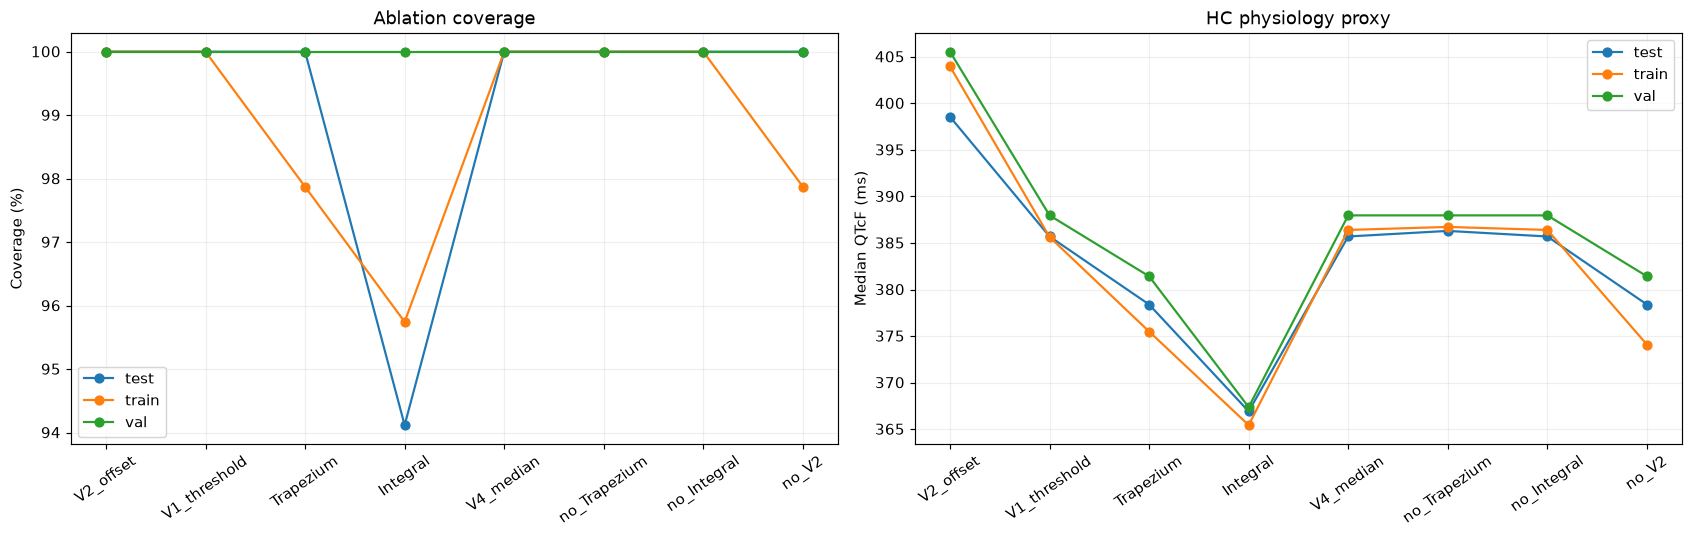

In [33]:
v4_t6=v4_t1.merge(v4_t3,on=["split","label","method","loop_variant"],
    suffixes=("_coverage","_physiology"),validate="one_to_one")
if not v4_t4.empty:
    e3=v4_t4.groupby(["split","label","method"]).agg(
        E3_missing_pct=("missing_pct","median"),E3_jitter_p90_ms=("jitter_p90_abs_ms","median"),
        E3_n_trials=("n_trials","sum")).reset_index()
    v4_t6=v4_t6.merge(e3,on=["split","label","method"],how="left",validate="many_to_one")
v4_table("T6_ablation",v4_t6)
fig,axes=plt.subplots(1,2,figsize=(16,5),layout="constrained")
for split,g in v4_t6[v4_t6.label.eq("HC")].groupby("split"):
    stt=g[g.loop_variant.eq("STT")].set_index("method").reindex(V4_METHODS)
    axes[0].plot(V4_METHODS,stt.valid_end_pct,"o-",label=split)
    axes[1].plot(V4_METHODS,stt.qtc_p50_ms,"o-",label=split)
axes[0].set(ylabel="Coverage (%)",title="Ablation coverage");axes[1].set(ylabel="Median QTcF (ms)",title="HC physiology proxy")
for ax in axes:ax.tick_params(axis="x",rotation=35);ax.legend();ax.grid(alpha=.2)
v4_show(fig,"E5_ablation")


## 16. E6/T7 — downstream MI/HC, không dùng để chọn T-end

Mọi model dùng đúng split/patient. Pipeline: median imputer → StandardScaler → LogisticRegression class_weight=balanced, random_state cố định, threshold 0.5. Tất cả fit chỉ trên train; validation/test chỉ transform/predict. Train apparent là hiệu năng trên chính train, không phải generalization.

QRS-only là baseline. Với T:

- valid: dùng feature candidate khi loop hợp lệ, dù needs_review;
- accepted: mask toàn bộ feature T/ST-T ở ca chưa accepted, nhưng giữ QRS;
- mọi model giữ cùng record; không lọc cohort theo method;
- báo mỗi estimator/fusion × STT/pure-T × policy, không chọn model theo AUC;
- CI 95% bootstrap theo patient, lấy mọi record của patient; patient metric dùng mean probability, threshold 0.5.

E6 trả lời feature có ích cho MI/HC hay không, không chứng minh T-end đúng. AP phụ thuộc prevalence. Calibration/Brier phản ánh model hiện tại, không chỉnh trên test.

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,accuracy_score,balanced_accuracy_score,
    precision_score,recall_score,f1_score,matthews_corrcoef,roc_auc_score,
    average_precision_score,brier_score_loss,log_loss,roc_curve,precision_recall_curve)

def v4_metric_row(y,prob):
    y=np.asarray(y,int);prob=np.asarray(prob,float);pred=(prob>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(n=len(y),prevalence=float(y.mean()) if len(y) else np.nan,
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
        accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),
        sensitivity=tp/(tp+fn) if tp+fn else np.nan,specificity=tn/(tn+fp) if tn+fp else np.nan,
        precision=precision_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),
        mcc=matthews_corrcoef(y,pred),
        roc_auc=roc_auc_score(y,prob) if len(np.unique(y))==2 else np.nan,
        average_precision=average_precision_score(y,prob) if len(np.unique(y))==2 else np.nan,
        brier=brier_score_loss(y,prob),log_loss=log_loss(y,prob,labels=[0,1]))

def v4_patient_predictions(frame):
    if frame.groupby("patient_id").y.nunique().max()>1:raise ValueError("Patient label mismatch")
    return frame.groupby("patient_id",as_index=False).agg(y=("y","first"),probability_mi=("probability_mi","mean"))

def v4_metric_ci(frame,metric,unit,repeats=V4_CI_REPEATS):
    patients=np.sort(frame.patient_id.unique())
    if len(patients)<5:return (np.nan,np.nan,0)
    blocks=[frame[frame.patient_id.eq(p)] for p in patients];rng=np.random.default_rng(20261023)
    values=[]
    for _ in range(repeats):
        sample=pd.concat([blocks[j] for j in rng.integers(0,len(blocks),len(blocks))],ignore_index=True)
        measured=v4_patient_predictions(sample) if unit=="patient_mean_probability" else sample
        row=v4_metric_row(measured.y,measured.probability_mi)
        if np.isfinite(row[metric]):values.append(row[metric])
    return (*np.quantile(values,[.025,.975]),len(values)) if len(values)>=20 else (np.nan,np.nan,len(values))

def v4_run_ml(frame):
    expected=set(V4_SPLIT.record_id);predictions=[];models=[];skipped=[]
    definitions=[("QRS_only","V4_median","STT","qrs",tuple(f for f in FEATURE_NAMES if f.startswith("QRS_")))]
    definitions += [(f"{m}_{loop}_{policy}",m,loop,policy,V4_ALL_FEATURES)
                    for m,loop,policy in product(V4_METHODS,("STT","pure_T"),("valid","accepted"))]
    for model_name,method,loop,policy,features in definitions:
        data=frame[(frame.method.eq(method))&(frame.loop_variant.eq(loop))].copy()
        if set(data.record_id)!=expected:
            skipped.append(dict(model=model_name,reason="record set does not equal full manifest"));continue
        if policy=="accepted":
            data.loc[~data.accepted,list(V4_T_FEATURES)]=np.nan
        elif policy=="valid":
            data.loc[~data.loop_valid,list(V4_T_FEATURES)]=np.nan
        elif policy!="qrs":raise ValueError("Feature policy không hợp lệ")
        train=data[data.split.eq("train")].copy()
        evaluation=data[data.split.isin(["train","val","test"])].copy()
        if not set(train.patient_id).isdisjoint(set(data[data.split.ne("train")].patient_id)):
            raise ValueError("Patient leakage vào model")
        X=train[list(features)]
        if train.label.nunique()!=2 or X.isna().all().any():
            skipped.append(dict(model=model_name,reason="train thiếu hai lớp hoặc có feature toàn NaN"));continue
        estimator=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),
            LogisticRegression(max_iter=3000,class_weight="balanced",random_state=20261023))
        estimator.fit(X,train.label.eq("MI").astype(int))
        models.append(dict(model=model_name,method=method,loop_variant=loop,policy=policy,
            features=";".join(features),n_train=len(train),n_train_patients=train.patient_id.nunique()))
        for split,g in evaluation.groupby("split",sort=False):
            prob=estimator.predict_proba(g[list(features)])[:,list(estimator.classes_).index(1)]
            for row,p in zip(g.itertuples(index=False),prob):
                predictions.append(dict(model=model_name,method=method,loop_variant=loop,policy=policy,
                    split=split,record_id=row.record_id,patient_id=row.patient_id,label=row.label,
                    y=int(row.label=="MI"),probability_mi=float(p)))
    return pd.DataFrame(predictions),pd.DataFrame(models),pd.DataFrame(skipped)

def v4_ml_summary(predictions):
    rows=[]
    for (model,method,loop,policy,split),g in predictions.groupby(
            ["model","method","loop_variant","policy","split"],sort=False):
        for unit,part in (("record",g),("patient_mean_probability",v4_patient_predictions(g))):
            metric=v4_metric_row(part.y,part.probability_mi)
            row=dict(model=model,method=method,loop_variant=loop,policy=policy,split=split,unit=unit,
                     n_patients=g.patient_id.nunique(),**metric)
            for name in ("balanced_accuracy","mcc","roc_auc","average_precision","brier"):
                low,high,n_boot=v4_metric_ci(g,name,unit)
                row[name+"_ci_low"]=low;row[name+"_ci_high"]=high;row[name+"_ci_bootstraps"]=n_boot
            rows.append(row)
    return pd.DataFrame(rows)

if V4_RUN_ML:
    if not V4_RUN_TEST:raise ValueError("E6 đầy đủ cần locked test; bật V4_RUN_TEST.")
    v4_predictions,v4_models,v4_ml_skipped=v4_run_ml(v4_all)
    v4_t7=v4_ml_summary(v4_predictions)
else:
    v4_predictions=v4_models=v4_ml_skipped=v4_t7=pd.DataFrame()
v4_table("E6_models",v4_models)
v4_table("E6_skipped",v4_ml_skipped)
v4_table("E6_predictions",v4_predictions)
v4_table("T7_downstream_metrics",v4_t7)


E6_models: 25 dòng; xem 24 dòng đầu; CSV giữ đủ.


,model,method,loop_variant,policy,features,n_train,n_train_patients
0,QRS_only,V4_median,STT,qrs,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
1,V2_offset_STT_valid,V2_offset,STT,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
2,V2_offset_pure_T_valid,V2_offset,pure_T,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
3,V1_threshold_STT_valid,V1_threshold,STT,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
4,V1_threshold_pure_T_valid,V1_threshold,pure_T,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
5,Trapezium_STT_valid,Trapezium,STT,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
6,Trapezium_pure_T_valid,Trapezium,pure_T,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
7,Integral_STT_valid,Integral,STT,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
8,Integral_pure_T_valid,Integral,pure_T,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120
9,V4_median_STT_valid,V4_median,STT,valid,QRS_Arc;QRS_Area;QRS_MaxVec;QRS_MaxCentroidDis...,263,120


E6_skipped: 8 dòng; xem 8 dòng đầu; CSV giữ đủ.


,model,reason
0,V2_offset_STT_accepted,train thiếu hai lớp hoặc có feature toàn NaN
1,V2_offset_pure_T_accepted,train thiếu hai lớp hoặc có feature toàn NaN
2,V1_threshold_STT_accepted,train thiếu hai lớp hoặc có feature toàn NaN
3,V1_threshold_pure_T_accepted,train thiếu hai lớp hoặc có feature toàn NaN
4,Trapezium_STT_accepted,train thiếu hai lớp hoặc có feature toàn NaN
5,Trapezium_pure_T_accepted,train thiếu hai lớp hoặc có feature toàn NaN
6,Integral_STT_accepted,train thiếu hai lớp hoặc có feature toàn NaN
7,Integral_pure_T_accepted,train thiếu hai lớp hoặc có feature toàn NaN


E6_predictions: 11,200 dòng; xem 24 dòng đầu; CSV giữ đủ.


,model,method,loop_variant,policy,split,record_id,patient_id,label,y,probability_mi
0,QRS_only,V4_median,STT,qrs,train,patient001/s0010_re,patient001,MI,1,0.968265
1,QRS_only,V4_median,STT,qrs,train,patient001/s0014lre,patient001,MI,1,0.917482
2,QRS_only,V4_median,STT,qrs,train,patient001/s0016lre,patient001,MI,1,0.939380
3,QRS_only,V4_median,STT,qrs,train,patient005/s0021are,patient005,MI,1,0.636559
4,QRS_only,V4_median,STT,qrs,train,patient005/s0021bre,patient005,MI,1,0.662949
5,QRS_only,V4_median,STT,qrs,train,patient005/s0025lre,patient005,MI,1,0.681542
6,QRS_only,V4_median,STT,qrs,train,patient005/s0031lre,patient005,MI,1,0.802686
7,QRS_only,V4_median,STT,qrs,train,patient005/s0101lre,patient005,MI,1,0.822840
8,QRS_only,V4_median,STT,qrs,train,patient006/s0022lre,patient006,MI,1,0.874178
9,QRS_only,V4_median,STT,qrs,train,patient006/s0027lre,patient006,MI,1,0.877479


T7_downstream_metrics: 150 dòng; xem 24 dòng đầu; CSV giữ đủ.


,model,method,loop_variant,policy,split,unit,n_patients,n,prevalence,tn,fp,fn,tp,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1,mcc,roc_auc,average_precision,brier,log_loss,balanced_accuracy_ci_low,balanced_accuracy_ci_high,balanced_accuracy_ci_bootstraps,mcc_ci_low,mcc_ci_high,mcc_ci_bootstraps,roc_auc_ci_low,roc_auc_ci_high,roc_auc_ci_bootstraps,average_precision_ci_low,average_precision_ci_high,average_precision_ci_bootstraps,brier_ci_low,brier_ci_high,brier_ci_bootstraps
0,QRS_only,V4_median,STT,qrs,train,record,120,263,0.821293,34,13,44,172,0.783270,0.759850,0.796296,0.723404,0.929730,0.857855,0.435909,0.890760,0.976016,0.138824,0.469227,0.638974,0.895208,500,0.251519,0.649849,500,0.819319,0.958822,500,0.951825,0.993417,500,0.102720,0.178750,500
1,QRS_only,V4_median,STT,qrs,train,patient_mean_probability,120,120,0.741667,29,2,15,74,0.858333,0.883472,0.831461,0.935484,0.973684,0.896970,0.696637,0.922798,0.976030,0.125059,0.463193,0.841654,0.928818,500,0.600575,0.802228,500,0.886950,0.960303,500,0.963215,0.988624,500,0.095050,0.152301,500
2,QRS_only,V4_median,STT,qrs,val,record,30,70,0.771429,12,4,10,44,0.800000,0.782407,0.814815,0.750000,0.916667,0.862745,0.510894,0.884259,0.967033,0.151140,0.601700,0.609688,0.940793,500,0.194411,0.808321,500,0.765749,0.982226,500,0.907271,0.997417,500,0.080027,0.229080,500
3,QRS_only,V4_median,STT,qrs,val,patient_mean_probability,30,30,0.733333,6,2,5,17,0.766667,0.761364,0.772727,0.750000,0.894737,0.829268,0.479687,0.875000,0.960336,0.168668,0.826144,0.623125,0.928571,500,0.216600,0.729477,500,0.777083,0.983880,500,0.915152,0.995833,500,0.088021,0.236103,500
4,QRS_only,V4_median,STT,qrs,test,record,50,115,0.852174,16,1,26,72,0.765217,0.837935,0.734694,0.941176,0.986301,0.842105,0.498213,0.900360,0.982663,0.168215,0.529961,0.732475,0.910256,500,0.293234,0.671102,500,0.820732,0.961574,500,0.961071,0.995614,500,0.110638,0.241465,500
5,QRS_only,V4_median,STT,qrs,test,patient_mean_probability,50,50,0.740000,12,1,10,27,0.780000,0.826403,0.729730,0.923077,0.964286,0.830769,0.576855,0.914761,0.970426,0.146292,0.444701,0.750000,0.903339,500,0.411842,0.730732,500,0.845105,0.977372,500,0.943812,0.994116,500,0.107429,0.188684,500
6,V2_offset_STT_valid,V2_offset,STT,valid,train,record,120,263,0.821293,45,2,17,199,0.927757,0.939372,0.921296,0.957447,0.990050,0.954436,0.793129,0.978920,0.995571,0.058824,0.206123,0.905001,0.973425,500,0.671580,0.893251,500,0.959189,0.992987,500,0.990580,0.998659,500,0.037368,0.084341,500
7,V2_offset_STT_valid,V2_offset,STT,valid,train,patient_mean_probability,120,120,0.741667,30,1,4,85,0.958333,0.961399,0.955056,0.967742,0.988372,0.971429,0.896384,0.991301,0.997111,0.047618,0.164853,0.937739,0.991379,500,0.834263,0.967380,500,0.983185,0.998997,500,0.994139,0.999657,500,0.030953,0.060523,500
8,V2_offset_STT_valid,V2_offset,STT,valid,val,record,30,70,0.771429,14,2,12,42,0.800000,0.826389,0.777778,0.875000,0.954545,0.857143,0.567295,0.909722,0.975076,0.143859,0.484428,0.682336,0.946199,500,0.284236,0.827590,500,0.807389,0.986575,500,0.926228,0.998365,500,0.056105,0.246817,500
9,V2_offset_STT_valid,V2_offset,STT,valid,val,patient_mean_probability,30,30,0.733333,8,0,5,17,0.833333,0.886364,0.772727,1.000000,1.000000,0.871795,0.689583,0.926136,0.974881,0.142976,0.462005,0.821429,0.958333,500,0.532718,0.875609,500,0.847222,1.000000,500,0.943954,1.000000,500,0.067831,0.212054,500


### 16A. ROC, precision–recall và calibration

Hình tập trung QRS-only và V4_median STT valid/accepted để đọc được; CSV giữ mọi ablation. Mỗi đường ghi split, không trộn validation và test. Train apparent không vẽ để tránh tạo cảm giác generalization.

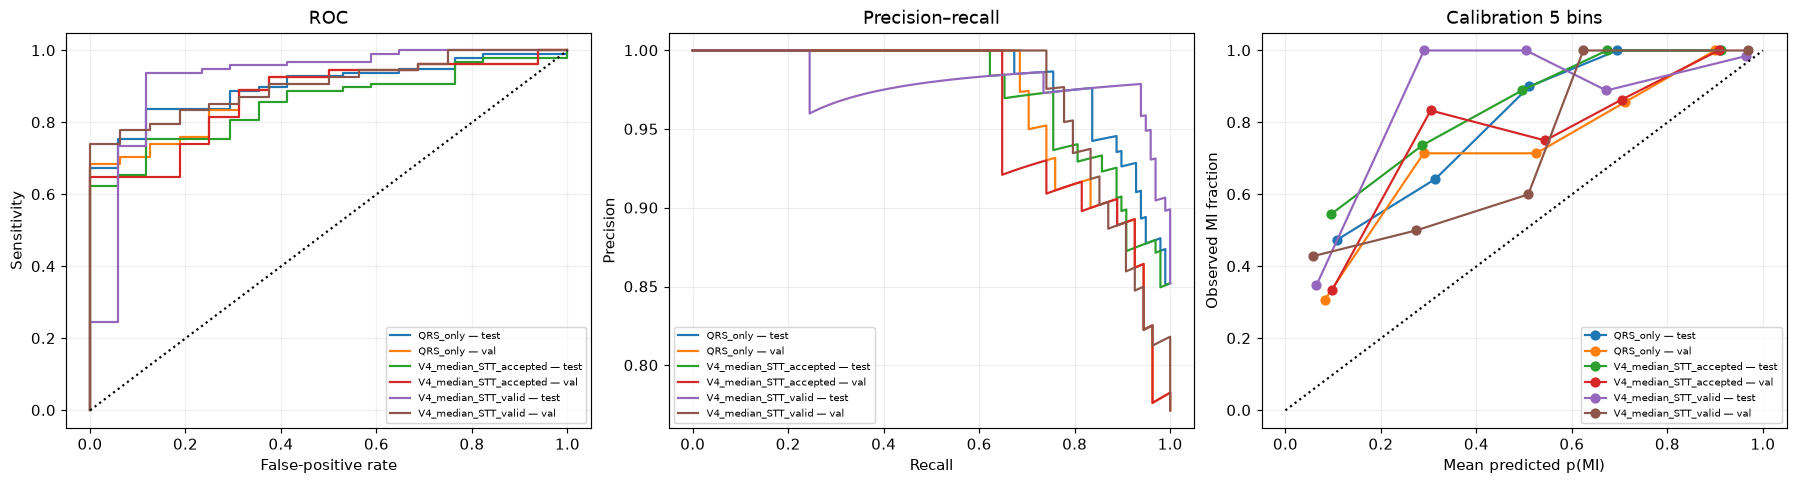

In [35]:
focus=["QRS_only","V4_median_STT_valid","V4_median_STT_accepted"]
fig,axes=plt.subplots(1,3,figsize=(17,4.5),layout="constrained")
for (model,split),g in v4_predictions[v4_predictions.model.isin(focus)&
        v4_predictions.split.isin(["val","test"])].groupby(["model","split"]):
    if g.y.nunique()<2:continue
    label=model+" — "+split
    fpr,tpr,_=roc_curve(g.y,g.probability_mi);precision,recall,_=precision_recall_curve(g.y,g.probability_mi)
    axes[0].plot(fpr,tpr,label=label);axes[1].plot(recall,precision,label=label)
    bins=pd.cut(g.probability_mi,np.linspace(0,1,6),include_lowest=True)
    cal=g.groupby(bins,observed=True).agg(p=("probability_mi","mean"),observed=("y","mean"),n=("y","size"))
    axes[2].plot(cal.p,cal.observed,"o-",label=label)
axes[0].plot([0,1],[0,1],"k:");axes[2].plot([0,1],[0,1],"k:")
axes[0].set(xlabel="False-positive rate",ylabel="Sensitivity",title="ROC")
axes[1].set(xlabel="Recall",ylabel="Precision",title="Precision–recall")
axes[2].set(xlabel="Mean predicted p(MI)",ylabel="Observed MI fraction",title="Calibration 5 bins")
for ax in axes:
    ax.grid(alpha=.2)
    if ax.has_data():ax.legend(fontsize=7)
v4_show(fig,"E6_ROC_PR_calibration")


## 17. E1 synthetic holdout sau lock/test

Synthetic holdout dùng subject/seed khác validation, cấu hình đã khóa. Nó đánh giá estimator trong generator, không dùng để sửa báo cáo test hiện tại. Muốn sửa thuật toán sau khi xem holdout, tạo run/protocol mới.

In [36]:
v4_synth_holdout=v4_e1("synthetic_holdout") if V4_RUN_SYNTHETIC else pd.DataFrame()
v4_table("E1_synthetic_holdout_records",v4_synth_holdout)
v4_t2=pd.concat([v4_e1_summary(v4_synth_validation),v4_e1_summary(v4_synth_holdout)],ignore_index=True)
v4_table("T2_synthetic_accuracy",v4_t2)


E1 synthetic_holdout subject 1/12
E1 synthetic_holdout subject 2/12
E1 synthetic_holdout subject 3/12
E1 synthetic_holdout subject 4/12
E1 synthetic_holdout subject 5/12
E1 synthetic_holdout subject 6/12
E1 synthetic_holdout subject 7/12
E1 synthetic_holdout subject 8/12
E1 synthetic_holdout subject 9/12
E1 synthetic_holdout subject 10/12
E1 synthetic_holdout subject 11/12
E1 synthetic_holdout subject 12/12
E1_synthetic_holdout_records: 15,552 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,patient_id,subject,fs_hz,shape,amplitude_mV,noise_fraction,drift_mV,method,valid,error_ms,truth_end_ms,error
0,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,V2_offset,False,NaN,424.0,
1,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,V1_threshold,True,-20.0,424.0,
2,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,Trapezium,True,-16.0,424.0,
3,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,Integral,True,-44.0,424.0,
4,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,V4_median,True,-16.0,424.0,
5,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,no_Trapezium,True,-32.0,424.0,
6,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,no_Integral,True,-16.0,424.0,
7,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.00,no_V2,True,-20.0,424.0,
8,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.02,V2_offset,False,NaN,424.0,
9,synthetic_holdout,synthetic,synthetic_holdout_000,0,250,symmetric,0.08,0.00,0.02,V1_threshold,True,-40.0,424.0,


T2_synthetic_accuracy: 2,592 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,method,fs_hz,shape,amplitude_mV,noise_fraction,drift_mV,n_attempted,n_patients,n_measured,missing_pct,bias_ms,mae_ms,p90_abs_error_ms
0,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.00,0.00,12,12,12,0.000000,-65.333333,65.333333,72.0
1,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.00,0.02,12,12,12,0.000000,89.333333,128.000000,174.8
2,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.01,0.00,12,12,12,0.000000,-55.333333,55.333333,71.6
3,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.01,0.02,12,12,12,0.000000,73.666667,108.333333,156.0
4,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.03,0.00,12,12,12,0.000000,-17.000000,55.666667,75.2
5,synthetic_validation,synthetic,Integral,250,asymmetric,0.08,0.03,0.02,12,12,9,25.000000,95.555556,123.111111,169.6
6,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.00,0.00,12,12,12,0.000000,-65.333333,65.333333,72.0
7,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.00,0.02,12,12,12,0.000000,64.000000,99.333333,143.6
8,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.01,0.00,12,12,12,0.000000,-63.000000,63.000000,75.6
9,synthetic_validation,synthetic,Integral,250,asymmetric,0.25,0.01,0.02,12,12,12,0.000000,30.000000,84.666667,132.8


## 18. F4 — Bland–Altman giữa ba estimator

Chỉ ghép record mà cả hai estimator có end hợp lệ. Delta=B−A, limits=mean±1.96 SD; đây là agreement, không phải error/accuracy trên người thật. F4 tách split; bảng giữ n pairs/patients và phần trăm trong 10/20/25/40/50 ms.

F4_Bland_Altman_summary: 18 dòng; xem 18 dòng đầu; CSV giữ đủ.


,split,label,left,right,n_attempted,n_patients,n_paired,n_patients_paired,bias_ms,sd_ms,median_abs_ms,loa_low_ms,loa_high_ms,within_10ms_pct,within_20ms_pct,within_25ms_pct,within_40ms_pct,within_50ms_pct
0,test,all,V2_offset,V1_threshold,115,50,113,49,-13.159292,33.530255,20.0,-78.878591,52.560007,11.504425,53.097345,58.407080,76.106195,88.495575
1,test,all,V2_offset,Trapezium,115,50,103,48,-0.067961,42.928409,26.0,-84.207642,84.071720,15.533981,33.009709,48.543689,79.611650,88.349515
2,test,all,V2_offset,Integral,115,50,98,46,21.816327,76.315183,42.0,-127.761432,171.394085,4.081633,12.244898,13.265306,46.938776,60.204082
3,test,all,V1_threshold,Trapezium,115,50,104,49,11.403846,55.680873,19.0,-97.730665,120.538357,25.000000,52.884615,61.538462,67.307692,73.076923
4,test,all,V1_threshold,Integral,115,50,99,47,31.858586,86.289381,31.0,-137.268602,200.985773,3.030303,17.171717,36.363636,60.606061,62.626263
5,test,all,Trapezium,Integral,115,50,97,46,19.371134,44.764271,12.0,-68.366838,107.109106,19.587629,69.072165,70.103093,72.164948,75.257732
6,train,all,V2_offset,V1_threshold,263,120,237,115,-12.713080,29.336193,18.0,-70.212019,44.785859,14.767932,57.383966,70.886076,86.497890,91.561181
7,train,all,V2_offset,Trapezium,263,120,201,109,-9.273632,37.300667,28.0,-82.382939,63.835675,12.437811,25.373134,43.781095,83.084577,88.059701
8,train,all,V2_offset,Integral,263,120,195,105,1.061538,70.876372,42.0,-137.856151,139.979228,2.051282,7.179487,9.743590,45.128205,69.230769
9,train,all,V1_threshold,Trapezium,263,120,216,110,4.731481,45.655353,16.5,-84.753011,94.215974,30.092593,56.018519,62.500000,75.925926,79.629630


F4_Bland_Altman_details: 2,219 dòng; xem 24 dòng đầu; CSV giữ đủ.


,split,label,left,right,record_id,patient_id,mean_ms,delta_ms
0,test,all,V2_offset,V1_threshold,patient002/s0015lre,patient002,333.0,-20.0
1,test,all,V2_offset,V1_threshold,patient004/s0020are,patient004,344.0,44.0
2,test,all,V2_offset,V1_threshold,patient004/s0020bre,patient004,353.0,60.0
3,test,all,V2_offset,V1_threshold,patient008/s0028lre,patient008,368.5,-15.0
4,test,all,V2_offset,V1_threshold,patient008/s0037lre,patient008,439.0,44.0
5,test,all,V2_offset,V1_threshold,patient008/s0068lre,patient008,433.5,91.0
6,test,all,V2_offset,V1_threshold,patient014/s0046lre,patient014,336.5,-23.0
7,test,all,V2_offset,V1_threshold,patient014/s0056lre,patient014,349.5,-41.0
8,test,all,V2_offset,V1_threshold,patient014/s0071lre,patient014,319.5,-43.0
9,test,all,V2_offset,V1_threshold,patient015/s0047lre,patient015,246.5,-45.0


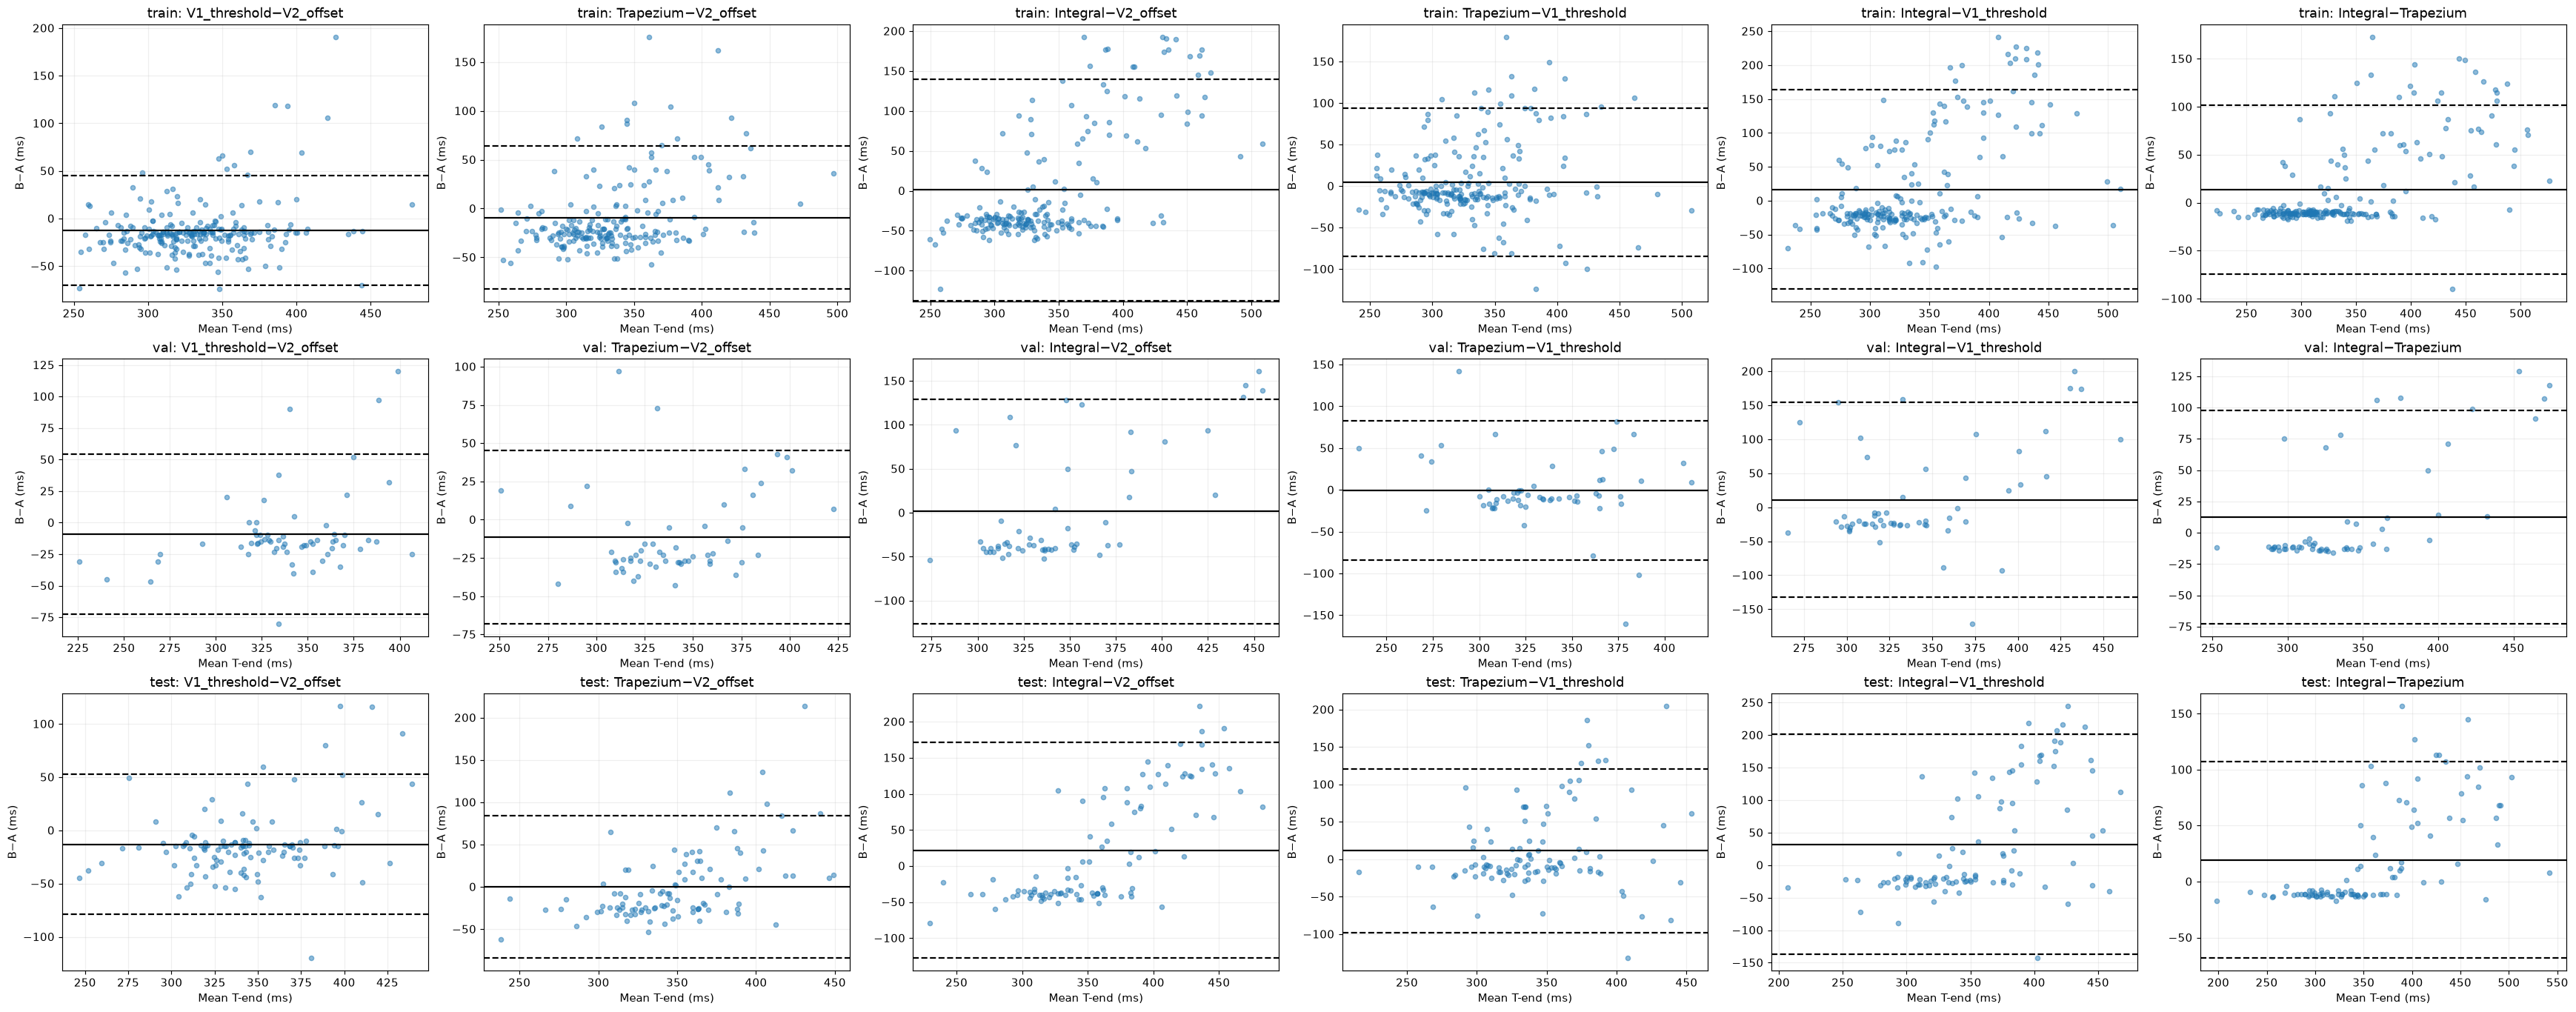

In [37]:
def v4_pairwise(frame):
    source=frame[(frame.loop_variant=="STT")&frame.method.isin(V4_BASE_METHODS)]
    summaries=[];details=[]
    for split,g in source.groupby("split"):
        for a,b in combinations(V4_BASE_METHODS,2):
            left=g[g.method.eq(a)][["record_id","patient_id","t_end_ms","valid_end"]]
            right=g[g.method.eq(b)][["record_id","patient_id","t_end_ms","valid_end"]]
            paired=left.merge(right,on=["record_id","patient_id"],suffixes=("_a","_b"),validate="one_to_one")
            good=paired.valid_end_a&paired.valid_end_b;measured=paired[good].copy()
            measured["mean_ms"]=(measured.t_end_ms_a+measured.t_end_ms_b)/2
            measured["delta_ms"]=measured.t_end_ms_b-measured.t_end_ms_a
            row=dict(split=split,label="all",left=a,right=b,n_attempted=len(paired),
                n_patients=paired.patient_id.nunique(),n_paired=len(measured),
                n_patients_paired=measured.patient_id.nunique(),bias_ms=measured.delta_ms.mean(),
                sd_ms=measured.delta_ms.std(ddof=1),median_abs_ms=measured.delta_ms.abs().median())
            row["loa_low_ms"]=row["bias_ms"]-1.96*row["sd_ms"];row["loa_high_ms"]=row["bias_ms"]+1.96*row["sd_ms"]
            for tol in (10,20,25,40,50):
                row[f"within_{tol}ms_pct"]=100*measured.delta_ms.abs().le(tol).mean() if len(measured) else np.nan
            summaries.append(row)
            details.extend(dict(split=split,label="all",left=a,right=b,record_id=x.record_id,
                patient_id=x.patient_id,mean_ms=x.mean_ms,delta_ms=x.delta_ms) for x in measured.itertuples())
    columns=["split","label","left","right","record_id","patient_id","mean_ms","delta_ms"]
    return pd.DataFrame(summaries),pd.DataFrame(details,columns=columns)
v4_f4_summary,v4_f4_details=v4_pairwise(v4_all)
v4_table("F4_Bland_Altman_summary",v4_f4_summary)
v4_table("F4_Bland_Altman_details",v4_f4_details)
pairs=list(combinations(V4_BASE_METHODS,2));ncols=max(1,len(pairs))
fig,axes=plt.subplots(len(splits),ncols,figsize=(5.5*ncols,4.3*len(splits)),squeeze=False,layout="constrained")
for split,axs in zip(splits,axes):
    for ax,(a,b) in zip(axs,pairs):
        g=v4_f4_details[(v4_f4_details.split.eq(split))&(v4_f4_details.left.eq(a))&(v4_f4_details.right.eq(b))]
        row=v4_f4_summary[(v4_f4_summary.split.eq(split))&(v4_f4_summary.left.eq(a))&(v4_f4_summary.right.eq(b))]
        ax.scatter(g.mean_ms,g.delta_ms,s=18,alpha=.5)
        if not row.empty:
            r=row.iloc[0]
            for value,style in ((r.bias_ms,"-"),(r.loa_low_ms,"--"),(r.loa_high_ms,"--")):
                if np.isfinite(value):ax.axhline(value,color="black",ls=style)
        if g.empty:ax.text(.5,.5,"Không có paired end",ha="center",transform=ax.transAxes)
        ax.set(xlabel="Mean T-end (ms)",ylabel="B−A (ms)",title=f"{split}: {b}−{a}");ax.grid(alpha=.2)
v4_show(fig,"F4_Bland_Altman")


## 19. F5 — ca phân vị uncertainty, chọn xác định trước khi nhìn hình

Trong từng split, lấy record V4_median STT có uncertainty gần nhất p10, p50, p90; tie theo record_id. Đây không phải chọn ca đẹp. Bảng lưu target quantile, giá trị thật, label/status. Hình overlay J, peak, từng T-end, median và ST-T 3D. Nếu split không đủ candidate, panel ghi rõ.

F5_quantile_cases: 9 dòng; xem 9 dòng đầu; CSV giữ đủ.


,split,label,quantile,target_uncertainty_ms,record_id,patient_id,uncertainty_ms,status,accepted
0,test,MI,low_p10,16.0,patient095/s0373lre,patient095,16.0,accepted,True
1,test,MI,median_p50,33.0,patient035/s0119lre,patient035,33.0,accepted,True
2,test,MI,high_p90,95.1,patient080/s0261lre,patient080,96.0,needs_review,False
3,train,MI,low_p10,15.1,patient005/s0021are,patient005,15.0,needs_review,False
4,train,MI,median_p50,31.0,patient018/s0059lre,patient018,31.0,needs_review,False
5,train,MI,high_p90,84.0,patient006/s0022lre,patient006,84.0,needs_review,False
6,val,MI,low_p10,18.6,patient160/s0222_re,patient160,18.0,needs_review,False
7,val,MI,median_p50,28.5,patient056/s0196lre,patient056,28.0,accepted,True
8,val,MI,high_p90,75.4,patient016/s0060lre,patient016,79.0,needs_review,False


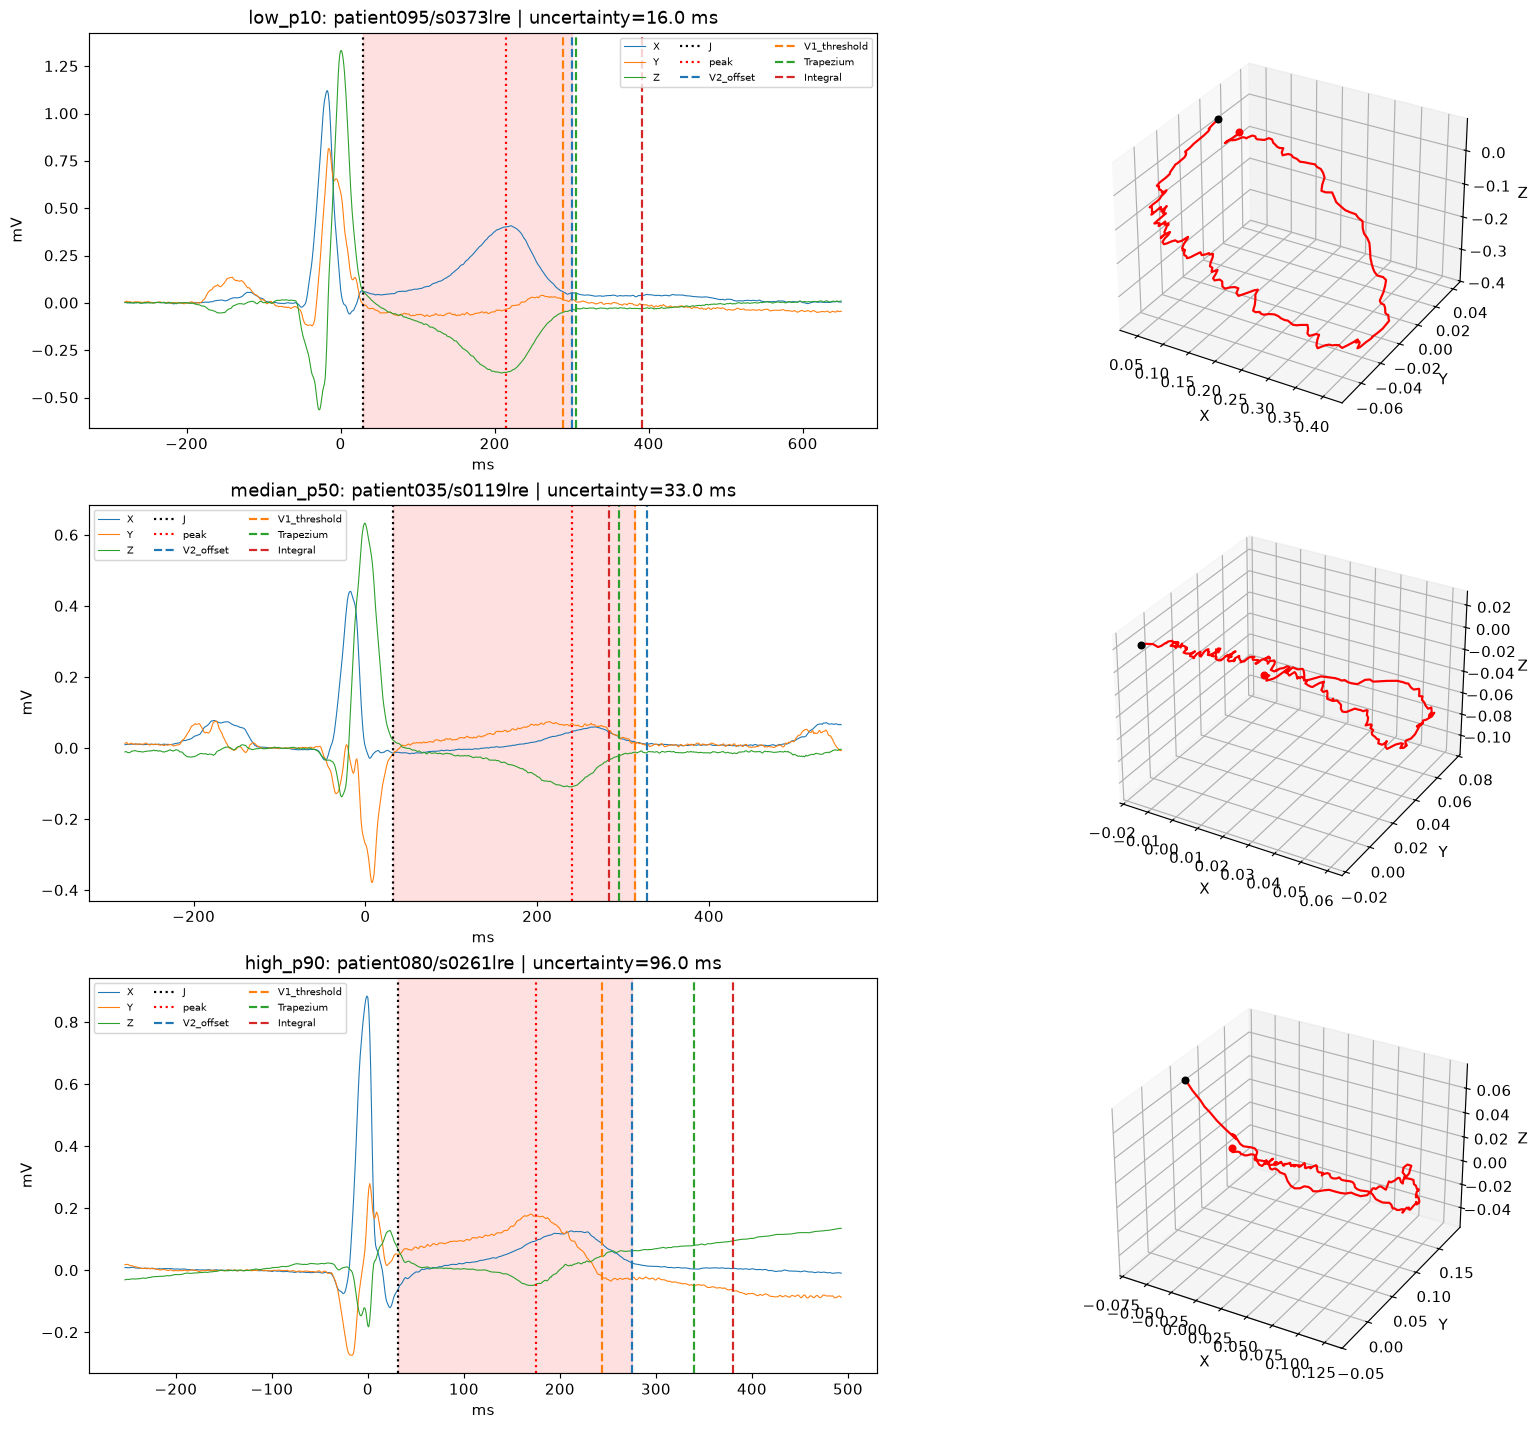

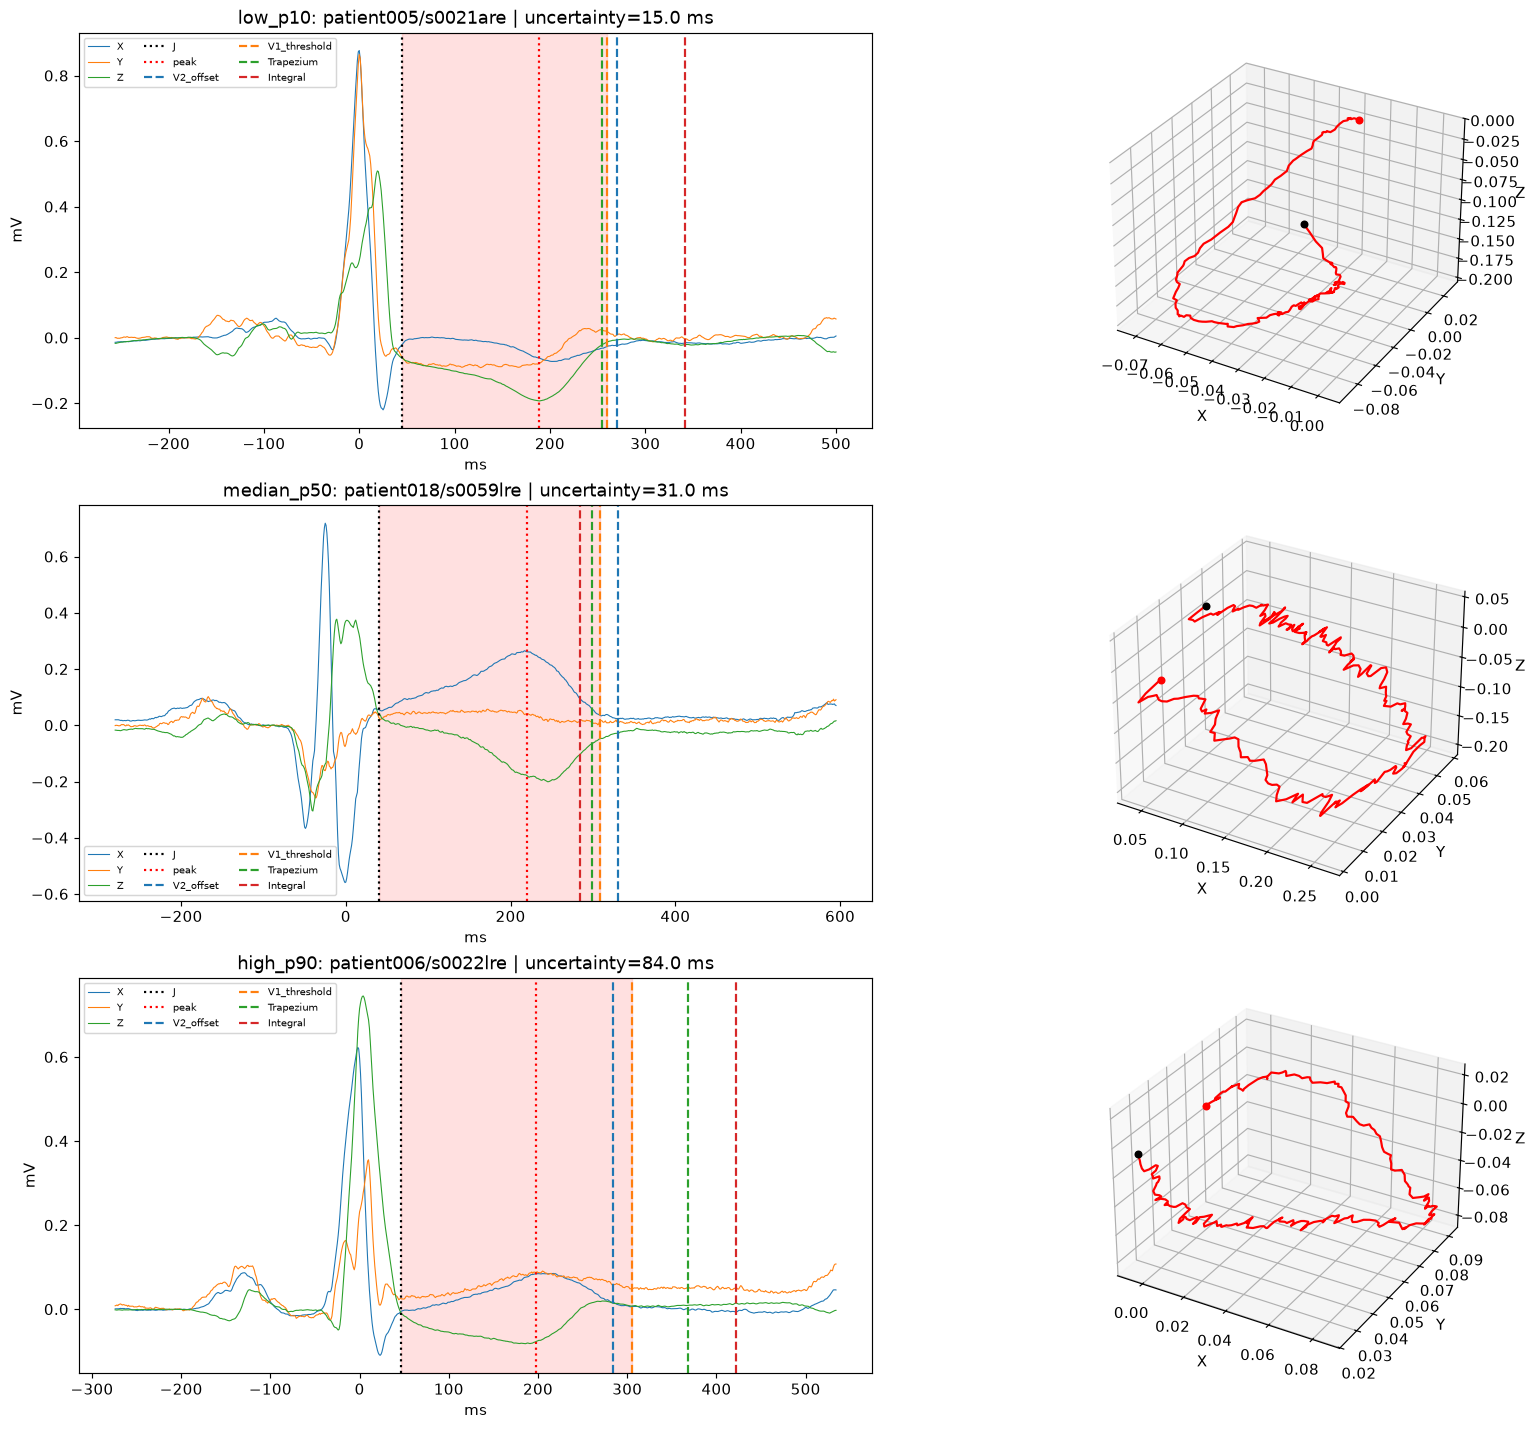

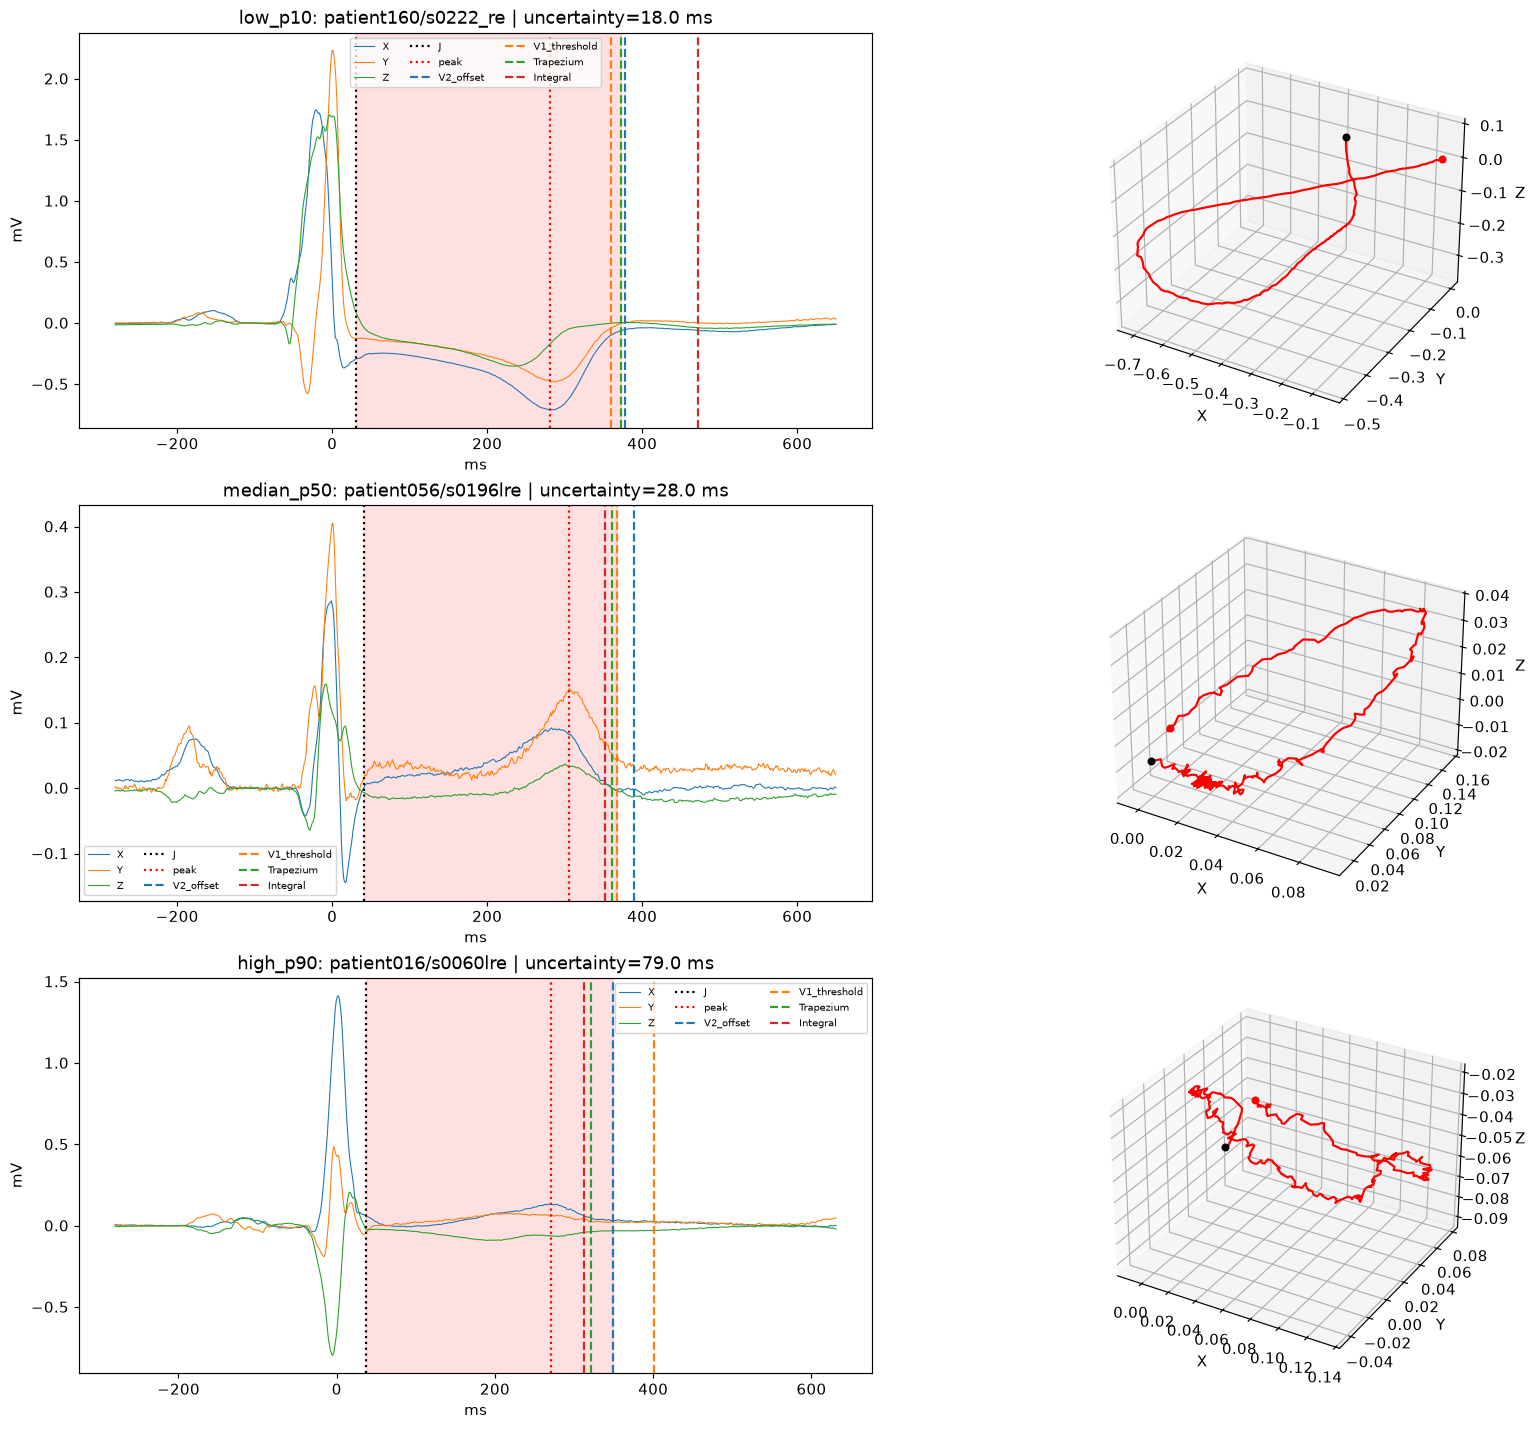

In [38]:
def v4_quantile_cases(frame):
    rows=[]
    for split,g in frame[(frame.method=="V4_median")&(frame.loop_variant=="STT")&
                          frame.uncertainty_ms.notna()].groupby("split"):
        g=g.sort_values("record_id")
        for name,qv in (("low_p10",.10),("median_p50",.50),("high_p90",.90)):
            target=g.uncertainty_ms.quantile(qv)
            chosen=g.assign(distance=(g.uncertainty_ms-target).abs()).sort_values(["distance","record_id"]).iloc[0]
            rows.append(dict(split=split,label=chosen.label,quantile=name,target_uncertainty_ms=target,
                record_id=chosen.record_id,patient_id=chosen.patient_id,uncertainty_ms=chosen.uncertainty_ms,
                status=chosen.status,accepted=chosen.accepted))
    return pd.DataFrame(rows)
v4_f5_cases=v4_quantile_cases(v4_all);v4_table("F5_quantile_cases",v4_f5_cases)
for split,g in v4_f5_cases.groupby("split",sort=False):
    fig=plt.figure(figsize=(16,4.5*len(g)),layout="constrained")
    for row_number,row in enumerate(g.itertuples(index=False)):
        ax=fig.add_subplot(len(g),2,2*row_number+1);ax3=fig.add_subplot(len(g),2,2*row_number+2,projection="3d")
        try:
            st=v4_cached_state(row.record_id);est=v4_estimate(st);q=est["q"];rep=st["rep"];t=rep["time_ms"]
            for j in range(3):ax.plot(t,rep["xyz"][:,j],lw=.75,label="XYZ"[j])
            for name,index,color in (("J",q.get("qrs_off"),"black"),("peak",q.get("t_peak"),"red")):
                if v4_index(index,len(t)):ax.axvline(t[index],color=color,ls=":",label=name)
            endpoints=v4_endpoints(st,est)
            for method in V4_BASE_METHODS:
                end=endpoints[method]["end"]
                if end is not None:ax.axvline(t[end],color=V4_PLOTS[method],ls="--",label=method)
            end=endpoints["V4_median"]["end"];start=q.get("qrs_off")
            if end is not None and start is not None:
                ax.axvspan(t[start],t[end],alpha=.12,color="red")
                loop=rep["xyz"][start:end+1];ax3.plot(*loop.T,color="red")
                ax3.scatter(*loop[0],color="black");ax3.scatter(*loop[-1],color="red")
            else:ax3.text2D(.2,.5,"ST-T unresolved",transform=ax3.transAxes)
            ax.set(title=f"{row.quantile}: {row.record_id} | uncertainty={row.uncertainty_ms:.1f} ms",
                   xlabel="ms",ylabel="mV");ax.legend(fontsize=7,ncol=3)
            ax3.set(xlabel="X",ylabel="Y",zlabel="Z")
        except Exception as exc:
            ax.text(.5,.5,type(exc).__name__+": "+str(exc),ha="center",transform=ax.transAxes)
            ax3.text2D(.2,.5,"Không tải được loop",transform=ax3.transAxes)
    v4_show(fig,"F5_"+split+"_quantile_cases")


## 20. E7 — review queue, data dictionary và xuất gói tái lập

Review queue ưu tiên unresolved, uncertainty cao và cờ lỗi; không biến prediction thành ground truth. Template annotation để trống, yêu cầu source/reviewer/time reference. Nếu sau này có nhãn độc lập cùng median/time origin, lúc đó mới tính MAE/RMSE trên PTB.

Mọi T1–T7 và F4/F5 được lưu dưới outputs/vcg_v4/<run>. config.json, locked_config.json và test_receipt.json tạo chuỗi provenance. Báo cáo ghi rõ phần nào chưa chạy khi option tắt.

In [39]:
priority={"unresolved":0,"needs_review":1,"accepted":2}
v4_review=v4_all[(v4_all.method=="V4_median")&(v4_all.loop_variant=="STT")].copy()
v4_review["_priority"]=v4_review.status.map(priority)
v4_review=v4_review.sort_values(["_priority","uncertainty_ms","record_id"],ascending=[True,False,True]).drop(columns="_priority")
v4_review=v4_review[["record_id","patient_id","split","label","status","accepted","valid_end",
    "j_ms","t_peak_ms","t_end_ms","uncertainty_ms","error_flags","info_flags","failure_reason"]]
v4_reference=V4_SPLIT[["record_id","patient_id","split","label_name"]].rename(columns={"label_name":"label"}).copy()
for c in ("qrs_on_ms","j_ms","t_peak_ms","t_end_ms"):v4_reference[c]=np.nan
for c in ("reviewer","reference_source","notes"):v4_reference[c]=""
v4_reference["time_reference"]="median_relative_to_QRS_anchor_ms"
v4_reference["independent_reference"]=False
v4_dictionary=pd.DataFrame([
    ("record_id","recording ID in fixed manifest"),("patient_id","patient cluster; never crosses split"),
    ("j_sample","qrs_off in median-local zero-based sample"),("t_end_sample","median-local zero-based sample"),
    ("t_end_ms","milliseconds relative to median QRS anchor"),("uncertainty_ms","max-min valid member ends; NaN for single method"),
    ("valid_end","logical J < T-peak < T-end within median"),("accepted","valid loop plus locked QT/uncertainty/error screening"),
    ("info_flags","warnings/adaptations not used alone to reject"),("error_flags","record/method issues controlling review status"),
    ("T_*","for loop_variant=STT, old T feature names refer to J-to-T-end segment"),
    ("qtc_fridericia_ms","QT milliseconds divided by RR_seconds^(1/3)")],
    columns=["column","definition"])
v4_table("E7_review_queue",v4_review)
v4_table("E7_reference_template_blank",v4_reference)
v4_table("E7_data_dictionary",v4_dictionary)

V4_TABLES.update(T1=v4_t1,T2=v4_t2,T3=v4_t3,T4=v4_t4,T5=v4_t5,T6=v4_t6,T7=v4_t7,
    F4_summary=v4_f4_summary,F4_details=v4_f4_details,F5_cases=v4_f5_cases,
    locked_record_results=v4_all,feature_sensitivity_flags=v4_feature_flags)
if V4_SAVE:
    (V4_OUT/"tables").mkdir(parents=True,exist_ok=True)
    for name,table in V4_TABLES.items():
        if isinstance(table,pd.DataFrame):table.to_csv(V4_OUT/"tables"/(name+".csv"),index=False)
    completion=dict(run_name=V4_RUN_NAME,protocol_id=V4_PROTOCOL_ID,lock_sha256=v4_lock["lock_sha256"],
        records_manifest=len(V4_SPLIT),patients_manifest=V4_SPLIT.patient_id.nunique(),
        locked_rows=len(v4_all),expected_locked_rows=len(V4_SPLIT)*len(V4_VARIANTS),
        test_executed=V4_RUN_TEST,test_receipt=v4_receipt_path.is_file(),
        tables=sorted(V4_TABLES),figures=sorted(p.name for p in (V4_OUT/"figures").glob("*.png")),
        claims=dict(real_T_accuracy="unavailable_without_independent_reference",
            synthetic_accuracy="generator-specific only",agreement="not accuracy",
            downstream="MI/HC task performance, not boundary correctness"))
    v4_json(V4_OUT/"completion.json",completion)
    report=[
        "# VCG V4 — J-point to T-end report","",
        "- Protocol: "+V4_PROTOCOL_ID,"- Lock: "+v4_lock["lock_sha256"],
        f"- Manifest: {len(V4_SPLIT)} records / {V4_SPLIT.patient_id.nunique()} patients",
        f"- Splits: {V4_SPLIT.groupby('split').size().to_dict()}",
        f"- Locked screen: {v4_screen}","",
        "## Reading order","T1 coverage/failures → T6 ablation → T2 synthetic → T3 physiology → "
        "T4 stability → T5 sensitivity → T7 downstream. F4 is agreement, not accuracy. "
        "F5 cases are selected by fixed uncertainty quantiles.","",
        "No independent PTB T-end reference is available. Do not report real-person MAE/RMSE from agreement."
    ]
    (V4_OUT/"report.md").write_text("\n".join(report)+"\n",encoding="utf-8")
print("Output:",V4_OUT)
print("Không có nhãn T độc lập: không tính accuracy/MAE/RMSE T-end trên PTB thật.")


E7_review_queue: 448 dòng; xem 24 dòng đầu; CSV giữ đủ.


,record_id,patient_id,split,label,status,accepted,valid_end,j_ms,t_peak_ms,t_end_ms,uncertainty_ms,error_flags,info_flags,failure_reason
1320,patient033/s0157lre,patient033,train,MI,unresolved,False,False,NaN,NaN,NaN,NaN,input_qc_fail;pipeline_error,,ValueError: Không đủ 3 beat sau kiểm tra biên/...
1336,patient034/s0109lre,patient034,train,MI,unresolved,False,False,40.0,NaN,NaN,NaN,t_end_unresolved_or_invalid_order;t_peak_not_f...,Các ngưỡng PSD/persistence/quiet là heuristic ...,
1512,patient038/s0162lre,patient038,train,MI,unresolved,False,False,NaN,NaN,NaN,NaN,input_qc_fail;pipeline_error,,ValueError: Không đủ 3 beat sau kiểm tra biên/...
2328,patient067/s0227lre,patient067,val,MI,unresolved,False,False,25.0,NaN,NaN,NaN,t_end_unresolved_or_invalid_order;t_peak_not_f...,Các ngưỡng PSD/persistence/quiet là heuristic ...,
2808,patient079/s0256lre,patient079,val,MI,unresolved,False,False,NaN,NaN,NaN,NaN,input_qc_fail;pipeline_error,,ValueError: Không đủ 3 beat sau kiểm tra biên/...
2824,patient079/s0257lre,patient079,val,MI,unresolved,False,False,NaN,NaN,NaN,NaN,input_qc_fail;pipeline_error,,ValueError: Không đủ 3 beat sau kiểm tra biên/...
3080,patient091/s0353lre,patient091,train,MI,unresolved,False,False,92.0,235.0,NaN,NaN,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...,
6632,patient092/s0362lre,patient092,test,MI,unresolved,False,False,48.0,269.0,NaN,NaN,V1_threshold:t_multilobe;t_end_unresolved_or_i...,Các ngưỡng PSD/persistence/quiet là heuristic ...,
3272,patient094/s0412lre,patient094,train,MI,unresolved,False,False,33.0,230.0,NaN,NaN,t_end_unresolved_or_invalid_order,Các ngưỡng PSD/persistence/quiet là heuristic ...,
3560,patient100/s0401lre,patient100,val,MI,unresolved,False,False,46.0,190.0,NaN,NaN,V1_threshold:baseline_offset;t_end_unresolved_...,Các ngưỡng PSD/persistence/quiet là heuristic ...,


E7_reference_template_blank: 448 dòng; xem 24 dòng đầu; CSV giữ đủ.


,record_id,patient_id,split,label,qrs_on_ms,j_ms,t_peak_ms,t_end_ms,reviewer,reference_source,notes,time_reference,independent_reference
0,patient001/s0010_re,patient001,train,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
1,patient001/s0014lre,patient001,train,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
2,patient001/s0016lre,patient001,train,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
3,patient002/s0015lre,patient002,test,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
4,patient003/s0017lre,patient003,val,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
5,patient004/s0020are,patient004,test,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
6,patient004/s0020bre,patient004,test,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
7,patient005/s0021are,patient005,train,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
8,patient005/s0021bre,patient005,train,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False
9,patient005/s0025lre,patient005,train,MI,NaN,NaN,NaN,NaN,,,,median_relative_to_QRS_anchor_ms,False


E7_data_dictionary: 12 dòng; xem 12 dòng đầu; CSV giữ đủ.


,column,definition
0,record_id,recording ID in fixed manifest
1,patient_id,patient cluster; never crosses split
2,j_sample,qrs_off in median-local zero-based sample
3,t_end_sample,median-local zero-based sample
4,t_end_ms,milliseconds relative to median QRS anchor
5,uncertainty_ms,max-min valid member ends; NaN for single method
6,valid_end,logical J < T-peak < T-end within median
7,accepted,valid loop plus locked QT/uncertainty/error sc...
8,info_flags,warnings/adaptations not used alone to reject
9,error_flags,record/method issues controlling review status


Output: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_v4\v4_full_02_signed4__1f9b7cdb377bb449162c
Không có nhãn T độc lập: không tính accuracy/MAE/RMSE T-end trên PTB thật.


## 21. Checklist kết luận

Đọc theo thứ tự:

1. **T1**: mất bao nhiêu record/patient ở từng split/label/method? Lý do gì? Nếu coverage thấp, không kết luận từ paired subset.
2. **T6**: median có cải thiện coverage/QTc/jitter so từng method và ablation không? ST-T có giữ nhiều record hơn pure-T không?
3. **T2**: bias/MAE/missing trên synthetic validation và holdout theo shape/fs/noise/drift. Không suy rộng con số thành PTB thật.
4. **T3/T4/T5**: QTc hợp lý lớn, stability và sensitivity. QTc hợp lý không bắt được sai vài chục ms.
5. **T7**: V4 ST-T valid/accepted có vượt QRS-only trên validation rồi test không, với CI patient? Không dùng AUC để chọn T method.
6. **F4/F5/review queue**: xem agreement và ca uncertainty theo lựa chọn xác định, đặc biệt MI có QRS/ST liền nhau.

Được phép nói V4 ổn định/hợp lý/bias-known trong phạm vi các phép thử và feature có/không thêm giá trị cho MI/HC. Chưa được nói T-end chính xác X ms ở người thật hoặc hiệu quả lâm sàng.